# Why Do Some Wafers Polish Twice as Fast? A Data Investigation of CMP Removal Rate
### PHM Society 2016 Data Challenge — chemical-mechanical planarization (CMP) sensor logs

**Notebook 1 of 2 — data audit, cleaning, exploratory and statistical analysis.** Notebook 2 builds interpretable symbolic-regression models on the run-level table this notebook produces.

---

## Executive summary

**Problem.** CMP is the wafer-polishing step in chip manufacturing. Virtual metrology aims to predict each wafer's material removal rate from the tool's own sensor log, instead of waiting for slow physical measurement. This notebook asks what actually drives removal rate on this tool, and how much of it the sensors can explain.

**Data.** PHM Society 2016 Data Challenge: about 973,000 one-second sensor snapshots from one CMP tool over 65 days, covering 2,829 polishing runs in official train/validation/test splits, each with a measured average removal rate (units not disclosed). Test labels are kept sealed for Notebook 2. Everything here uses the 2,401 training and validation runs.

**Three main findings**
1. **There are three operating regimes, and one runs twice as fast for no recorded reason.** The machine's step sequence splits runs into modes A-123, A-456 and B-456. A-123 removes material **2.04× faster** than A-456 (median 151 vs 74). No recorded pressure, flow or speed explains this; A-123 uses slightly *lower* pressure and polishes for only about **half as long** (ratio 0.55).
2. **Removal rate drifts strongly over time, and drift dominates everything else.** Consecutive runs correlate at **0.87–0.90** (A-456, B-456). The median of the 10 time-nearest training runs alone explains **47–84%** of validation variance within each mode. The sharpest upward shifts line up with **dresser replacements**, and dresser wear is the one consumable with a consistent negative association with rate (partial ρ ≈ −0.41 after removing the time trend). Even so, wear counters explain only about 24–33% of the variance.
3. **Once drift is accounted for, the recorded process settings carry almost no information.** Of 150 within-mode feature tests, 11 pass the significance and effect-size bar against raw rate, all of them time proxies, and **0 pass after removing drift** (largest |ρ| = 0.21). The "best predictor" in a naive analysis, dresser-table usage (ρ = 0.62), is a clock: ρ = 0.01 once time is controlled. Preston's law (rate ∝ pressure × speed) is not visible within a mode: fitted slope ≈ 0 against the predicted 1.

**Main recommendation.** Treat the three modes as separate regimes. Monitor a rolling removal-rate level per mode rather than relying on run-level sensors. Investigate the dresser replacement interval as the one actionable wear lever, and add the missing context to the log (what differs on the 1-2-3 route; A-123 sensor logging).

**Key limitation.** The official splits interleave in time, so any accuracy figure that leans on drift (validation MAE ≈ 2.4–2.5 here) is optimistic for future wafers. The data is also observational: associations, not effects.

*All numbers in this summary are produced by the cells below; re-running the notebook recomputes them (the final section prints the same figures from the live run).*

## Contents

1. Problem statement and guiding questions
2. Data provenance and data dictionary
3. Reproducible setup
4. Loading the raw data (raw data preserved)
5. Systematic data-quality audit
6. Cleaning decisions, cleaning log and before/after validation
7. Anatomy of a polishing run
8. Run-level metrics and feature engineering
9. The target: average removal rate
10. Q1 — Why is one group of runs twice as fast?
11. Q2 — Does removal rate drift over time?
12. Q3 — Does consumable wear change removal rate?
13. Q4 — Which process settings matter within a mode?
14. Q5 — Does Preston's law hold?
15. Q6 — Associations after controlling for mode and drift (regression)
16. Robustness checks and alternative explanations
17. How predictable is removal rate? (validation-only modelling check)
18. Findings → recommendations
19. Limitations and next steps
20. Deliverables

Appendices: A — every signal by mode; B — full correlation table.

## 1. Problem statement and guiding questions

**Context.** CMP flattens a wafer between chip-making steps: a carrier head presses the wafer face-down onto a rotating polishing pad while abrasive slurry flows. The **material removal rate (MRR)** must hit its target — too little leaves topography, too much destroys the layer underneath. Fabs measure MRR *after* polishing with metrology tools, which is slow and samples only some wafers. **Virtual metrology** predicts MRR from the machine's own sensor log so every wafer can be checked immediately.

**Who needs this and what decision it supports.** A process/equipment engineer deciding (a) which sensor signals to monitor, (b) when to replace consumables, and (c) whether a sensor-based virtual-metrology model can be trusted, and for which runs.

**Guiding questions**

| # | Question | Why it matters |
|---|---|---|
| Q1 | Why do some runs remove material about twice as fast as others? | A mixture of regimes must be modelled separately, or every model will be misleading |
| Q2 | Does removal rate drift over time? | Drift means random train/test splits overstate accuracy and that recent history is informative |
| Q3 | Do consumable wear counters change removal rate? | Directly informs replacement scheduling |
| Q4 | Within one operating mode, which recorded process settings relate to removal rate? | What to monitor; what a physical model should contain |
| Q5 | Does the classic Preston relation (MRR ∝ pressure × velocity) hold in this data? | Motivates the equation search in Notebook 2 |
| Q6 | Which associations survive after controlling for mode and drift? | Separates real process effects from confounding by time |

**Scope.** In scope: describing and quantifying associations in this dataset; checking how predictable MRR is. **Out of scope:** causal effects of settings (settings are not randomised — recipes set them), absolute physical interpretation (the data has no units), and other machines (only one machine is present).

**Assumptions** (each is checked later): one polishing run = one `(WAFER_ID, STAGE)` pair; the label is the average removal rate of that run; sensor rows are time-stamped snapshots of that run.

## 2. Data provenance and data dictionary

| Item | Detail |
|---|---|
| Source | PHM Society 2016 Data Challenge (CMP); public mirror `github.com/akangel0307/PHM-Data-Challenge`, pinned to commit `00d443e3` for reproducibility |
| Licence / use | Released by the PHM Society for the 2016 competition and research use. The mirror has no explicit licence: cite the PHM Society 2016 Data Challenge and do not redistribute the raw data |
| Nature | Real industrial sensor data from one CMP tool, **anonymised**: timestamps are offset seconds, wafer IDs are scrambled integers, units are not given |
| Coverage | About 65 days of production, one machine (`MACHINE_ID = 2`), two polishing stages (A, B) |
| Files | 3 × 185 sensor CSVs (training, validation, test) + 3 label files |
| Row grain — sensor files | One time-stamped snapshot (≈1 per second) of the machine while one wafer is processed at one stage |
| Row grain — label files | One polishing run, keyed by `(WAFER_ID, STAGE)`, with its `AVG_REMOVAL_RATE` |
| Relationship | Many sensor rows → one run → one label. A wafer can have two runs (stage A and stage B) |

**Raw sensor columns**

| Column | Meaning (as released / as inferred here) | Expected type | Important rule |
|---|---|---|---|
| `MACHINE_ID` | Tool identifier | int | Constant (=2): carries no information |
| `MACHINE_DATA` | Released as "machine data"; identical to `CHAMBER` in every row (checked in §5) | int | Redundant |
| `TIMESTAMP` | Seconds since an undisclosed origin | float | Must increase within a run |
| `WAFER_ID` | Scrambled wafer identifier | int | Together with `STAGE` identifies a run |
| `STAGE` | Polishing stage, `A` or `B` | str | Part of the run key |
| `CHAMBER` | Process step / chamber the wafer is in at that moment; **changes within a run** (§7) | int 1–6 | Not a run-level constant |
| `USAGE_OF_*` (6 columns) | Cumulative usage of consumables: backing film, dresser, polishing table (pad), dresser table, membrane, pressurized sheet | float | Monotone between replacements; a drop = replacement |
| `PRESSURIZED_CHAMBER_PRESSURE`, `MAIN_OUTER_`, `CENTER_`, `EDGE_`, `RIPPLE_AIR_BAG_PRESSURE`, `RETAINER_RING_PRESSURE` | Carrier-head zone pressures | float ≥ 0 | Zero when not pressing **or when not recorded** |
| `SLURRY_FLOW_LINE_A/B/C` | Slurry / liquid flow on three lines | float ≥ 0 | |
| `WAFER_ROTATION`, `STAGE_ROTATION`, `HEAD_ROTATION` | Rotation speeds | float ≥ 0 | `WAFER_ROTATION > 0` marks active polishing (§7) |
| `DRESSING_WATER_STATUS` | Pad-conditioning water on/off | 0/1 | |

**Label column:** `AVG_REMOVAL_RATE` — average material removal rate of the run, unknown units. Units and the physical meaning of several signals are not documented, so every interpretation below is about *relative* effects.

## 3. Reproducible setup

Everything a re-run depends on is in the next two cells: imports, the configuration (thresholds and assumptions in one place), the random seed and the data download. Paths are relative to this notebook's folder. **Restart the kernel and run all cells in order**; no cell depends on state from an earlier session.

In [1]:
import os, sys, io, json, time, zipfile, hashlib, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy import stats
from scipy.cluster import hierarchy
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.4g}')

CONFIG = {
    'source_repo': 'akangel0307/PHM-Data-Challenge',
    'source_commit': '00d443e3f57379e3ad3d12c15a0738282b8210e5',
    'seed': 2016,
    'label_outlier_threshold': 1000.0,   # labels above this are ~50x the median: flagged as recording errors
    'long_run_seconds': 800.0,           # runs longer than this are ~2x the normal 6 minutes (§5.8)
    'max_dt_seconds': 5.0,               # sampling gaps longer than this are excluded from time integrals
    'drift_neighbours': 10,              # K time-nearest training runs used for the drift level (§11)
    'bootstrap_draws': 2000,
    'fdr_alpha': 0.05,
    'min_abs_rho': 0.30,                 # practical-importance threshold for correlations
}
RNG = np.random.default_rng(CONFIG['seed'])

HERE = Path.cwd()
DATA_DIR = HERE / 'data'
OUT = HERE / 'outputs'
FIG = OUT / 'figures'
for d in (DATA_DIR, OUT, FIG): d.mkdir(parents=True, exist_ok=True)

MODES = ['A-123', 'A-456', 'B-456']
MODE_COLORS = {'A-123': '#D55E00', 'A-456': '#0072B2', 'B-456': '#009E73'}   # Okabe-Ito (colour-blind safe)
SPLIT_COLORS = {'train': '#444444', 'validation': '#CC79A7', 'test': '#E69F00'}
sns.set_theme(style='whitegrid', context='notebook', font_scale=0.95)
plt.rcParams.update({'figure.dpi': 100, 'axes.titleweight': 'bold', 'axes.titlesize': 11})

def savefig(fig, name):
    """Save every figure to outputs/figures and show it inline."""
    fig.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

def note(text):
    display(Markdown(text))

def holm(p):
    """Holm step-down adjusted p-values (controls the family-wise error rate)."""
    p = np.asarray(p, float); n = len(p); order = np.argsort(p)
    adj = np.empty(n); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (n - rank) * p[i]); adj[i] = min(1.0, running)
    return adj

def bh(p):
    """Benjamini-Hochberg adjusted p-values (q-values; controls the false discovery rate)."""
    p = np.asarray(p, float); n = len(p); order = np.argsort(p)
    ranked = p[order] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(q, 1.0)
    return out

print(f'Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | '
      f'scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}')
print('Working folder:', HERE)

Python 3.13.15 | numpy 2.5.3 | pandas 3.0.6 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2
Working folder: c:\Users\Ekta Jain\Downloads


**Getting the data.** The next cell downloads the pinned commit of the public mirror into `data/` and extracts only the CSV files needed, into the short folder `data/phm/`, which keeps Windows paths short. It runs once; later runs reuse the files. If your network blocks the download, open `https://github.com/akangel0307/PHM-Data-Challenge`, choose *Code → Download ZIP*, and either put the zip at `data/source.zip` or extract it inside the `data/` folder next to this notebook. The cell finds the data either way.

In [2]:
def find_data_root():
    for pattern in ('*/data/2016 PHM Data Challenge', '*/*/data/2016 PHM Data Challenge'):   # also handles nested manual extraction
        for cand in sorted(DATA_DIR.glob(pattern)):
            if (cand / '2016 PHM DATA CHALLENGE CMP DATA SET').exists():
                return cand
    return None

def extract_dataset(archive, target):
    """Extract only the CSVs under data/2016 PHM Data Challenge into a short folder name.
    Short paths keep every file well under the 260-character Windows path limit; macOS metadata is skipped."""
    n = 0
    with zipfile.ZipFile(archive) as z:
        for info in z.infolist():
            name = info.filename
            if info.is_dir() or '__MACOSX' in name or not name.lower().endswith('.csv') or '/data/2016 PHM Data Challenge/' not in name:
                continue
            rel = name.split('/', 1)[1]                      # drop the archive's long root folder name
            dest = (target / rel).resolve()
            if not str(dest).startswith(str(target.resolve())): raise RuntimeError(f'unsafe path in archive: {name}')
            dest.parent.mkdir(parents=True, exist_ok=True)
            with z.open(info) as src, open(dest, 'wb') as out: out.write(src.read())
            n += 1
    return n

ROOT = find_data_root()
if ROOT is None:
    import requests
    url = f"https://codeload.github.com/{CONFIG['source_repo']}/zip/{CONFIG['source_commit']}"
    archive = DATA_DIR / 'source.zip'
    if not archive.exists():
        print('Downloading', url, flush=True)
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(archive.with_suffix('.partial'), 'wb') as f:
                for chunk in r.iter_content(1 << 20): f.write(chunk)
        archive.with_suffix('.partial').replace(archive)
    print(f'Archive: {archive.stat().st_size / 1e6:.1f} MB | SHA-256 {hashlib.sha256(archive.read_bytes()).hexdigest()[:16]}...')
    print('Extracted', extract_dataset(archive, DATA_DIR / 'phm'), 'CSV files')
    ROOT = find_data_root()
assert ROOT is not None, 'Dataset folder not found - see the note above to download it manually.'

SENSOR_GLOBS = {
    'train': ROOT / '2016 PHM DATA CHALLENGE CMP DATA SET' / 'CMP-data' / 'training',
    'test': ROOT / '2016 PHM DATA CHALLENGE CMP DATA SET' / 'CMP-data' / 'test',
    'validation': ROOT / '2016 PHM DATA CHALLENGE CMP VALIDATION DATA SET' / 'validation',
}
LABEL_FILES = {
    'train': ROOT / '2016 PHM DATA CHALLENGE CMP DATA SET' / 'CMP-training-removalrate.csv',
    'validation': ROOT / 'PHM16TestValidationAnswers' / 'PHM16TestValidationAnswers' / 'orig_CMP-validation-removalrate.csv',
    'test': ROOT / 'PHM16TestValidationAnswers' / 'PHM16TestValidationAnswers' / 'orig_CMP-test-removalrate.csv',
}
LABEL_COPIES = {   # second copies shipped inside the data-set folders; checked for consistency in §5.6
    'validation': ROOT / '2016 PHM DATA CHALLENGE CMP VALIDATION DATA SET' / 'CMP-validation-removalrate.csv',
    'test': ROOT / '2016 PHM DATA CHALLENGE CMP DATA SET' / 'CMP-test-removalrate.csv',
}
print('Data root:', ROOT)

Archive: 17.4 MB | SHA-256 4135bf11ae49c465...
Extracted 560 CSV files
Data root: c:\Users\Ekta Jain\Downloads\data\phm\data\2016 PHM Data Challenge


## 4. Loading the raw data

The raw files are never modified. Every sensor file is read as-is and tagged with its split and file name, so any later row can be traced back to its source. Empty files are counted, not silently skipped.

**Test labels.** Test-set labels are loaded only to verify that they join correctly (§5.6). They are **not analysed anywhere in this notebook**, so the test set remains an untouched final check for Notebook 2. All target analysis uses training and validation runs.

In [3]:
SIGNALS_P = ['PRESSURIZED_CHAMBER_PRESSURE', 'MAIN_OUTER_AIR_BAG_PRESSURE', 'CENTER_AIR_BAG_PRESSURE',
             'RETAINER_RING_PRESSURE', 'RIPPLE_AIR_BAG_PRESSURE', 'EDGE_AIR_BAG_PRESSURE']
SIGNALS_F = ['SLURRY_FLOW_LINE_A', 'SLURRY_FLOW_LINE_B', 'SLURRY_FLOW_LINE_C']
SIGNALS_R = ['WAFER_ROTATION', 'STAGE_ROTATION', 'HEAD_ROTATION']
PROCESS = SIGNALS_P + SIGNALS_F + SIGNALS_R
USAGE = ['USAGE_OF_BACKING_FILM', 'USAGE_OF_DRESSER', 'USAGE_OF_POLISHING_TABLE',
         'USAGE_OF_DRESSER_TABLE', 'USAGE_OF_MEMBRANE', 'USAGE_OF_PRESSURIZED_SHEET']
ID_COLS = ['MACHINE_ID', 'MACHINE_DATA', 'TIMESTAMP', 'WAFER_ID', 'STAGE', 'CHAMBER']
EXPECTED_COLS = ID_COLS[:6] + USAGE[:4] + SIGNALS_P[:5] + USAGE[4:] + SIGNALS_F + SIGNALS_R + ['DRESSING_WATER_STATUS', 'EDGE_AIR_BAG_PRESSURE']
NUMERIC = [c for c in EXPECTED_COLS if c != 'STAGE']
RUN = ['SPLIT', 'WAFER_ID', 'STAGE']

inventory, frames = [], []
for split, folder in SENSOR_GLOBS.items():
    for f in sorted(folder.glob('*.csv')):
        d = pd.read_csv(f)
        inventory.append({'split': split, 'file': f.name, 'kb': f.stat().st_size / 1024, 'rows': len(d),
                          'columns_match': list(d.columns) == EXPECTED_COLS,
                          'sha256': hashlib.sha256(f.read_bytes()).hexdigest()})
        if len(d):
            d.insert(0, 'FILE', f.name); d.insert(0, 'SPLIT', split)
            frames.append(d)
inventory = pd.DataFrame(inventory)
raw = pd.concat(frames, ignore_index=True)
raw['STAGE'] = raw['STAGE'].astype(str)

labels_raw = {s: pd.read_csv(p) for s, p in LABEL_FILES.items()}
inventory.to_csv(OUT / 'file_manifest.csv', index=False)

summary = inventory.groupby('split').agg(files=('file', 'size'), empty_files=('rows', lambda r: int((r == 0).sum())),
                                         rows=('rows', 'sum'), megabytes=('kb', lambda k: k.sum() / 1024),
                                         schema_ok=('columns_match', 'all'))
summary['label_rows'] = [len(labels_raw[s]) for s in summary.index]
display(summary)
print(f'Raw sensor rows loaded: {len(raw):,} | columns: {raw.shape[1] - 2} (+ SPLIT, FILE)')
print('Identical files (same SHA-256) appearing more than once:', int(inventory[inventory.rows > 0].sha256.duplicated().sum()))

,files,empty_files,rows,megabytes,schema_ok,label_rows
split,,,,,,
test,185,30,156262,29.59,True,424
train,185,1,672744,129.2,True,1981
validation,185,27,144148,27.8,True,424


Raw sensor rows loaded: 973,154 | columns: 25 (+ SPLIT, FILE)
Identical files (same SHA-256) appearing more than once: 0


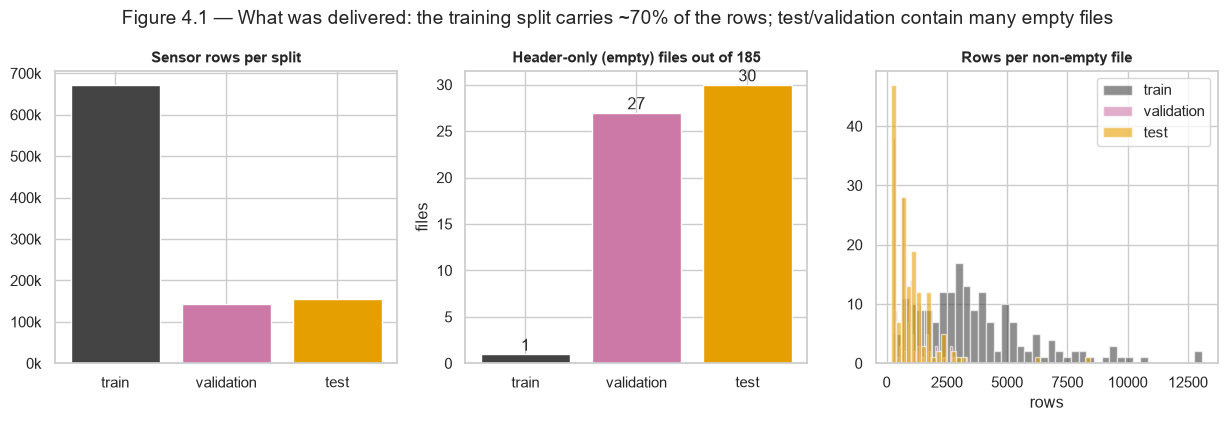

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
s = summary.reindex(['train', 'validation', 'test'])
axes[0].bar(s.index, s['rows'], color=[SPLIT_COLORS[i] for i in s.index])
axes[0].set_title('Sensor rows per split'); axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f'{v/1e3:,.0f}k'))
axes[1].bar(s.index, s['empty_files'], color=[SPLIT_COLORS[i] for i in s.index])
axes[1].set_title('Header-only (empty) files out of 185'); axes[1].set_ylabel('files')
for i, v in enumerate(s['empty_files']): axes[1].text(i, v, str(v), ha='center', va='bottom')
nonempty = inventory[inventory.rows > 0]
for split in ['train', 'validation', 'test']:
    axes[2].hist(nonempty[nonempty.split == split].rows, bins=40, alpha=.6, label=split, color=SPLIT_COLORS[split])
axes[2].set_title('Rows per non-empty file'); axes[2].set_xlabel('rows'); axes[2].legend()
fig.suptitle('Figure 4.1 — What was delivered: the training split carries ~70% of the rows; test/validation contain many empty files', y=1.04)
savefig(fig, '04_01_file_inventory')

**Reading Figure 4.1.** 58 of the 555 files contain only a header. That is a property of how the challenge data was cut into files, not lost data: every labelled run is still present (§5.6). Non-empty test and validation files hold fewer rows, because those splits are about a fifth the size of training and are spread over the same number of files.

## 5. Systematic data-quality audit

The audit runs **before any change** so the baseline profile is honest. Each check answers: is it a data problem, or legitimate behaviour of the process? The findings are collected in an issue table at the end of the section (§5.11).

### 5.1 Schema, types and redundant columns

In [5]:
issues = []   # (issue, evidence, treatment, consequence)
schema = pd.DataFrame({'dtype': raw[EXPECTED_COLS].dtypes.astype(str),
                       'n_unique': raw[EXPECTED_COLS].nunique(),
                       'min': raw[NUMERIC].min(), 'max': raw[NUMERIC].max()}).loc[EXPECTED_COLS]
schema['non_numeric_values'] = [0 if c == 'STAGE' else int(pd.to_numeric(raw[c], errors='coerce').isna().sum() - raw[c].isna().sum()) for c in EXPECTED_COLS]
display(schema)
same = (raw['MACHINE_DATA'] == raw['CHAMBER']).mean()
print(f"MACHINE_ID unique values: {raw['MACHINE_ID'].unique().tolist()} | MACHINE_DATA == CHAMBER in {same:.1%} of rows")
print('STAGE values:', sorted(raw['STAGE'].unique()), '| CHAMBER values:', sorted(raw['CHAMBER'].unique()))
issues.append(('MACHINE_ID constant; MACHINE_DATA duplicates CHAMBER', f'1 machine; equality in {same:.0%} of rows',
               'Both dropped from features', 'None - no information lost'))

,dtype,n_unique,min,max,non_numeric_values
MACHINE_ID,int64,1,2,2,0
MACHINE_DATA,int64,6,1,6,0
TIMESTAMP,float64,701992,4.816e+08,4.873e+08,0
WAFER_ID,int64,2268,-4.23e+09,4.23e+09,0
STAGE,str,2,NaN,NaN,0
CHAMBER,float64,6,1,6,0
USAGE_OF_BACKING_FILM,float64,10974,19.17,1.053e+04,0
USAGE_OF_DRESSER,float64,1715,5.185,771.9,0
USAGE_OF_POLISHING_TABLE,float64,481,0,357,0
USAGE_OF_DRESSER_TABLE,float64,2771,"2,665","4,306",0


MACHINE_ID unique values: [2] | MACHINE_DATA == CHAMBER in 100.0% of rows
STAGE values: ['A', 'B'] | CHAMBER values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0)]


All columns parse as numbers (apart from `STAGE`) once header-only files are excluded. Concatenating the header-only files directly is what made every column look like text when the files were first opened. `MACHINE_ID` is constant and `MACHINE_DATA` is an exact copy of `CHAMBER`.

### 5.2 Missing values — explicit and structural

There are no blank cells. In sensor logs, though, "missing" usually appears as a **structural zero**: a channel that reads exactly 0 because it was not recorded. The left panel counts explicit NaNs. The right panel shows the share of exact zeros per signal and step (`CHAMBER`), where an unexpected wall of zeros would show up.

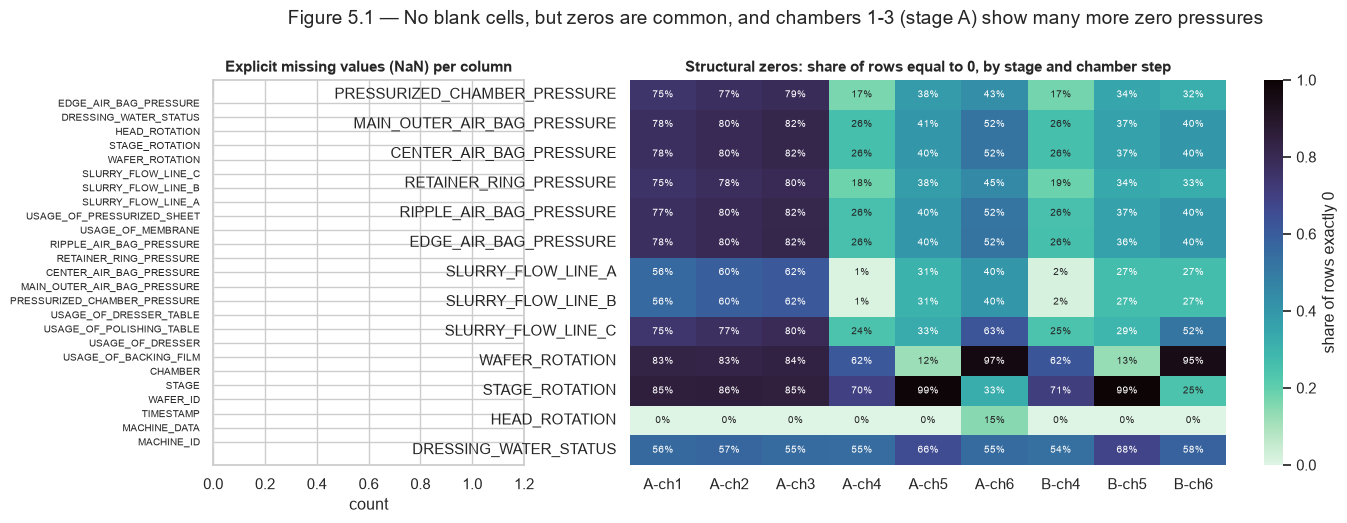

Total NaN cells: 0


In [6]:
nan_counts = raw[EXPECTED_COLS].isna().sum()
zero_share = (raw[PROCESS + ['DRESSING_WATER_STATUS']] == 0).groupby([raw['STAGE'], raw['CHAMBER']]).mean().T
zero_share.columns = [f'{s}-ch{int(c)}' for s, c in zero_share.columns]
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 2.4]})
axes[0].barh(nan_counts.index, nan_counts.values, color='#888')
axes[0].set_title('Explicit missing values (NaN) per column'); axes[0].set_xlabel('count'); axes[0].tick_params(axis='y', labelsize=7)
axes[0].set_xlim(0, max(1, nan_counts.max()) * 1.2)
sns.heatmap(zero_share, ax=axes[1], cmap='mako_r', vmin=0, vmax=1, annot=True, fmt='.0%', annot_kws={'size': 7}, cbar_kws={'label': 'share of rows exactly 0'})
axes[1].set_title('Structural zeros: share of rows equal to 0, by stage and chamber step')
fig.suptitle('Figure 5.1 — No blank cells, but zeros are common, and chambers 1-3 (stage A) show many more zero pressures', y=1.02)
savefig(fig, '05_01_missing_and_zeros')
print('Total NaN cells:', int(nan_counts.sum()))

Zeros are expected for much of each run: the wafer is loaded, rinsed and unloaded while pressure and rotation are off (§7). The noticeably higher share of zero pressure in chambers 1–3 is not expected from the process alone. §5.9 shows that these are whole runs whose pressure channels were never recorded.

### 5.3 Impossible values and broken relationships between fields

In [7]:
checks = {}
checks['negative values in any physical column'] = int((raw[PROCESS + USAGE + ['TIMESTAMP', 'CHAMBER']] < 0).sum().sum())
checks['DRESSING_WATER_STATUS not in {0,1}'] = int((~raw['DRESSING_WATER_STATUS'].isin([0, 1])).sum())
order_bad = raw.groupby(['SPLIT', 'FILE'], sort=False)['TIMESTAMP'].apply(lambda t: int((t.diff() < 0).sum()))
checks['timestamp decreases inside a file'] = int(order_bad.sum())
srt = raw.sort_values(RUN + ['TIMESTAMP'])
dec = {c: int((srt.groupby(RUN)[c].diff() < -1e-9).sum()) for c in USAGE}
for c, v in dec.items(): checks[f'{c} decreases inside a run'] = v
checks['STAGE B rows in chambers 1-3'] = int(((raw.STAGE == 'B') & (raw.CHAMBER <= 3)).sum())
display(pd.Series(checks, name='violations').to_frame())

,violations
negative values in any physical column,0
"DRESSING_WATER_STATUS not in {0,1}",0
timestamp decreases inside a file,1041
USAGE_OF_BACKING_FILM decreases inside a run,0
USAGE_OF_DRESSER decreases inside a run,2
USAGE_OF_POLISHING_TABLE decreases inside a run,2
USAGE_OF_DRESSER_TABLE decreases inside a run,3
USAGE_OF_MEMBRANE decreases inside a run,3
USAGE_OF_PRESSURIZED_SHEET decreases inside a run,3
STAGE B rows in chambers 1-3,0


* No negative values, and the binary flag is clean.
* A few files store samples out of time order. That is harmless once rows are sorted by timestamp (done in §6).
* Usage counters essentially never decrease **within** a run (a handful of cases, consistent with a part being replaced mid-run). Decreases **between** runs are consumable replacements, which are legitimate behaviour (studied in §12).
* Stage B never uses chambers 1–3, so chambers 1–3 belong to stage A only.

### 5.4 Duplicates — at the correct grain

The grain of a sensor row is *(run, timestamp)*. Two kinds of duplicate are possible: **exact copies** (same row stored twice), and **conflicting snapshots** (same run and timestamp, different readings).

In [8]:
exact_dup = raw.drop(columns=['FILE']).duplicated()
dedup = raw.loc[~exact_dup]
same_instant = dedup.duplicated(RUN + ['TIMESTAMP'], keep=False)
conflict_groups = dedup.loc[same_instant].groupby(RUN + ['TIMESTAMP']).ngroups
runs_multi_file = raw.groupby(RUN)['FILE'].nunique()
dup_by_split = pd.DataFrame({'exact duplicate rows': exact_dup.groupby(raw.SPLIT).sum(),
                             'conflicting rows (same run+timestamp)': same_instant.groupby(dedup.SPLIT).sum(),
                             'runs stored in >1 file': (runs_multi_file > 1).groupby(level='SPLIT').sum()})
display(dup_by_split)
print(f'Exact duplicate rows: {exact_dup.sum():,} ({exact_dup.mean():.2%}) | conflicting timestamp groups: {conflict_groups:,}')
ex = dedup.loc[same_instant].sort_values(RUN + ['TIMESTAMP']).head(2)
diffcols = [c for c in PROCESS + USAGE + ['DRESSING_WATER_STATUS'] if ex[c].nunique() > 1]
print('Example of a conflicting pair (only the columns that differ are shown):')
display(ex[RUN + ['TIMESTAMP'] + diffcols])

,exact duplicate rows,conflicting rows (same run+timestamp),runs stored in >1 file
SPLIT,,,
test,98,180,7
train,1819,804,25
validation,434,128,6


Exact duplicate rows: 2,351 (0.24%) | conflicting timestamp groups: 556
Example of a conflicting pair (only the columns that differ are shown):


,SPLIT,WAFER_ID,STAGE,TIMESTAMP,EDGE_AIR_BAG_PRESSURE
695031,test,-4220160694,B,4.824e+08,44.24
695032,test,-4220160694,B,4.824e+08,43.94


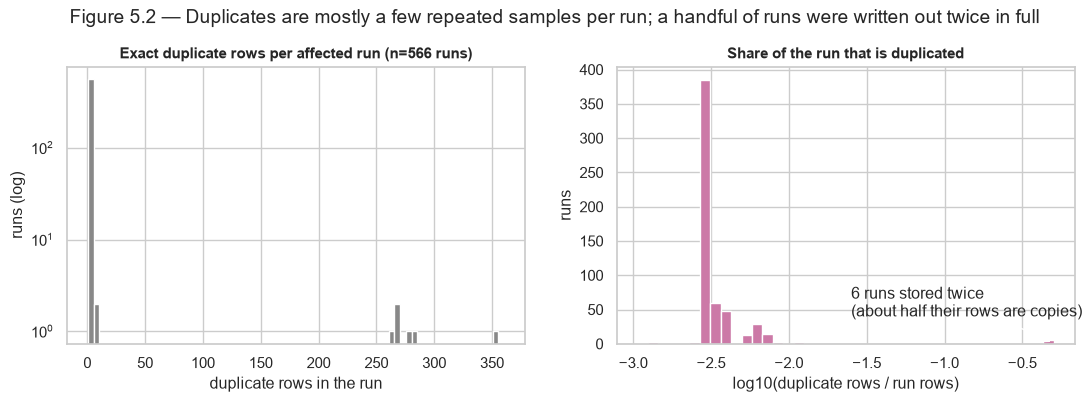

Runs with any exact duplicate: 566 | median duplicate rows per affected run: 1 | runs stored twice in full: 6 (1,713 of the 2,351 duplicate rows)


In [9]:
dup_runs = raw.loc[exact_dup].groupby(RUN).size()
run_rows = raw.groupby(RUN).size()
dup_share = (dup_runs / run_rows.reindex(dup_runs.index))
full_copies = dup_share > 0.4
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].hist(dup_runs.values, bins=np.arange(0.5, dup_runs.max() + 10, 5), color='#888'); axes[0].set_yscale('log')
axes[0].set_title(f'Exact duplicate rows per affected run (n={len(dup_runs)} runs)'); axes[0].set_xlabel('duplicate rows in the run'); axes[0].set_ylabel('runs (log)')
axes[1].hist(np.log10(dup_share.values), bins=40, color='#CC79A7')
axes[1].set_title('Share of the run that is duplicated'); axes[1].set_xlabel('log10(duplicate rows / run rows)'); axes[1].set_ylabel('runs')
axes[1].annotate(f'{int(full_copies.sum())} runs stored twice\n(about half their rows are copies)', xy=(np.log10(0.5), 1), xytext=(-1.6, 40), arrowprops=dict(arrowstyle='->'))
fig.suptitle('Figure 5.2 — Duplicates are mostly a few repeated samples per run; a handful of runs were written out twice in full', y=1.04)
savefig(fig, '05_02_duplicates')
print(f'Runs with any exact duplicate: {len(dup_runs)} | median duplicate rows per affected run: {dup_runs.median():.0f} | '
      f'runs stored twice in full: {int(full_copies.sum())} ({int(dup_runs[full_copies].sum()):,} of the {int(exact_dup.sum()):,} duplicate rows)')

**Interpretation.** Two mechanisms produce exact duplicates. Most affected runs contain only one to a few repeated samples, typical of a logger writing the same record twice. A handful of runs appear twice in full, which accounts for most of the duplicate rows. Either way, the copies carry no new information and removing them changes nothing physically.

The **conflicting snapshots** are two readings stamped with the same instant. They differ only slightly (example above). Averaging them is the least-biased choice: dropping either one would be arbitrary, and they are a tiny fraction of rows.

### 5.5 Keys, grain and overlap between splits

In [10]:
runs = raw.groupby(RUN, sort=False).size().rename('rows').reset_index()
key_in_splits = runs.groupby(['WAFER_ID', 'STAGE'])['SPLIT'].nunique()
wafers = {s: set(runs.loc[runs.SPLIT == s, 'WAFER_ID']) for s in ['train', 'validation', 'test']}
ov = pd.DataFrame({'pair': ['train ∩ validation', 'train ∩ test', 'validation ∩ test'],
                   'shared wafers': [len(wafers['train'] & wafers['validation']), len(wafers['train'] & wafers['test']), len(wafers['validation'] & wafers['test'])]})
stage_mix = runs.groupby('WAFER_ID')['STAGE'].nunique()
print(f'Runs: {len(runs):,} | (WAFER_ID, STAGE) keys in more than one split: {(key_in_splits > 1).sum()}')
print(f'Wafers: {runs.WAFER_ID.nunique():,} | wafers polished at both stages: {(stage_mix == 2).sum():,}')
display(ov)

Runs: 2,829 | (WAFER_ID, STAGE) keys in more than one split: 0
Wafers: 2,268 | wafers polished at both stages: 561


,pair,shared wafers
0,train ∩ validation,115
1,train ∩ test,113
2,validation ∩ test,34


A `(WAFER_ID, STAGE)` run never appears in two splits, so there is no direct leakage. Some **wafers** do appear in several splits: one stage in training, the other in validation or test. Their two runs share the wafer's history (incoming thickness, timing), so it's worth remembering when reading any "generalisation" result. Notebook 2 reports test performance separately for wafers never seen in training.

### 5.6 Joining sensor runs to labels — cardinality checks

In [11]:
join_rows = []
for s, y in labels_raw.items():
    r = runs[runs.SPLIT == s]
    m = r.merge(y, on=['WAFER_ID', 'STAGE'], how='outer', indicator=True, validate='one_to_one')
    join_rows.append({'split': s, 'runs with sensor data': len(r), 'label rows': len(y),
                      'duplicate label keys': int(y.duplicated(['WAFER_ID', 'STAGE']).sum()),
                      'matched': int((m._merge == 'both').sum()), 'runs without label': int((m._merge == 'left_only').sum()),
                      'labels without runs': int((m._merge == 'right_only').sum())})
display(pd.DataFrame(join_rows).set_index('split'))
for s, p in LABEL_COPIES.items():
    a = labels_raw[s].sort_values(['WAFER_ID', 'STAGE']).reset_index(drop=True)
    b = pd.read_csv(p).sort_values(['WAFER_ID', 'STAGE']).reset_index(drop=True)
    print(f'{s}: label copy in the data-set folder identical to answer file -> {a.equals(b)}')

,runs with sensor data,label rows,duplicate label keys,matched,runs without label,labels without runs
split,,,,,,
train,1981,1981,0,1981,0,0
validation,424,424,0,424,0,0
test,424,424,0,424,0,0


validation: label copy in the data-set folder identical to answer file -> True
test: label copy in the data-set folder identical to answer file -> True


Every run has exactly one label, and every label has a run. The join is strictly one-to-one (`validate='one_to_one'` would raise an error otherwise), so no row multiplication is possible. The two shipped copies of the validation and test labels agree.

### 5.7 Time coverage, sampling interval and gaps

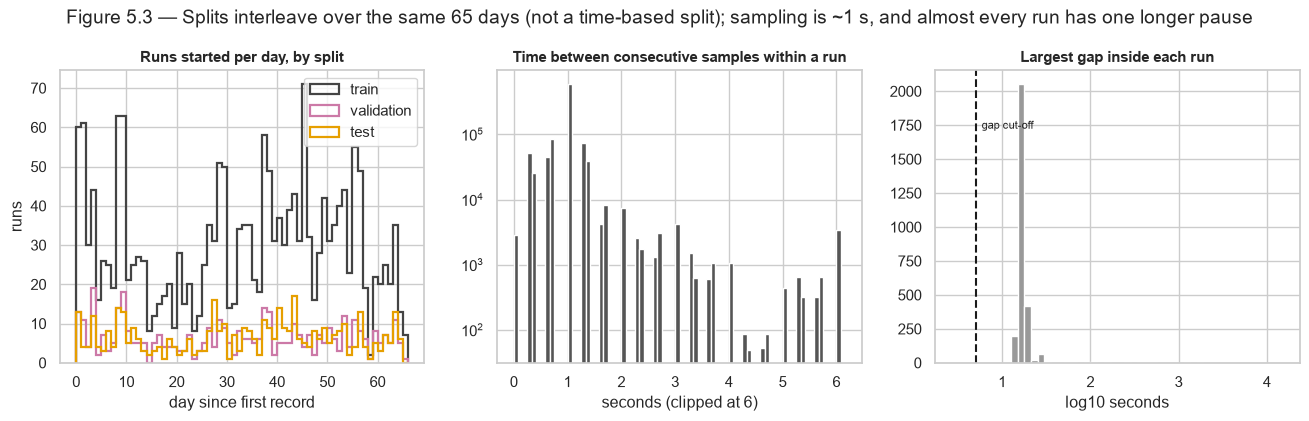

Span: 65.2 days | median sample interval 1.00 s | 99th pct 3.33 s
Runs with at least one gap > 5 s: 2,828 of 2,829 | median largest gap 17 s | samples followed by such a gap: 0.55% | longest pause between run starts: 27.6 h


In [12]:
srt = raw.sort_values(RUN + ['TIMESTAMP'])
dt = srt.groupby(RUN)['TIMESTAMP'].diff().dropna()
t0 = raw['TIMESTAMP'].min()
run_t = raw.groupby(RUN)['TIMESTAMP'].agg(['min', 'max']).reset_index()
run_t['day'] = (run_t['min'] - t0) / 86400
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
bins = np.arange(0, run_t.day.max() + 1, 1)
for s in ['train', 'validation', 'test']:
    axes[0].hist(run_t[run_t.SPLIT == s].day, bins=bins, histtype='step', lw=1.6, label=s, color=SPLIT_COLORS[s])
axes[0].set_title('Runs started per day, by split'); axes[0].set_xlabel('day since first record'); axes[0].set_ylabel('runs'); axes[0].legend()
axes[1].hist(np.clip(dt, 0, 6), bins=np.arange(0, 6.25, 1/12), color='#555')
axes[1].set_yscale('log'); axes[1].set_title('Time between consecutive samples within a run'); axes[1].set_xlabel('seconds (clipped at 6)')
gaps = srt.assign(dt=srt.groupby(RUN)['TIMESTAMP'].diff()).groupby(RUN)['dt'].max()
axes[2].hist(np.log10(gaps.dropna()), bins=50, color='#999'); axes[2].axvline(np.log10(CONFIG['max_dt_seconds']), color='k', ls='--')
axes[2].set_title('Largest gap inside each run'); axes[2].set_xlabel('log10 seconds'); axes[2].text(np.log10(CONFIG['max_dt_seconds']) * 1.05, axes[2].get_ylim()[1] * .8, ' gap cut-off', fontsize=8)
fig.suptitle('Figure 5.3 — Splits interleave over the same 65 days (not a time-based split); sampling is ~1 s, and almost every run has one longer pause', y=1.04)
savefig(fig, '05_03_time_coverage')
quiet = np.diff(np.sort(run_t['min'].values)) / 3600
print(f'Span: {run_t.day.max():.1f} days | median sample interval {dt.median():.2f} s | 99th pct {dt.quantile(.99):.2f} s')
print(f'Runs with at least one gap > {CONFIG["max_dt_seconds"]:.0f} s: {(gaps > CONFIG["max_dt_seconds"]).sum():,} of {len(gaps):,} | '
      f'median largest gap {gaps.median():.0f} s | samples followed by such a gap: {(dt > CONFIG["max_dt_seconds"]).mean():.2%} | longest pause between run starts: {quiet.max():.1f} h')

**Sampling.** Samples arrive about once per second. Almost every run also contains one pause of tens of seconds; §7 shows it falls where the wafer moves between process steps. Time integrals (§8) skip any interval longer than 5 s, so these pauses are not counted as polishing time.

**Implication.** The three splits were drawn from the *same* period, interleaved in time. They are not past/future blocks. Because removal rate drifts (§11), a run's time-neighbours in the training set are very informative. Test performance on this benchmark is therefore an *interpolation-in-time* result, and it would overstate how a model performs on truly future production.

### 5.8 Run length and abnormally long runs

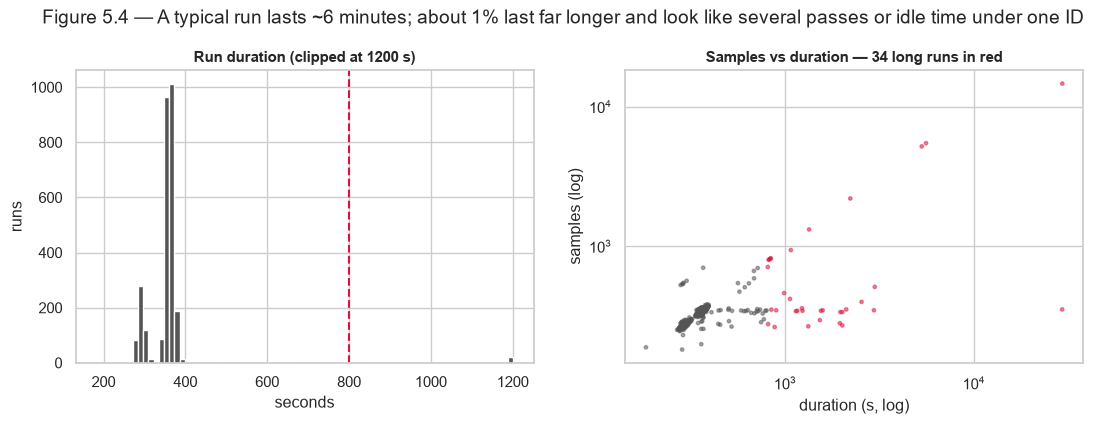

,count,mean,std,min,1%,5%,50%,95%,99%,max
duration_s,"2,829",388.1,793.4,182.7,279.3,287,359.7,380,836.6,2.935e+04


In [13]:
rl = srt.groupby(RUN).agg(duration=('TIMESTAMP', lambda t: t.max() - t.min()), samples=('TIMESTAMP', 'size')).reset_index()
long = rl.duration > CONFIG['long_run_seconds']
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(np.clip(rl.duration, 0, 1200), bins=80, color='#555'); axes[0].axvline(CONFIG['long_run_seconds'], color='crimson', ls='--')
axes[0].set_title('Run duration (clipped at 1200 s)'); axes[0].set_xlabel('seconds'); axes[0].set_ylabel('runs')
axes[1].scatter(rl.duration, rl.samples, s=6, alpha=.5, c=np.where(long, 'crimson', '#555'))
axes[1].set_xscale('log'); axes[1].set_yscale('log'); axes[1].set_xlabel('duration (s, log)'); axes[1].set_ylabel('samples (log)')
axes[1].set_title(f'Samples vs duration — {long.sum()} long runs in red')
fig.suptitle('Figure 5.4 — A typical run lasts ~6 minutes; about 1% last far longer and look like several passes or idle time under one ID', y=1.04)
savefig(fig, '05_04_run_length')
display(rl.duration.describe(percentiles=[.01, .05, .5, .95, .99]).to_frame('duration_s').T)

Most runs last 280–380 s. A small group lasts from 800 s up to about 8 hours. The right panel shows that **most of them have a normal number of samples (~300)** spread over a much longer span: one long idle pause inside the record, not extra polishing. Only a few have many more samples, consistent with several passes logged under one ID. They are kept but flagged (`LONG_RUN`). Their whole-run statistics (duration, sample count) are not comparable to normal runs, which is why most features are computed on **active polishing time** only (§8). §16 re-runs the key results without them.

### 5.9 Runs whose process signals were never recorded

,pressure NO / rotation NO,pressure NO / rotation yes,pressure yes / rotation NO,pressure yes / rotation yes
MODE,,,,
A-123,234,42,16,216
A-456,0,0,0,1148
B-456,0,0,0,1173


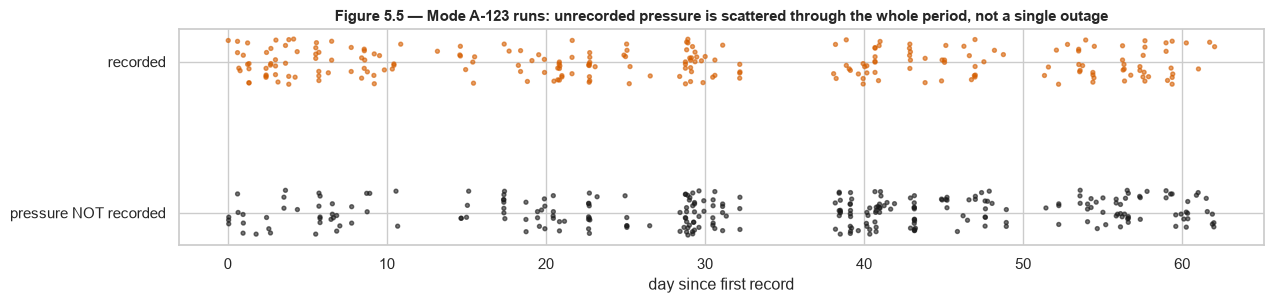

In [14]:
per_run = srt.groupby(RUN).agg(first_chamber=('CHAMBER', 'first'), p_max=('PRESSURIZED_CHAMBER_PRESSURE', 'max'),
                               wr_max=('WAFER_ROTATION', 'max'), start=('TIMESTAMP', 'min')).reset_index()
per_run['MODE'] = np.where(per_run.STAGE == 'B', 'B-456', np.where(per_run.first_chamber <= 3, 'A-123', 'A-456'))
per_run['pressure_recorded'] = per_run.p_max > 0
per_run['rotation_recorded'] = per_run.wr_max > 0
tab = pd.crosstab(per_run.MODE, [per_run.pressure_recorded, per_run.rotation_recorded])
tab.columns = [f'pressure {"yes" if a else "NO"} / rotation {"yes" if b else "NO"}' for a, b in tab.columns]
display(tab)
a123 = per_run[per_run.MODE == 'A-123'].sort_values('start')
fig, ax = plt.subplots(figsize=(14, 2.8))
ax.scatter((a123.start - t0) / 86400, np.where(a123.pressure_recorded, 1, 0) + RNG.uniform(-.15, .15, len(a123)), s=8,
           c=np.where(a123.pressure_recorded, MODE_COLORS['A-123'], 'k'), alpha=.6)
ax.set_yticks([0, 1]); ax.set_yticklabels(['pressure NOT recorded', 'recorded']); ax.set_xlabel('day since first record')
ax.set_title('Figure 5.5 — Mode A-123 runs: unrecorded pressure is scattered through the whole period, not a single outage')
savefig(fig, '05_05_unrecorded_runs')

**Interpretation.** About half of the A-123 runs (stage A, chambers 1–3) have pressure, and usually rotation too, at exactly zero for the whole run, yet they still have valid removal-rate labels. Polishing obviously happened, so these zeros mean **not recorded**, not "no pressure". The runs are spread across the whole period, so this looks like a logging configuration for that chamber set rather than an outage.

**Decision.** For these runs, pressure and rotation features become **missing** (NaN), not 0, and the runs get a flag (`SIGNALS_RECORDED = False`). Keeping the zeros would invent a regime with "zero pressure but full removal", which would distort every pressure–rate relationship.

### 5.10 The target: impossible and extreme labels

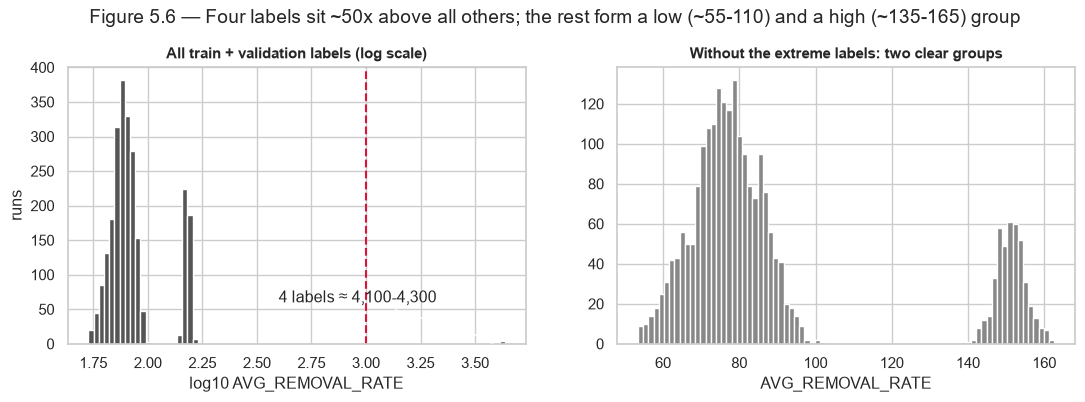

,WAFER_ID,STAGE,AVG_REMOVAL_RATE,SPLIT
892,1834206730,A,"4,202",train
894,1834206944,A,"4,182",train
897,1834206972,A,"4,129",train
1675,2058207580,A,"4,326",train


In [15]:
lab_dev = pd.concat([labels_raw['train'].assign(SPLIT='train'), labels_raw['validation'].assign(SPLIT='validation')], ignore_index=True)
thr = CONFIG['label_outlier_threshold']
big = lab_dev[lab_dev.AVG_REMOVAL_RATE > thr]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].hist(np.log10(lab_dev.AVG_REMOVAL_RATE), bins=80, color='#555'); axes[0].axvline(np.log10(thr), color='crimson', ls='--')
axes[0].set_xlabel('log10 AVG_REMOVAL_RATE'); axes[0].set_ylabel('runs'); axes[0].set_title('All train + validation labels (log scale)')
axes[0].annotate(f'{len(big)} labels ≈ 4,100-4,300', xy=(np.log10(4200), 1), xytext=(2.6, 60), arrowprops=dict(arrowstyle='->'))
ok = lab_dev[lab_dev.AVG_REMOVAL_RATE <= thr]
axes[1].hist(ok.AVG_REMOVAL_RATE, bins=80, color='#888'); axes[1].set_xlabel('AVG_REMOVAL_RATE'); axes[1].set_title('Without the extreme labels: two clear groups')
fig.suptitle('Figure 5.6 — Four labels sit ~50x above all others; the rest form a low (~55-110) and a high (~135-165) group', y=1.04)
savefig(fig, '05_06_label_extremes')
display(big)

Four training labels are about 4,100–4,300, roughly 50 times the overall median. All four are mode A-123 runs (§7), where they are still about 28 times the typical value. Nothing physical produces a 50-fold jump in removal rate while every sensor stays normal. These look like unit or scale errors, for example a value in Å/min next to nm/min, though the dataset can't confirm that. They are **flagged** (`LABEL_OUTLIER`), excluded from statistics and model fitting, and kept in the cleaned table. §16 checks what happens if they are kept.

### 5.11 Issue register

In [16]:
n_unrec = int((~per_run.pressure_recorded).sum())
issues += [
    ('Header-only CSV files', f"{int((inventory.rows == 0).sum())} of {len(inventory)} files", 'Skipped when reading; counted in manifest', 'None - all labelled runs present'),
    ('Samples out of time order in some files', f"{checks['timestamp decreases inside a file']} decreases", 'Sort by timestamp within run', 'None'),
    ('Exact duplicate sensor rows', f"{int(exact_dup.sum()):,} rows ({exact_dup.mean():.2%})", 'Removed', 'None - copies of the same snapshot'),
    ('Conflicting snapshots (same run + timestamp)', f"{conflict_groups:,} timestamp groups", 'Numeric readings averaged', 'Negligible smoothing of a few samples'),
    ('Runs whose process signals were not recorded', f"{n_unrec} runs, all mode A-123", 'Pressure/rotation features set to NaN; SIGNALS_RECORDED flag', 'Process analysis of A-123 rests on ~half its runs'),
    ('Abnormally long runs', f"{int(long.sum())} runs > {CONFIG['long_run_seconds']:.0f} s", 'Kept, LONG_RUN flag; features use active time only', 'Whole-run duration features unreliable for them'),
    ('Extreme labels', f"{len(big)} train labels > {thr:,.0f}", 'Kept, LABEL_OUTLIER flag; excluded from stats and fitting', 'Results shown with/without in §16'),
    ('Wafers shared between splits (different stage)', f"{ov['shared wafers'].sum()} wafer-pairs", 'Kept (official split); reported separately in Notebook 2', 'Mild optimism in benchmark results'),
    ('Splits interleaved in time', '3 splits span the same 65 days', 'Time-aware analysis; drift feature built from training labels only', 'Benchmark ≠ future performance'),
]
issue_table = pd.DataFrame(issues, columns=['Issue', 'Evidence', 'Treatment', 'Possible consequence'])
issue_table.to_csv(OUT / 'issue_register.csv', index=False)
display(issue_table)

,Issue,Evidence,Treatment,Possible consequence
0,MACHINE_ID constant; MACHINE_DATA duplicates C...,1 machine; equality in 100% of rows,Both dropped from features,None - no information lost
1,Header-only CSV files,58 of 555 files,Skipped when reading; counted in manifest,None - all labelled runs present
2,Samples out of time order in some files,1041 decreases,Sort by timestamp within run,None
3,Exact duplicate sensor rows,"2,351 rows (0.24%)",Removed,None - copies of the same snapshot
4,Conflicting snapshots (same run + timestamp),556 timestamp groups,Numeric readings averaged,Negligible smoothing of a few samples
5,Runs whose process signals were not recorded,"276 runs, all mode A-123",Pressure/rotation features set to NaN; SIGNALS...,Process analysis of A-123 rests on ~half its runs
6,Abnormally long runs,34 runs > 800 s,"Kept, LONG_RUN flag; features use active time ...",Whole-run duration features unreliable for them
7,Extreme labels,"4 train labels > 1,000","Kept, LABEL_OUTLIER flag; excluded from stats ...",Results shown with/without in §16
8,Wafers shared between splits (different stage),262 wafer-pairs,Kept (official split); reported separately in ...,Mild optimism in benchmark results
9,Splits interleaved in time,3 splits span the same 65 days,Time-aware analysis; drift feature built from ...,Benchmark ≠ future performance


## 6. Cleaning decisions, cleaning log and before/after validation

Every transformation is applied to a **copy** of the raw data and recorded in a log, with the number of records affected. Nothing is dropped automatically. In particular, outliers are flagged rather than deleted, and missing signals become NaN instead of being imputed with zeros.

In [17]:
log = []
def log_step(step, action, reason, n):
    log.append({'step': step, 'action': action, 'reason': reason, 'records_affected': int(n)})

clean = raw.copy()
before_rows = len(clean)
log_step('6.1', 'Skipped header-only files', 'No rows to read', (inventory.rows == 0).sum())
d = clean.drop(columns=['FILE']).duplicated()
clean = clean.loc[~d]
log_step('6.2', 'Removed exact duplicate sensor rows', 'Same snapshot stored twice (file overlap)', d.sum())
dupmask = clean.duplicated(RUN + ['TIMESTAMP'], keep=False)
agg = {c: 'mean' for c in NUMERIC if c not in ('TIMESTAMP', 'WAFER_ID')}
agg.update({'FILE': 'first', 'CHAMBER': 'first', 'DRESSING_WATER_STATUS': 'first',   # categorical: never average
            'MACHINE_DATA': 'first', 'MACHINE_ID': 'first'})
merged = clean.loc[dupmask].groupby(RUN + ['TIMESTAMP'], as_index=False).agg(agg)
clean = pd.concat([clean.loc[~dupmask], merged], ignore_index=True)
log_step('6.3', 'Averaged conflicting snapshots (numeric signals; step and flags kept from the first reading)', 'Two readings of the same instant', dupmask.sum())
clean = clean.sort_values(RUN + ['TIMESTAMP']).reset_index(drop=True)
log_step('6.4', 'Sorted samples by timestamp within run', 'Files stored some samples out of order', checks['timestamp decreases inside a file'])
clean = clean.drop(columns=['MACHINE_ID', 'MACHINE_DATA'])
log_step('6.5', 'Dropped MACHINE_ID and MACHINE_DATA', 'Constant / exact copy of CHAMBER', len(clean))

# --- validation of the cleaned sample-level table ---
assert not clean.duplicated(RUN + ['TIMESTAMP']).any(), 'duplicate (run, timestamp) remains'
assert (clean.groupby(RUN)['TIMESTAMP'].diff().dropna() > 0).all(), 'timestamps not strictly increasing'
assert clean.groupby(RUN).ngroups == runs.shape[0], 'a run was lost'
assert (clean[PROCESS + USAGE].min() >= 0).all(), 'negative physical reading'
assert set(clean['CHAMBER'].unique()) <= {1, 2, 3, 4, 5, 6}, 'non-integer process step'
cleaning_log = pd.DataFrame(log)
display(cleaning_log)
print(f'Sensor rows: {before_rows:,} -> {len(clean):,} ({before_rows - len(clean):,} removed, {1 - len(clean)/before_rows:.2%}) | runs kept: {clean.groupby(RUN).ngroups:,} of {runs.shape[0]:,}')

,step,action,reason,records_affected
0,6.1,Skipped header-only files,No rows to read,58
1,6.2,Removed exact duplicate sensor rows,Same snapshot stored twice (file overlap),2351
2,6.3,Averaged conflicting snapshots (numeric signal...,Two readings of the same instant,1112
3,6.4,Sorted samples by timestamp within run,Files stored some samples out of order,1041
4,6.5,Dropped MACHINE_ID and MACHINE_DATA,Constant / exact copy of CHAMBER,970247


Sensor rows: 973,154 -> 970,247 (2,907 removed, 0.30%) | runs kept: 2,829 of 2,829


In [18]:
ba = pd.DataFrame({'mean_before': raw[PROCESS + USAGE].mean(), 'mean_after': clean[PROCESS + USAGE].mean()})
ba['change_%'] = 100 * (ba.mean_after / ba.mean_before - 1)
ba['KS_statistic'] = [stats.ks_2samp(raw[c].sample(50000, random_state=1), clean[c].sample(50000, random_state=1)).statistic for c in ba.index]
display(ba)
print('Largest change in any signal mean: {:.3f}% -> cleaning did not alter the signal distributions.'.format(ba['change_%'].abs().max()))

,mean_before,mean_after,change_%,KS_statistic
PRESSURIZED_CHAMBER_PRESSURE,49.61,49.68,0.1367,0.0054
MAIN_OUTER_AIR_BAG_PRESSURE,154.1,154.3,0.1453,0.00392
CENTER_AIR_BAG_PRESSURE,39.82,39.88,0.1459,0.00418
RETAINER_RING_PRESSURE,"1,211","1,212",0.09236,0.0047
RIPPLE_AIR_BAG_PRESSURE,5.908,5.916,0.1408,0.00334
EDGE_AIR_BAG_PRESSURE,28.3,28.34,0.1458,0.00332
SLURRY_FLOW_LINE_A,4.207,4.211,0.0906,0.00228
SLURRY_FLOW_LINE_B,0.7175,0.7182,0.08629,0.00228
SLURRY_FLOW_LINE_C,247.4,247.7,0.131,0.00186
WAFER_ROTATION,12.62,12.63,0.1234,0.0063


Largest change in any signal mean: 0.146% -> cleaning did not alter the signal distributions.


## 7. Anatomy of a polishing run

**Question.** What happens during a run, and which samples correspond to actual polishing? Run-level features are only meaningful if they summarise the right part of the run.

**Method.** Collapse each run's `CHAMBER` sequence into its ordered steps, then plot the signals of typical runs over time with the steps shaded.

In [19]:
clean['RUN_ID'] = clean.groupby(RUN, sort=False).ngroup()
seq = clean.groupby('RUN_ID')['CHAMBER'].apply(lambda c: '-'.join(str(int(x)) for x in c[c.ne(c.shift())]))
run_info = clean.groupby('RUN_ID').agg(SPLIT=('SPLIT', 'first'), WAFER_ID=('WAFER_ID', 'first'), STAGE=('STAGE', 'first'),
                                       min_chamber=('CHAMBER', 'min')).join(seq.rename('STEP_SEQUENCE'))
run_info['MODE'] = np.where(run_info.STAGE == 'B', 'B-456', np.where(run_info.min_chamber <= 3, 'A-123', 'A-456'))
clean['MODE'] = clean['RUN_ID'].map(run_info['MODE'])
seq_tab = run_info.groupby(['MODE', 'STEP_SEQUENCE']).size().rename('runs').reset_index().sort_values(['MODE', 'runs'], ascending=[True, False])
display(seq_tab)
print('Share of runs following the standard three-step sequence:',
      f"{run_info.STEP_SEQUENCE.isin(['1-2-3', '4-5-6']).mean():.1%}")

,MODE,STEP_SEQUENCE,runs
0,A-123,1-2-3,507
1,A-123,2-3-1-2-3,1
3,A-456,4-5-6,1147
2,A-456,4,1
5,B-456,4-5-6,1170
4,B-456,4,1
6,B-456,4-6,1
7,B-456,5-6-4-5-6,1


Share of runs following the standard three-step sequence: 99.8%


**Finding.** `CHAMBER` is not a fixed location. It is the **process step** the wafer is in, and a run moves through three steps in order. Stage A runs follow one of two routes, 1→2→3 or 4→5→6; stage B always follows 4→5→6. This gives three **operating modes**, used throughout the notebook: **A-123**, **A-456** and **B-456**. Over 99% of runs follow the standard sequence, and the rare exceptions repeat steps.

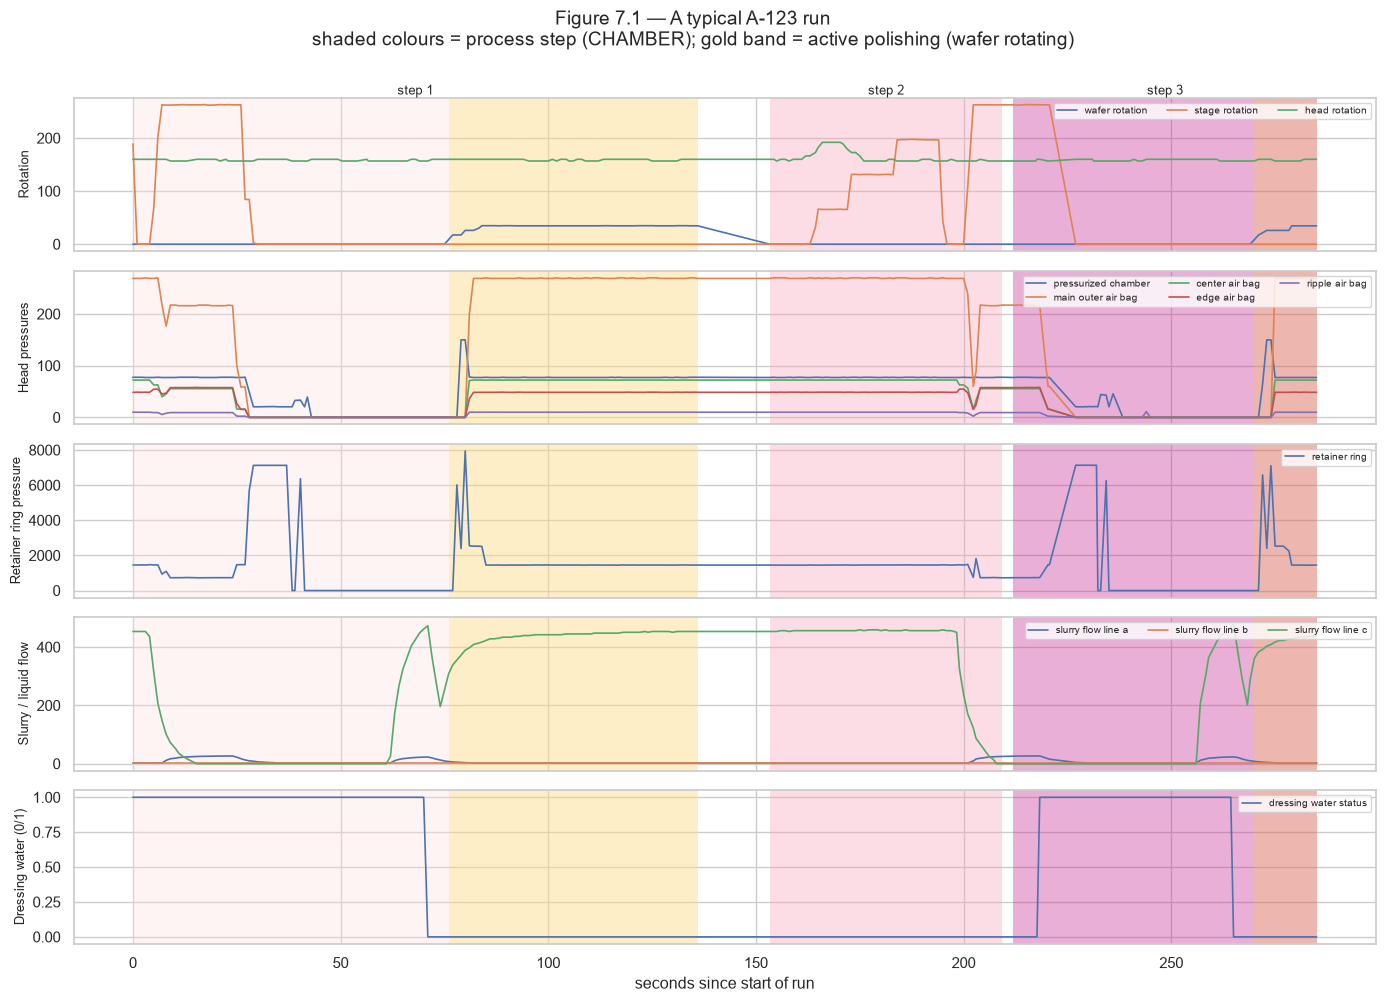

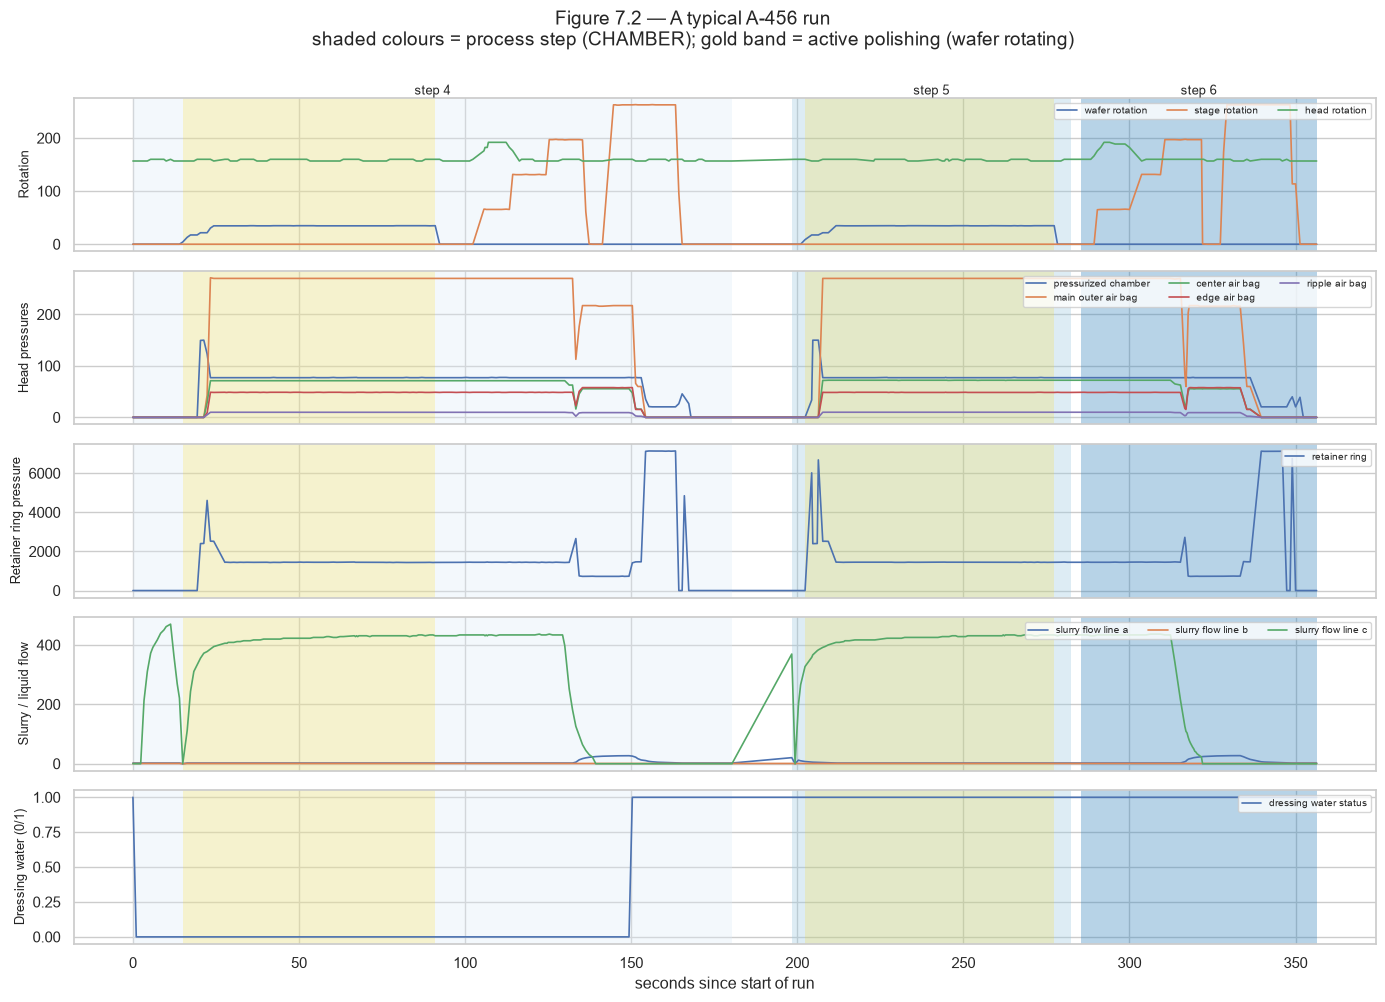

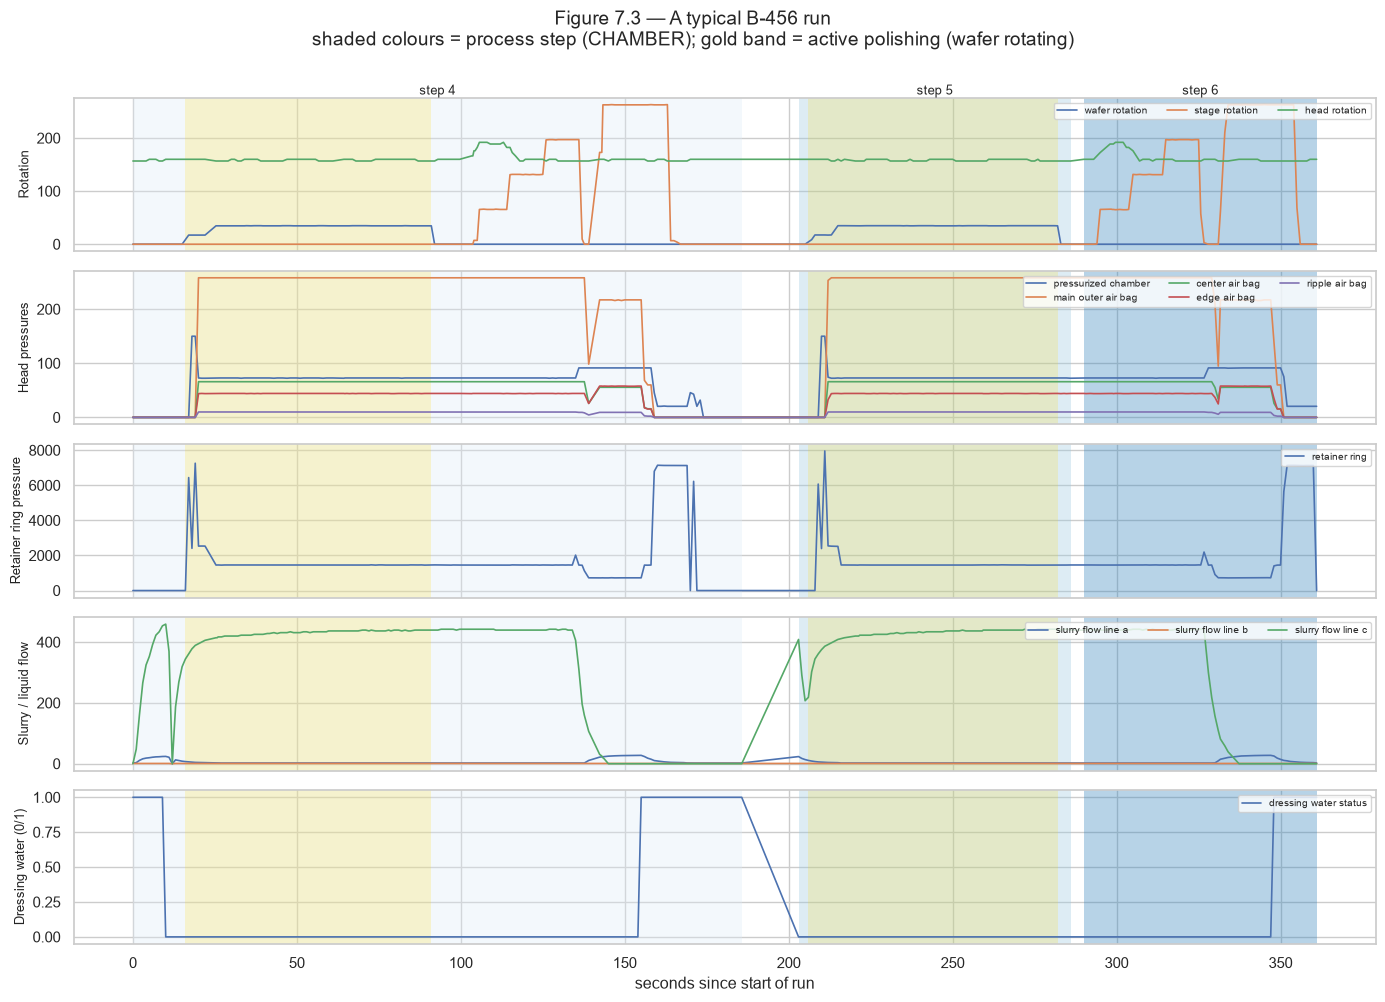

In [20]:
dtp = clean.groupby('RUN_ID')['TIMESTAMP'].diff()
clean['DT'] = dtp.where(dtp <= CONFIG['max_dt_seconds'], 0).fillna(0)
clean['ACTIVE'] = clean['WAFER_ROTATION'] > 0

def plot_run(run_id, title, fname):
    r = clean[clean.RUN_ID == run_id]
    t = r.TIMESTAMP - r.TIMESTAMP.min()
    panels = [('Rotation', ['WAFER_ROTATION', 'STAGE_ROTATION', 'HEAD_ROTATION']),
              ('Head pressures', ['PRESSURIZED_CHAMBER_PRESSURE', 'MAIN_OUTER_AIR_BAG_PRESSURE', 'CENTER_AIR_BAG_PRESSURE', 'EDGE_AIR_BAG_PRESSURE', 'RIPPLE_AIR_BAG_PRESSURE']),
              ('Retainer ring pressure', ['RETAINER_RING_PRESSURE']),
              ('Slurry / liquid flow', ['SLURRY_FLOW_LINE_A', 'SLURRY_FLOW_LINE_B', 'SLURRY_FLOW_LINE_C']),
              ('Dressing water (0/1)', ['DRESSING_WATER_STATUS'])]
    fig, axes = plt.subplots(len(panels), 1, figsize=(14, 10), sharex=True)
    step_cols = {1: '#fde0dd', 2: '#fa9fb5', 3: '#c51b8a', 4: '#deebf7', 5: '#9ecae1', 6: '#3182bd'}
    changes = np.r_[0, np.flatnonzero(np.diff(r.CHAMBER.values)) + 1, len(r)]
    for ax, (name, cols) in zip(axes, panels):
        for a, b in zip(changes[:-1], changes[1:]):
            ch = int(r.CHAMBER.iloc[a])
            ax.axvspan(t.iloc[a], t.iloc[b - 1], color=step_cols[ch], alpha=.35, lw=0)
            if ax is axes[0]: ax.text((t.iloc[a] + t.iloc[b - 1]) / 2, 1.02, f'step {ch}', transform=ax.get_xaxis_transform(), ha='center', fontsize=9)
        act = r.ACTIVE.values
        for c in cols: ax.plot(t, r[c], lw=1.2, label=c.replace('_PRESSURE', '').replace('_', ' ').lower())
        ax.fill_between(t, 0, 1, where=act, transform=ax.get_xaxis_transform(), color='gold', alpha=.18, lw=0)
        ax.set_ylabel(name, fontsize=9); ax.legend(loc='upper right', fontsize=7, ncol=3)
    axes[-1].set_xlabel('seconds since start of run')
    fig.suptitle(title + '\nshaded colours = process step (CHAMBER); gold band = active polishing (wafer rotating)', y=1.0)
    fig.tight_layout(); savefig(fig, fname)

info = run_info.join(clean.groupby('RUN_ID')['PRESSURIZED_CHAMBER_PRESSURE'].max().rename('pmax'))
std = info[info.STEP_SEQUENCE.isin(['1-2-3', '4-5-6']) & (info.SPLIT == 'train')]
for i, mode in enumerate(MODES):
    cand = std[(std.MODE == mode) & (std.pmax > 0)]
    plot_run(cand.index[len(cand) // 2], f'Figure 7.{i + 1} — A typical {mode} run', f'07_0{i + 1}_run_{mode}')

**Reading Figures 7.1–7.3.** Each run cycles between **polishing** (gold bands) and **non-polishing** phases:

* During polishing, the wafer spins at a fixed set-point of about 35, the head zones are pressurised, and slurry line C flows at about 400–450. These three always switch on together, so `WAFER_ROTATION > 0` is a reliable marker of active polishing.
* Between polishing phases, the `STAGE_ROTATION` channel ramps through fixed levels (≈66 → 131 → 197 → 262) while the wafer is not rotating. Short bursts follow where line A flow jumps, pressure is released and retainer-ring pressure spikes to about 7,000. That pattern reads as rinse / unload / conditioning activity rather than material removal (an inference: the signal semantics are not documented).
* `HEAD_ROTATION` stays near 157–160 almost all the time and carries little information.

**Consequence for features.** Averaging a signal over the *whole* run mixes polishing with idle and rinse phases, and the mix varies between runs. Process features are therefore computed **over active-polishing samples only**, and the length of active polishing becomes a feature in its own right.

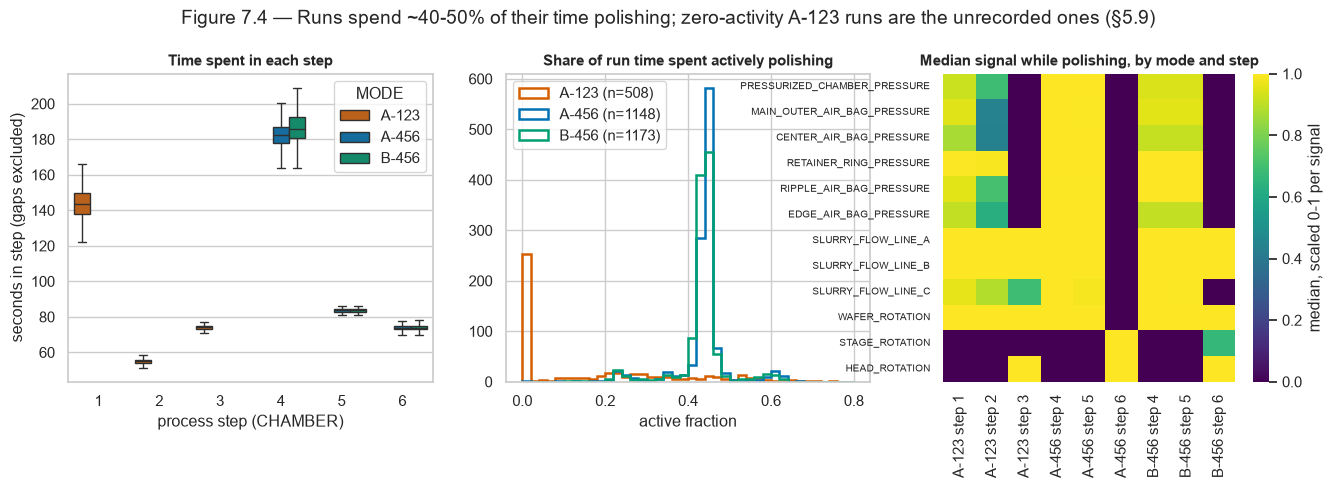

,count,mean,std,min,5%,50%,95%,max
MODE,,,,,,,,
A-123,508,0.1656,0.1993,0,0,0.04317,0.5559,0.7494
A-456,"1,148",0.438,0.06353,0.01036,0.3183,0.4444,0.4953,0.6601
B-456,"1,173",0.4344,0.05797,0.1069,0.3397,0.4397,0.4902,0.6397


Share of all active polishing time that happens in each step:


CHAMBER,1,2,3,4,5,6
MODE,,,,,,
A-123,0.528,0.209,0.262,NaN,NaN,NaN
A-456,NaN,NaN,NaN,0.474,0.506,0.02
B-456,NaN,NaN,NaN,0.477,0.498,0.025


In [21]:
step_time = clean.groupby(['RUN_ID', 'CHAMBER'])['DT'].sum().unstack(fill_value=0)
step_time['MODE'] = run_info['MODE']
act_frac = ((clean.DT * clean.ACTIVE).groupby(clean.RUN_ID).sum() / clean.groupby('RUN_ID').DT.sum().clip(lower=1e-9)).rename('active_fraction')
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
st_long = step_time.reset_index().melt(id_vars=['RUN_ID', 'MODE'], var_name='step', value_name='seconds')
st_long = st_long[st_long.seconds > 0]
st_long['step'] = st_long['step'].astype(int)
sns.boxplot(data=st_long, x='step', y='seconds', hue='MODE', hue_order=MODES, palette=MODE_COLORS, showfliers=False, ax=axes[0])
axes[0].set_xlabel('process step (CHAMBER)'); axes[0].set_ylabel('seconds in step (gaps excluded)')
axes[0].set_title('Time spent in each step')
for mode in MODES:
    v = act_frac[run_info.MODE == mode]
    axes[1].hist(v, bins=np.linspace(0, .8, 41), histtype='step', lw=1.8, color=MODE_COLORS[mode], label=f'{mode} (n={len(v)})')
axes[1].set_title('Share of run time spent actively polishing'); axes[1].set_xlabel('active fraction'); axes[1].legend()
med = clean[clean.ACTIVE].groupby(['MODE', 'CHAMBER'])[PROCESS].median()
med = (med - med.min()) / (med.max() - med.min()).replace(0, 1)
med.index = [f'{m} step {int(c)}' for m, c in med.index]
sns.heatmap(med.T, ax=axes[2], cmap='viridis', cbar_kws={'label': 'median, scaled 0-1 per signal'})
axes[2].set_title('Median signal while polishing, by mode and step'); axes[2].tick_params(axis='y', labelsize=7)
fig.suptitle('Figure 7.4 — Runs spend ~40-50% of their time polishing; zero-activity A-123 runs are the unrecorded ones (§5.9)', y=1.04)
savefig(fig, '07_04_step_time_activity')
display(act_frac.groupby(run_info.MODE).describe(percentiles=[.05, .5, .95]))
act_step = (clean['DT'] * clean['ACTIVE']).groupby([clean['MODE'], clean['CHAMBER']]).sum()
print('Share of all active polishing time that happens in each step:')
display((act_step / act_step.groupby(level=0).transform('sum')).unstack().round(3))

Runs spend roughly 40–50% of their recorded time polishing. The spike at an active fraction of 0 is almost entirely A-123 runs whose rotation was not recorded (§5.9). In A-456 and B-456 runs, polishing happens in two phases, one in step 4 and one in step 5; step 6 is conditioning only. A-123 runs polish in all three of their steps, about half of it in step 1. While polishing, the three modes look alike on most signals. §10 tests that formally.

## 8. Run-level metrics and feature engineering

The label describes a **run**, so all sensor information is aggregated to one row per run. Each feature has a written definition (also exported to `outputs/feature_dictionary.csv`):

| Feature | Definition | Why |
|---|---|---|
| `MODE` | `B-456` if stage B; else `A-123` if the run uses chambers 1–3; else `A-456` | Operating regime (§7, §10) |
| `T_START`, `DAY` | First timestamp of the run; days since the first run in the dataset | Drift analysis |
| `DURATION`, `N_SAMPLES` | Last − first timestamp; number of samples | Data-quality context (unreliable for long runs) |
| `ACTIVE_TIME` | Σ Δt over samples with `WAFER_ROTATION > 0`, where Δt ≤ 5 s | Polishing time — Preston: removal ∝ time |
| `ACTIVE_FRACTION` | `ACTIVE_TIME` / Σ Δt | Recipe/flow structure |
| `<signal>_ACT_MEAN`, `<signal>_ACT_STD` | Mean / std of each process signal over active samples | Settings during polishing and their stability |
| `<signal>_RUN_MAX` | Max over the whole run | Captures the rinse/unload spikes |
| `U_<consumable>_START`, `U_<consumable>_DELTA` | Usage counter at run start; increase during the run | Wear state; usage rate |
| `PV_CHAMBER`, `PV_MAIN` | Mean over active samples of pressure × wafer rotation (chamber pressure; main/outer air bag) | Preston-style energy proxy (§14) |
| `PV_DOSE` | Σ chamber pressure × wafer rotation × Δt over active samples | Cumulative Preston proxy |
| `DRESS_FRACTION` | Share of time with dressing water on | Pad conditioning |
| `SIGNALS_RECORDED` | Run has non-zero chamber pressure **and** wafer rotation | Missing-signal flag (§5.9) |
| `LONG_RUN`, `LABEL_OUTLIER` | Duration > 800 s; label > 1,000 | Quality flags (§5.8, §5.10) |

**Missing rather than zero.** Pressure features are set to NaN for runs without recorded pressure, and active-phase features are NaN for runs without recorded rotation. No target information enters any feature. The one label-derived quantity, the drift level of §11, is built only from *other training runs* and is stored in a separate column.

In [22]:
act = clean[clean.ACTIVE]
g_all, g_act = clean.groupby('RUN_ID'), act.groupby('RUN_ID')
F = run_info[['SPLIT', 'WAFER_ID', 'STAGE', 'MODE', 'STEP_SEQUENCE']].copy()
F['T_START'] = g_all['TIMESTAMP'].min()
F['DAY'] = (F['T_START'] - F['T_START'].min()) / 86400
F['DURATION'] = g_all['TIMESTAMP'].max() - F['T_START']
F['N_SAMPLES'] = g_all.size()
F['ACTIVE_TIME'] = (clean['DT'] * clean['ACTIVE']).groupby(clean['RUN_ID']).sum()
F['ACTIVE_FRACTION'] = act_frac
for c in PROCESS:
    F[f'{c}_ACT_MEAN'] = g_act[c].mean()
    F[f'{c}_ACT_STD'] = g_act[c].std()
    F[f'{c}_RUN_MAX'] = g_all[c].max()
for c in USAGE:
    short = c.replace('USAGE_OF_', 'U_')
    F[f'{short}_START'] = g_all[c].first()
    F[f'{short}_DELTA'] = g_all[c].last() - g_all[c].first()
pv_c = act['PRESSURIZED_CHAMBER_PRESSURE'] * act['WAFER_ROTATION']
pv_m = act['MAIN_OUTER_AIR_BAG_PRESSURE'] * act['WAFER_ROTATION']
F['PV_CHAMBER'] = pv_c.groupby(act['RUN_ID']).mean()
F['PV_MAIN'] = pv_m.groupby(act['RUN_ID']).mean()
F['PV_DOSE'] = (pv_c * act['DT']).groupby(act['RUN_ID']).sum()
F['DRESS_FRACTION'] = (clean['DT'] * clean['DRESSING_WATER_STATUS']).groupby(clean['RUN_ID']).sum() / g_all['DT'].sum().replace(0, np.nan)

pressure_rec = g_all['PRESSURIZED_CHAMBER_PRESSURE'].max() > 0
rotation_rec = g_all['WAFER_ROTATION'].max() > 0
F['SIGNALS_RECORDED'] = pressure_rec & rotation_rec
p_cols = [c for c in F if any(c.startswith(p) for p in SIGNALS_P)] + ['PV_CHAMBER', 'PV_MAIN', 'PV_DOSE']
F.loc[~pressure_rec, p_cols] = np.nan
act_cols = [c for c in F if c.endswith(('_ACT_MEAN', '_ACT_STD'))] + ['ACTIVE_TIME', 'ACTIVE_FRACTION', 'PV_CHAMBER', 'PV_MAIN', 'PV_DOSE']
F.loc[~rotation_rec, act_cols] = np.nan
F['LONG_RUN'] = F['DURATION'] > CONFIG['long_run_seconds']

labels = pd.concat([y.assign(SPLIT=s) for s, y in labels_raw.items()], ignore_index=True)
F = F.reset_index().merge(labels, on=['SPLIT', 'WAFER_ID', 'STAGE'], how='left', validate='one_to_one')
F['LABEL_OUTLIER'] = F['AVG_REMOVAL_RATE'] > CONFIG['label_outlier_threshold']
assert F['AVG_REMOVAL_RATE'].notna().all() and len(F) == clean.RUN_ID.nunique()

FEATURES = [c for c in F if c.endswith(('_ACT_MEAN', '_ACT_STD', '_RUN_MAX', '_START', '_DELTA'))
            or c in ('ACTIVE_TIME', 'ACTIVE_FRACTION', 'PV_CHAMBER', 'PV_MAIN', 'PV_DOSE', 'DRESS_FRACTION', 'DURATION', 'N_SAMPLES')]
FEATURES = [c for c in FEATURES if c != 'T_START']
const = [c for c in FEATURES if F[c].nunique(dropna=True) <= 1]
FEATURES = [c for c in FEATURES if c not in const]
print(f'Run-level table: {F.shape[0]:,} runs x {len(FEATURES)} numeric features (+ ids, flags, label) | constant features dropped: {const}')
miss = F[FEATURES].isna().groupby(F['MODE']).mean().T
display(miss[(miss > 0).any(axis=1)].round(3).head(12))

Run-level table: 2,829 runs x 56 numeric features (+ ids, flags, label) | constant features dropped: []


MODE,A-123,A-456,B-456
ACTIVE_TIME,0.492,0,0
ACTIVE_FRACTION,0.492,0,0
PRESSURIZED_CHAMBER_PRESSURE_ACT_MEAN,0.575,0,0
PRESSURIZED_CHAMBER_PRESSURE_ACT_STD,0.575,0,0
PRESSURIZED_CHAMBER_PRESSURE_RUN_MAX,0.543,0,0
MAIN_OUTER_AIR_BAG_PRESSURE_ACT_MEAN,0.575,0,0
MAIN_OUTER_AIR_BAG_PRESSURE_ACT_STD,0.575,0,0
MAIN_OUTER_AIR_BAG_PRESSURE_RUN_MAX,0.543,0,0
CENTER_AIR_BAG_PRESSURE_ACT_MEAN,0.575,0,0
CENTER_AIR_BAG_PRESSURE_ACT_STD,0.575,0,0


In [23]:
desc = []
for c in FEATURES:
    base = c.rsplit('_', 2 if c.endswith(('_ACT_MEAN', '_ACT_STD', '_RUN_MAX')) else 1)[0]
    if c.endswith('_ACT_MEAN'): d = f'Mean of {base} over active polishing samples'
    elif c.endswith('_ACT_STD'): d = f'Std of {base} over active polishing samples'
    elif c.endswith('_RUN_MAX'): d = f'Max of {base} over the whole run'
    elif c.endswith('_START'): d = f'Usage counter {c[2:-6]} at run start'
    elif c.endswith('_DELTA'): d = f'Increase of usage counter {c[2:-6]} during the run'
    else: d = {'ACTIVE_TIME': 'Seconds of active polishing (gaps > 5 s excluded)', 'ACTIVE_FRACTION': 'Active time / recorded time',
               'PV_CHAMBER': 'Mean chamber pressure x wafer rotation while polishing', 'PV_MAIN': 'Mean main/outer air-bag pressure x wafer rotation while polishing',
               'PV_DOSE': 'Integral of chamber pressure x wafer rotation over active time', 'DRESS_FRACTION': 'Share of time with dressing water on',
               'DURATION': 'Run length in seconds', 'N_SAMPLES': 'Number of samples'}.get(c, '')
    desc.append({'feature': c, 'definition': d, 'missing_share': F[c].isna().mean()})
feature_dictionary = pd.DataFrame(desc)
feature_dictionary.to_csv(OUT / 'feature_dictionary.csv', index=False)
print('Feature dictionary written:', len(feature_dictionary), 'rows')

Feature dictionary written: 56 rows


**Validation of the run table.** It has exactly one row per run (asserted above). Labels joined one-to-one. Missingness is confined to the A-123 runs with unrecorded signals, plus standard deviations of single-sample groups.

Several usage counters are suspected duplicates of one another (§12). That is checked below rather than assumed.

In [24]:
dev = F[F.SPLIT.isin(['train', 'validation']) & ~F.LABEL_OUTLIER].copy()     # analysis set: no test labels, no extreme labels
tr = dev[dev.SPLIT == 'train']; va = dev[dev.SPLIT == 'validation']
TARGET = 'AVG_REMOVAL_RATE'
uc = [c for c in F if c.endswith('_START') and c.startswith('U_')]
rho_u = F[uc].corr(method='spearman')
print('Spearman correlation between usage counters at run start (all runs):')
display(rho_u.round(3))

Spearman correlation between usage counters at run start (all runs):


,U_BACKING_FILM_START,U_DRESSER_START,U_POLISHING_TABLE_START,U_DRESSER_TABLE_START,U_MEMBRANE_START,U_PRESSURIZED_SHEET_START
U_BACKING_FILM_START,1,-0.003,0.011,0.087,1,1
U_DRESSER_START,-0.003,1,-0.035,0.008,-0.003,-0.003
U_POLISHING_TABLE_START,0.011,-0.035,1,0.01,0.011,0.011
U_DRESSER_TABLE_START,0.087,0.008,0.01,1,0.087,0.087
U_MEMBRANE_START,1,-0.003,0.011,0.087,1,1
U_PRESSURIZED_SHEET_START,1,-0.003,0.011,0.087,1,1


`U_BACKING_FILM`, `U_MEMBRANE` and `U_PRESSURIZED_SHEET` are perfectly rank-correlated (ρ = 1). They are the same counter on different scales, so they count as **one** piece of information: a model or a correlation table that lists all three triple-counts a single signal. From here on only `U_BACKING_FILM` represents this group.

## 9. The target: average removal rate

All analyses from here use the **analysis set**: training and validation runs, without the four extreme labels. Test labels stay unused.

### 9.1 Distribution, overall and by mode

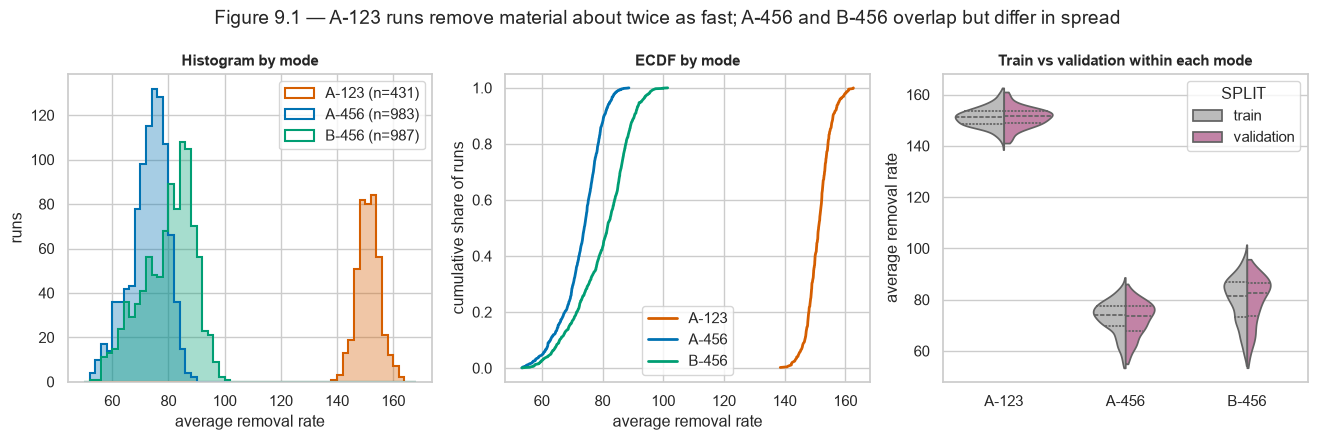

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
bins = np.arange(50, 170, 2.0)
for m in MODES:
    v = dev.loc[dev.MODE == m, TARGET]
    axes[0].hist(v, bins=bins, histtype='stepfilled', alpha=.35, color=MODE_COLORS[m])
    axes[0].hist(v, bins=bins, histtype='step', lw=1.5, color=MODE_COLORS[m], label=f'{m} (n={len(v)})')
axes[0].set_xlabel('average removal rate'); axes[0].set_ylabel('runs'); axes[0].legend(); axes[0].set_title('Histogram by mode')
for m in MODES:
    v = np.sort(dev.loc[dev.MODE == m, TARGET].values)
    axes[1].plot(v, np.arange(1, len(v) + 1) / len(v), color=MODE_COLORS[m], lw=2, label=m)
axes[1].set_xlabel('average removal rate'); axes[1].set_ylabel('cumulative share of runs'); axes[1].set_title('ECDF by mode'); axes[1].legend()
sns.violinplot(data=dev, x='MODE', y=TARGET, hue='SPLIT', order=MODES, split=True, inner='quartile', ax=axes[2],
               palette={'train': '#bbbbbb', 'validation': SPLIT_COLORS['validation']}, cut=0)
axes[2].set_title('Train vs validation within each mode'); axes[2].set_ylabel('average removal rate'); axes[2].set_xlabel('')
fig.suptitle('Figure 9.1 — A-123 runs remove material about twice as fast; A-456 and B-456 overlap but differ in spread', y=1.04)
savefig(fig, '09_01_target_distribution')

In [26]:
def boot_ci(values, func=np.median, draws=CONFIG['bootstrap_draws'], alpha=.05, rng=None):
    rng = rng or np.random.default_rng(CONFIG['seed'])
    v = np.asarray(values)
    idx = rng.integers(0, len(v), size=(draws, len(v)))
    b = func(v[idx], axis=1)
    return np.quantile(b, [alpha / 2, 1 - alpha / 2])

rows = []
for m in MODES:
    v = dev.loc[dev.MODE == m, TARGET].values
    lo, hi = boot_ci(v)
    rows.append({'mode': m, 'runs': len(v), 'median': np.median(v), 'median 95% CI': f'[{lo:.2f}, {hi:.2f}]', 'mean': v.mean(),
                 'std': v.std(ddof=1), 'CV %': 100 * v.std(ddof=1) / v.mean(), 'IQR': np.subtract(*np.quantile(v, [.75, .25])),
                 'skew': stats.skew(v), 'min': v.min(), 'max': v.max()})
target_table = pd.DataFrame(rows).set_index('mode')
display(target_table)

kw = stats.kruskal(*[dev.loc[dev.MODE == m, TARGET] for m in MODES])
pairs = []
for a, b in [('A-123', 'A-456'), ('A-123', 'B-456'), ('A-456', 'B-456')]:
    x, y = dev.loc[dev.MODE == a, TARGET], dev.loc[dev.MODE == b, TARGET]
    u = stats.mannwhitneyu(x, y)
    pairs.append({'comparison': f'{a} vs {b}', 'median difference': x.median() - y.median(),
                  "Cliff's delta": 2 * u.statistic / (len(x) * len(y)) - 1, 'p (Mann-Whitney)': u.pvalue})
pairs = pd.DataFrame(pairs)
pairs['p (Holm-adjusted)'] = holm(pairs['p (Mann-Whitney)'])
print(f'Kruskal-Wallis across modes: H = {kw.statistic:.0f}, p = {kw.pvalue:.1e}')
display(pairs)

,runs,median,median 95% CI,mean,std,CV %,IQR,skew,min,max
mode,,,,,,,,,,
A-123,431,151.2,"[150.80, 151.65]",151.2,3.927,2.597,5.047,0.07066,138.6,162.6
A-456,983,73.99,"[73.52, 74.44]",72.95,6.685,9.164,8.168,-0.6079,53.43,88.7
B-456,987,81.57,"[80.90, 82.43]",79.91,9.212,11.53,13.39,-0.5155,53.48,101.5


Kruskal-Wallis across modes: H = 1284, p = 1.8e-279


,comparison,median difference,Cliff's delta,p (Mann-Whitney),p (Holm-adjusted)
0,A-123 vs A-456,77.18,1,2.365e-197,4.731e-197
1,A-123 vs B-456,69.6,1,1.355e-197,4.066e-197
2,A-456 vs B-456,-7.583,-0.4738,4.624e-74,4.624e-74


**Interpretation.**
* **A-123 is a different regime.** Its median removal rate is about double that of A-456 and B-456. Cliff's δ ≈ 1 means essentially every A-123 run is faster than every other run: the groups don't overlap at all.
* **A-456 vs B-456**: B-456 has a higher median and a wider spread. The effect is moderate, not a separate regime.
* Spread differs by mode: the coefficient of variation is about 3% in A-123, 9% in A-456 and 12% in B-456. The two slower modes are left-skewed, with a tail of unusually slow runs. Validation mirrors training within each mode, so the split is not biased by mode.

**Implication.** Pooling all runs would make any feature that tracks mode look like a strong predictor. Every later analysis is therefore done **within mode**.

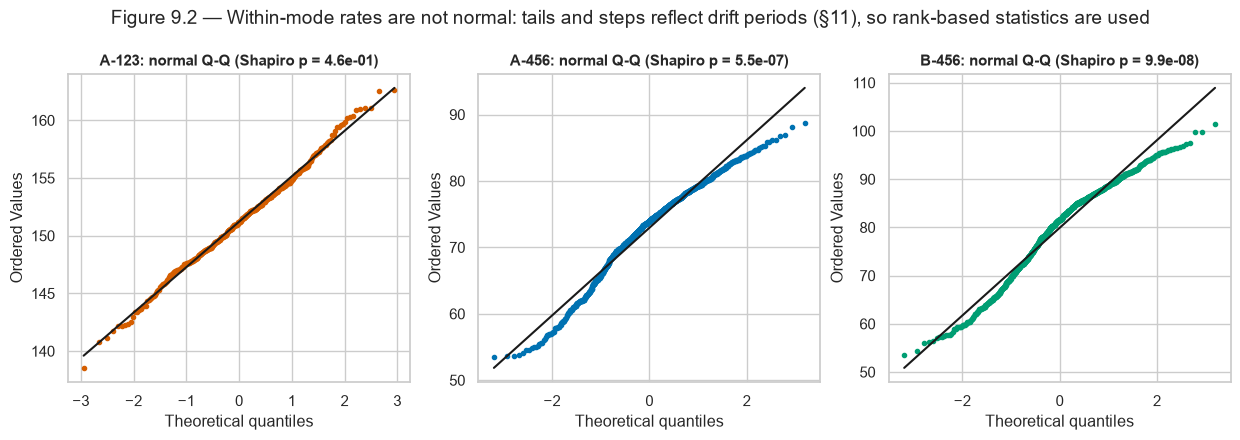

,train n,validation n,KS statistic,p
mode,,,,
A-123,364,67,0.06872,0.9324
A-456,798,185,0.09281,0.1399
B-456,815,172,0.04868,0.8701


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m in zip(axes, MODES):
    v = dev.loc[dev.MODE == m, TARGET]
    stats.probplot(v, dist='norm', plot=ax)
    ax.get_lines()[0].set(markersize=3, color=MODE_COLORS[m]); ax.get_lines()[1].set(color='k')
    ax.set_title(f'{m}: normal Q-Q (Shapiro p = {stats.shapiro(v.sample(min(len(v), 500), random_state=1)).pvalue:.1e})')
fig.suptitle('Figure 9.2 — Within-mode rates are not normal: tails and steps reflect drift periods (§11), so rank-based statistics are used', y=1.04)
savefig(fig, '09_02_qq')

ks = []
for m in MODES:
    r = stats.ks_2samp(tr.loc[tr.MODE == m, TARGET], va.loc[va.MODE == m, TARGET])
    ks.append({'mode': m, 'train n': int((tr.MODE == m).sum()), 'validation n': int((va.MODE == m).sum()), 'KS statistic': r.statistic, 'p': r.pvalue})
display(pd.DataFrame(ks).set_index('mode'))

The Q-Q plots bend away from the straight line, so the within-mode rates are not normal. That is why rank-based tools are used for associations (Spearman, Mann-Whitney) and bootstrap intervals for uncertainty, rather than methods that assume normality. The train-vs-validation KS tests find no material distribution difference within any mode.

## 10. Q1 — Why is one group of runs twice as fast?

**Question.** A-123 runs remove material about twice as fast as A-456 runs at the same stage. Do the recorded process settings explain that?

**Method.** Compare the medians of each polishing-phase setting between A-123 and A-456. Only runs with recorded signals are used, and each comparison carries a bootstrap 95% CI. If the settings explained the difference, at least some would differ by a factor comparable to the 2× difference in rate.

,quantity,A-123 median,A-456 median,ratio A-123 / A-456,ci_lo,ci_hi,n A-123
0,AVG_REMOVAL_RATE,150.9,73.99,2.039,2.021,2.053,185
1,PRESSURIZED_CHAMBER_PRESSURE,63.66,74.66,0.853,0.733,0.921,185
2,MAIN_OUTER_AIR_BAG_PRESSURE,222.4,244.6,0.909,0.754,0.953,185
3,CENTER_AIR_BAG_PRESSURE,54.16,65.21,0.831,0.733,0.901,185
4,EDGE_AIR_BAG_PRESSURE,38.54,44.02,0.875,0.778,0.931,185
5,RIPPLE_AIR_BAG_PRESSURE,8.403,9.068,0.927,0.817,0.966,185
6,RETAINER_RING_PRESSURE,"1,450","1,514",0.958,0.867,0.989,185
7,SLURRY_FLOW_LINE_A,2.222,2.377,0.935,0.927,0.942,185
8,SLURRY_FLOW_LINE_B,0.899,0.909,0.989,0.966,1,185
9,SLURRY_FLOW_LINE_C,383.7,421,0.911,0.712,0.978,185


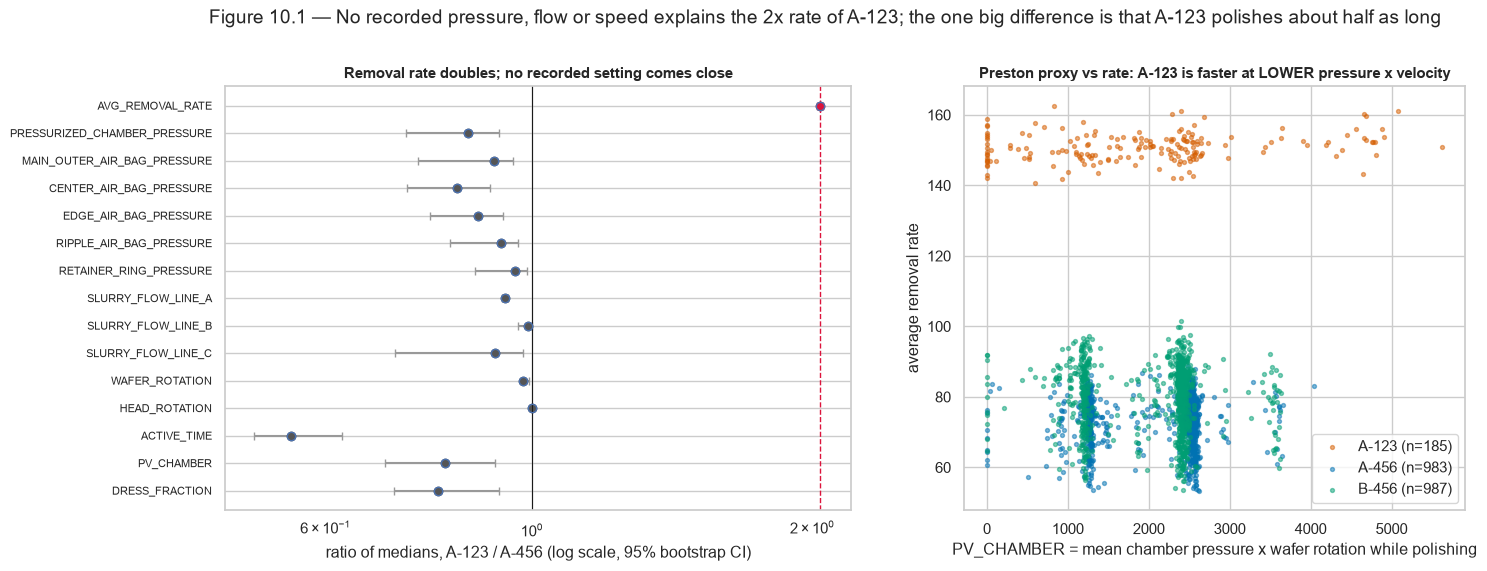

In [28]:
KEY_SETTINGS = ['PRESSURIZED_CHAMBER_PRESSURE_ACT_MEAN', 'MAIN_OUTER_AIR_BAG_PRESSURE_ACT_MEAN', 'CENTER_AIR_BAG_PRESSURE_ACT_MEAN',
                'EDGE_AIR_BAG_PRESSURE_ACT_MEAN', 'RIPPLE_AIR_BAG_PRESSURE_ACT_MEAN', 'RETAINER_RING_PRESSURE_ACT_MEAN',
                'SLURRY_FLOW_LINE_A_ACT_MEAN', 'SLURRY_FLOW_LINE_B_ACT_MEAN', 'SLURRY_FLOW_LINE_C_ACT_MEAN', 'WAFER_ROTATION_ACT_MEAN',
                'HEAD_ROTATION_ACT_MEAN', 'ACTIVE_TIME', 'PV_CHAMBER', 'DRESS_FRACTION']
rec = dev[dev.SIGNALS_RECORDED]
rng = np.random.default_rng(CONFIG['seed'])
rows = []
for c in [TARGET] + KEY_SETTINGS:
    a = rec.loc[rec.MODE == 'A-123', c].dropna().values; b = rec.loc[rec.MODE == 'A-456', c].dropna().values
    ia = rng.integers(0, len(a), (CONFIG['bootstrap_draws'], len(a))); ib = rng.integers(0, len(b), (CONFIG['bootstrap_draws'], len(b)))
    ratio = np.median(a[ia], axis=1) / np.median(b[ib], axis=1)
    rows.append({'quantity': c.replace('_ACT_MEAN', ''), 'A-123 median': np.median(a), 'A-456 median': np.median(b),
                 'ratio A-123 / A-456': np.median(a) / np.median(b), 'ci_lo': np.quantile(ratio, .025), 'ci_hi': np.quantile(ratio, .975),
                 'n A-123': len(a)})
ratios = pd.DataFrame(rows)
display(ratios.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1.25, 1]})
r = ratios.iloc[::-1]
cols = ['crimson' if q == TARGET else '#555' for q in r.quantity]
axes[0].errorbar(r['ratio A-123 / A-456'], range(len(r)), xerr=[r['ratio A-123 / A-456'] - r.ci_lo, r.ci_hi - r['ratio A-123 / A-456']],
                 fmt='o', ecolor='#999', capsize=3, mfc='none')
for i, (v, c) in enumerate(zip(r['ratio A-123 / A-456'], cols)): axes[0].plot(v, i, 'o', color=c)
axes[0].axvline(1, color='k', lw=.8); axes[0].axvline(ratios.loc[0, 'ratio A-123 / A-456'], color='crimson', ls='--', lw=1)
axes[0].set_yticks(range(len(r))); axes[0].set_yticklabels(r.quantity, fontsize=8); axes[0].set_xscale('log')
axes[0].set_xlabel('ratio of medians, A-123 / A-456 (log scale, 95% bootstrap CI)')
axes[0].set_title('Removal rate doubles; no recorded setting comes close')
for m in MODES:
    s_ = rec[rec.MODE == m]
    axes[1].scatter(s_.PV_CHAMBER, s_[TARGET], s=8, alpha=.5, color=MODE_COLORS[m], label=f'{m} (n={len(s_)})')
axes[1].set_xlabel('PV_CHAMBER = mean chamber pressure x wafer rotation while polishing'); axes[1].set_ylabel('average removal rate')
axes[1].set_title('Preston proxy vs rate: A-123 is faster at LOWER pressure x velocity'); axes[1].legend()
fig.suptitle('Figure 10.1 — No recorded pressure, flow or speed explains the 2x rate of A-123; the one big difference is that A-123 polishes about half as long', y=1.02)
savefig(fig, '10_01_mode_settings')

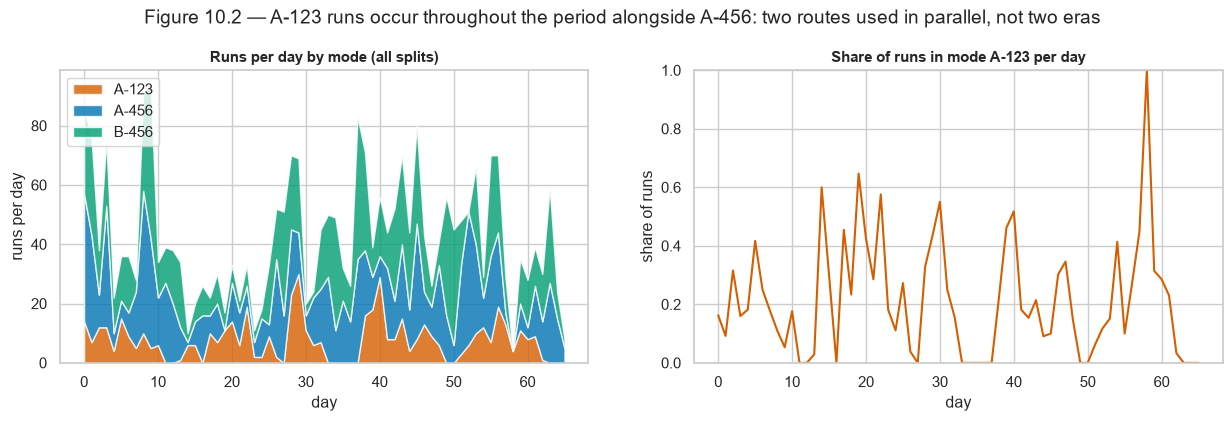

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
daily = F.assign(day=F.DAY.astype(int)).groupby(['day', 'MODE']).size().unstack(fill_value=0).reindex(columns=MODES)
axes[0].stackplot(daily.index, daily.T.values, colors=[MODE_COLORS[m] for m in MODES], labels=MODES, alpha=.8)
axes[0].set_xlabel('day'); axes[0].set_ylabel('runs per day'); axes[0].legend(loc='upper left'); axes[0].set_title('Runs per day by mode (all splits)')
share = daily['A-123'] / daily.sum(axis=1)
axes[1].plot(share.index, share.values, color=MODE_COLORS['A-123']); axes[1].set_ylim(0, 1)
axes[1].set_xlabel('day'); axes[1].set_ylabel('share of runs'); axes[1].set_title('Share of runs in mode A-123 per day')
fig.suptitle('Figure 10.2 — A-123 runs occur throughout the period alongside A-456: two routes used in parallel, not two eras', y=1.04)
savefig(fig, '10_02_mode_over_time')

In [30]:
amount = rec.assign(rate_x_time=rec[TARGET] * rec.ACTIVE_TIME).groupby('MODE').agg(
    runs=(TARGET, 'size'), median_rate=(TARGET, 'median'), median_active_time=('ACTIVE_TIME', 'median'),
    median_rate_x_active_time=('rate_x_time', 'median'))
amount['within-mode Spearman(active time, rate)'] = [stats.spearmanr(rec.loc[rec.MODE == m, 'ACTIVE_TIME'], rec.loc[rec.MODE == m, TARGET]).statistic for m in amount.index]
display(amount.round(3))

,runs,median_rate,median_active_time,median_rate_x_active_time,"within-mode Spearman(active time, rate)"
MODE,,,,,
A-123,185,150.9,83.67,1.269e+04,-0.046
A-456,983,73.99,152,1.107e+04,-0.025
B-456,987,81.57,152,1.22e+04,-0.035


**Interpretation (Q1).**
* The removal-rate ratio between A-123 and A-456 is about 2.0. Every recorded pressure, flow and speed differs between the modes by 15% or less, and in the *wrong* direction: A-123 polishes with somewhat **lower** head pressures and a lower pressure × velocity product. In Preston terms, A-123 should be slower, not faster.
* The one large difference is **polishing time**. A-123 runs polish for roughly half as long (ratio ≈ 0.55), so the median of rate × active time, a proxy for total material removed, is similar in all three modes. That fits recipes designed to remove a similar amount, with the A-123 route reaching it about twice as fast. Within a mode, though, active time does not track removal rate (ρ ≈ 0 in the table above). Time is fixed by the recipe rather than adjusted run by run, so it describes the A-123 regime rather than explaining it.
* The two routes run in parallel throughout the 65 days (Figure 10.2), so the difference is not an era effect such as a pre/post maintenance shift.
* **Most likely explanation (hypothesis, not testable here):** the 1-2-3 route uses a polishing condition that is not in the log, such as a different pad, slurry chemistry, or the layer being polished. The usage counters are shared by all modes (Figure 12.1), so the route does not use separately counted consumables. The data has no field that records the difference.

**Implication.** Mode must be an explicit input to any model, or models must be fitted per mode. A physical equation built on recorded pressure and speed cannot reproduce the 2× gap. Notebook 2 therefore lets the equation include a mode term.

**Caveat.** The comparison uses only the A-123 runs whose signals were recorded, fewer than half of them. If logging failure were linked to unusual settings, those runs would not be representative. Their removal rates differ from the unrecorded runs by less than 1 unit, or 0.5% (§16), so any bias is small.

## 11. Q2 — Does removal rate drift over time?

**Question.** Is removal rate stable over the 65 days, or does it wander, so that runs close in time resemble each other?

**Method.** Order each mode's runs by start time, then plot the rate with a rolling median, the autocorrelation function (ACF), and a lag-1 scatter. To quantify how much recent history explains, define a **drift level** for every run: the median rate of the K = 10 time-nearest *training* runs of the same mode, excluding the run itself and the extreme labels. This uses only training labels, so it is a legitimate predictor for validation and test runs too, given those labels exist at prediction time.

Dresser replaced on days [ 6.  26.8 46. ] | backing film replaced on days [ 1.1 15.3 31.7 47.8 64.2]


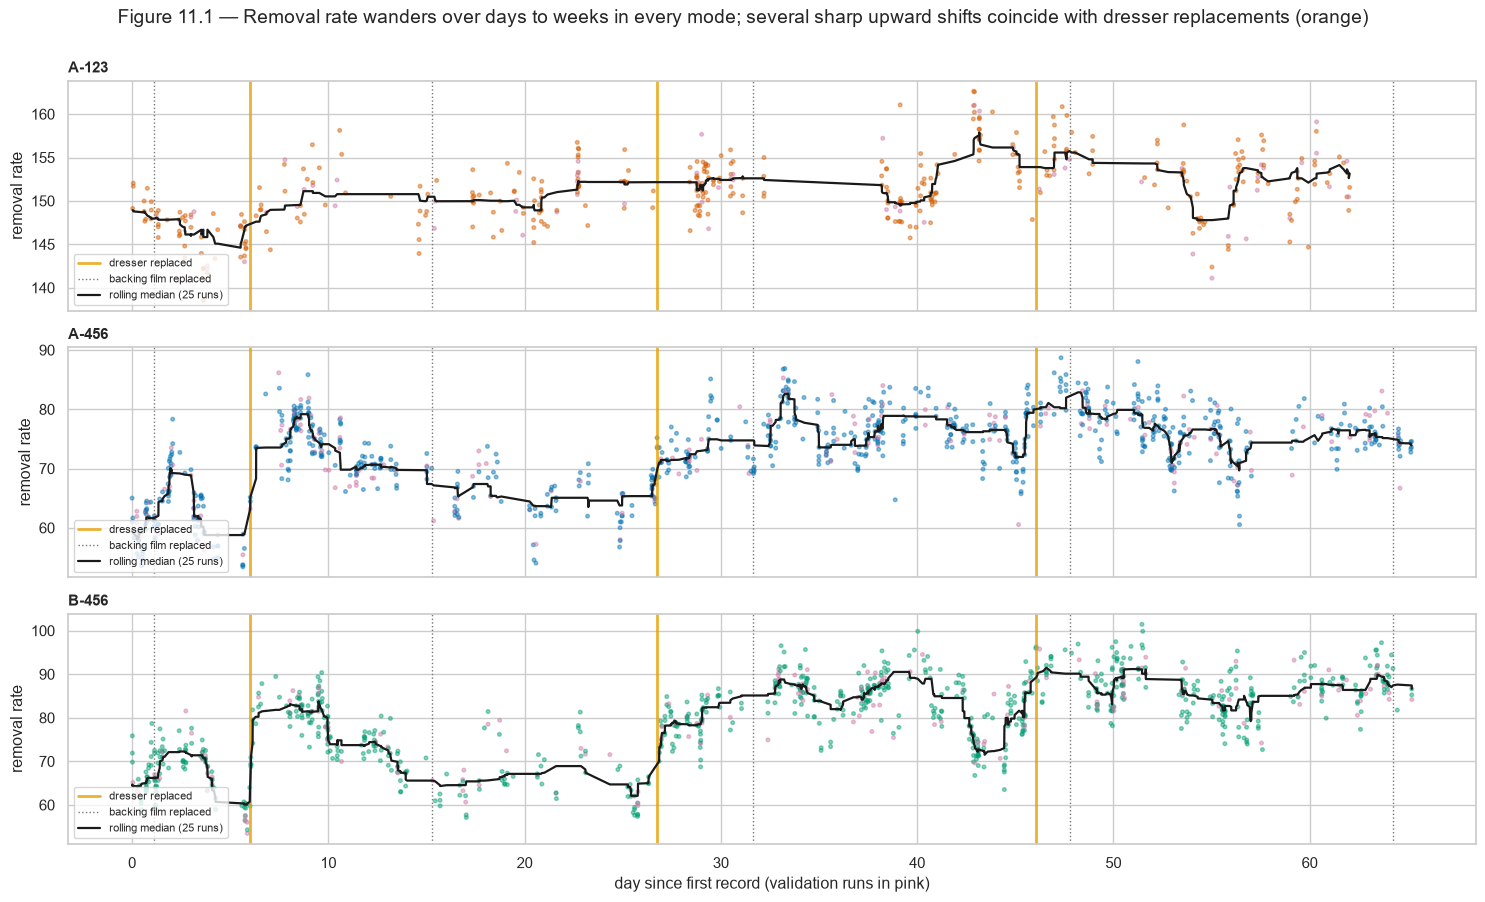

In [31]:
def drift_level(frame, ref, k):
    """Median label of the k time-nearest reference runs of the same mode, excluding the run itself."""
    out = pd.Series(np.nan, index=frame.index)
    for m in MODES:
        r = ref[ref.MODE == m].sort_values('T_START')
        rt, ry, rid = r.T_START.values, r[TARGET].values, r.index.values
        q = frame[frame.MODE == m]
        for i, t in zip(q.index, q.T_START.values):
            j = np.searchsorted(rt, t)
            cand = np.arange(max(0, j - k - 1), min(len(rt), j + k + 1))
            cand = cand[rid[cand] != i]
            near = cand[np.argsort(np.abs(rt[cand] - t), kind='stable')[:k]]
            out[i] = np.median(ry[near])
    return out

REF = F[(F.SPLIT == 'train') & ~F.LABEL_OUTLIER]
F['DRIFT_LEVEL'] = drift_level(F, REF, CONFIG['drift_neighbours'])
dev = F[F.SPLIT.isin(['train', 'validation']) & ~F.LABEL_OUTLIER].copy()
tr = dev[dev.SPLIT == 'train']; va = dev[dev.SPLIT == 'validation']

def replacement_days(counter, frac=0.5):
    s_ = F.sort_values('T_START'); v = s_[counter].values
    return s_.DAY.values[np.flatnonzero(np.diff(v) < -frac * (np.nanmax(v) - np.nanmin(v))) + 1]
DRESSER_DAYS, FILM_DAYS = replacement_days('U_DRESSER_START'), replacement_days('U_BACKING_FILM_START')
print('Dresser replaced on days', np.round(DRESSER_DAYS, 1), '| backing film replaced on days', np.round(FILM_DAYS, 1))
fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
for ax, m in zip(axes, MODES):
    for i_, d_ in enumerate(DRESSER_DAYS): ax.axvline(d_, color='#E69F00', lw=2, alpha=.8, label='dresser replaced' if i_ == 0 else None)
    for i_, d_ in enumerate(FILM_DAYS): ax.axvline(d_, color='#777', lw=1, ls=':', label='backing film replaced' if i_ == 0 else None)
    s_ = dev[dev.MODE == m].sort_values('T_START')
    ax.scatter(s_.DAY, s_[TARGET], s=7, alpha=.45, color=np.where(s_.SPLIT == 'train', MODE_COLORS[m], SPLIT_COLORS['validation']))
    roll = s_[TARGET].rolling(25, center=True, min_periods=8).median()
    ax.plot(s_.DAY, roll, color='k', lw=1.6, label='rolling median (25 runs)')
    ax.set_ylabel('removal rate'); ax.set_title(f'{m}', loc='left'); ax.legend(loc='lower left', fontsize=8)
axes[-1].set_xlabel('day since first record (validation runs in pink)')
fig.suptitle('Figure 11.1 — Removal rate wanders over days to weeks in every mode; several sharp upward shifts coincide with dresser replacements (orange)', y=1.0)
fig.tight_layout(); savefig(fig, '11_01_rate_over_time')

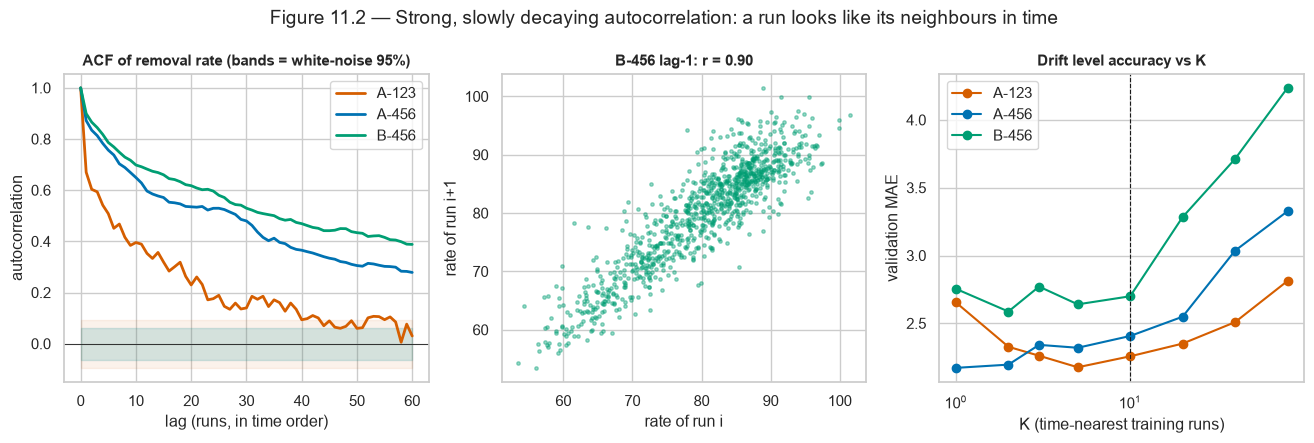

,lag-1 autocorrelation,lag-10 autocorrelation,validation MAE: training median,validation MAE: drift level (K=10),validation R² of drift level
mode,,,,,
A-123,0.67,0.396,3.191,2.257,0.472
A-456,0.872,0.649,5.548,2.407,0.777
B-456,0.899,0.698,7.7,2.7,0.839


In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
acf_tab = {}
for m in MODES:
    y = dev[dev.MODE == m].sort_values('T_START')[TARGET].values
    y = y - y.mean(); n = len(y)
    acf = np.array([1.0] + [np.corrcoef(y[:-k], y[k:])[0, 1] for k in range(1, 61)])
    acf_tab[m] = acf
    axes[0].plot(range(61), acf, color=MODE_COLORS[m], lw=2, label=m)
    axes[0].fill_between(range(61), -1.96 / np.sqrt(n), 1.96 / np.sqrt(n), color=MODE_COLORS[m], alpha=.08)
axes[0].axhline(0, color='k', lw=.6); axes[0].set_xlabel('lag (runs, in time order)'); axes[0].set_ylabel('autocorrelation')
axes[0].set_title('ACF of removal rate (bands = white-noise 95%)'); axes[0].legend()
s_ = dev[dev.MODE == 'B-456'].sort_values('T_START')[TARGET].values
axes[1].scatter(s_[:-1], s_[1:], s=6, alpha=.4, color=MODE_COLORS['B-456'])
axes[1].set_xlabel('rate of run i'); axes[1].set_ylabel('rate of run i+1'); axes[1].set_title(f'B-456 lag-1: r = {np.corrcoef(s_[:-1], s_[1:])[0, 1]:.2f}')
ks_ = [1, 2, 3, 5, 10, 20, 40, 80]
for m in MODES:
    errs = []
    for k in ks_:
        d = drift_level(va[va.MODE == m], REF, k)
        errs.append(mean_absolute_error(va.loc[va.MODE == m, TARGET], d))
    axes[2].plot(ks_, errs, 'o-', color=MODE_COLORS[m], label=m)
axes[2].axvline(CONFIG['drift_neighbours'], color='k', ls='--', lw=.8)
axes[2].set_xscale('log'); axes[2].set_xlabel('K (time-nearest training runs)'); axes[2].set_ylabel('validation MAE')
axes[2].set_title('Drift level accuracy vs K'); axes[2].legend()
fig.suptitle('Figure 11.2 — Strong, slowly decaying autocorrelation: a run looks like its neighbours in time', y=1.04)
savefig(fig, '11_02_autocorrelation')

drift_rows = []
for m in MODES:
    v = va[va.MODE == m]
    base = tr.loc[tr.MODE == m, TARGET].median()
    drift_rows.append({'mode': m, 'lag-1 autocorrelation': acf_tab[m][1], 'lag-10 autocorrelation': acf_tab[m][10],
                       'validation MAE: training median': mean_absolute_error(v[TARGET], np.full(len(v), base)),
                       'validation MAE: drift level (K=10)': mean_absolute_error(v[TARGET], v.DRIFT_LEVEL),
                       'validation R² of drift level': r2_score(v[TARGET], v.DRIFT_LEVEL)})
drift_table = pd.DataFrame(drift_rows).set_index('mode')
display(drift_table.round(3))

**Interpretation (Q2).**
* Removal rate is **strongly autocorrelated in time** in every mode. In A-456 and B-456, consecutive runs correlate at about 0.85–0.9, and the correlation decays slowly over dozens of runs. The rate moves in plateaus and shifts lasting days, not as independent noise around a constant.
* Several of the sharpest shifts, upward jumps around days 6 and 27, happen exactly when the **dresser was replaced** (orange lines). §12 tests this link.
* The modes move **together**: A-456 and B-456 rise and fall in step, which points to a machine-wide cause rather than one stage's hardware.
* The drift level, built only from nearby *training* runs, cuts validation error sharply compared with a constant per-mode median and explains most of the within-mode variance (table above). Very large K blurs real shifts: beyond about 20 neighbours the error climbs steeply (Figure 11.2, right). Anything from about 2 to 10 works similarly well. K = 10 sits at the edge of that flat region, a slightly conservative choice, so the drift level's accuracy is not overstated.

**Implications.**
1. *Evaluation:* the official splits interleave in time (§5.7), so any model can lean on drift, and benchmark accuracy is optimistic for future wafers. Notebook 2 reports models with and without drift information.
2. *Confounding:* anything else that changes slowly over time, such as a usage counter that never resets, will correlate with the rate **because of drift**, whether or not it causes anything. §12 tests this directly.
3. *Operations:* the shifts suggest unrecorded state changes (pad break-in, slurry lots). Tracking a rolling mean of measured removal rate is itself a powerful monitoring signal.

## 12. Q3 — Does consumable wear change removal rate?

**Question.** Usage counters track wear of the backing film, dresser, polishing table (pad) and dresser table. Does wear lower or raise removal rate?

**Method.** (a) Plot each independent counter over time to see replacements (saw-tooth drops). (b) Plot the removal rate against each counter's value, with medians and bootstrap CIs by decile. (c) **Key control:** repeat the correlation after removing drift, using the partial Spearman correlation controlling for time and the correlation with the rate minus its drift level. A counter that is just a clock will lose its correlation; a real wear effect will survive.

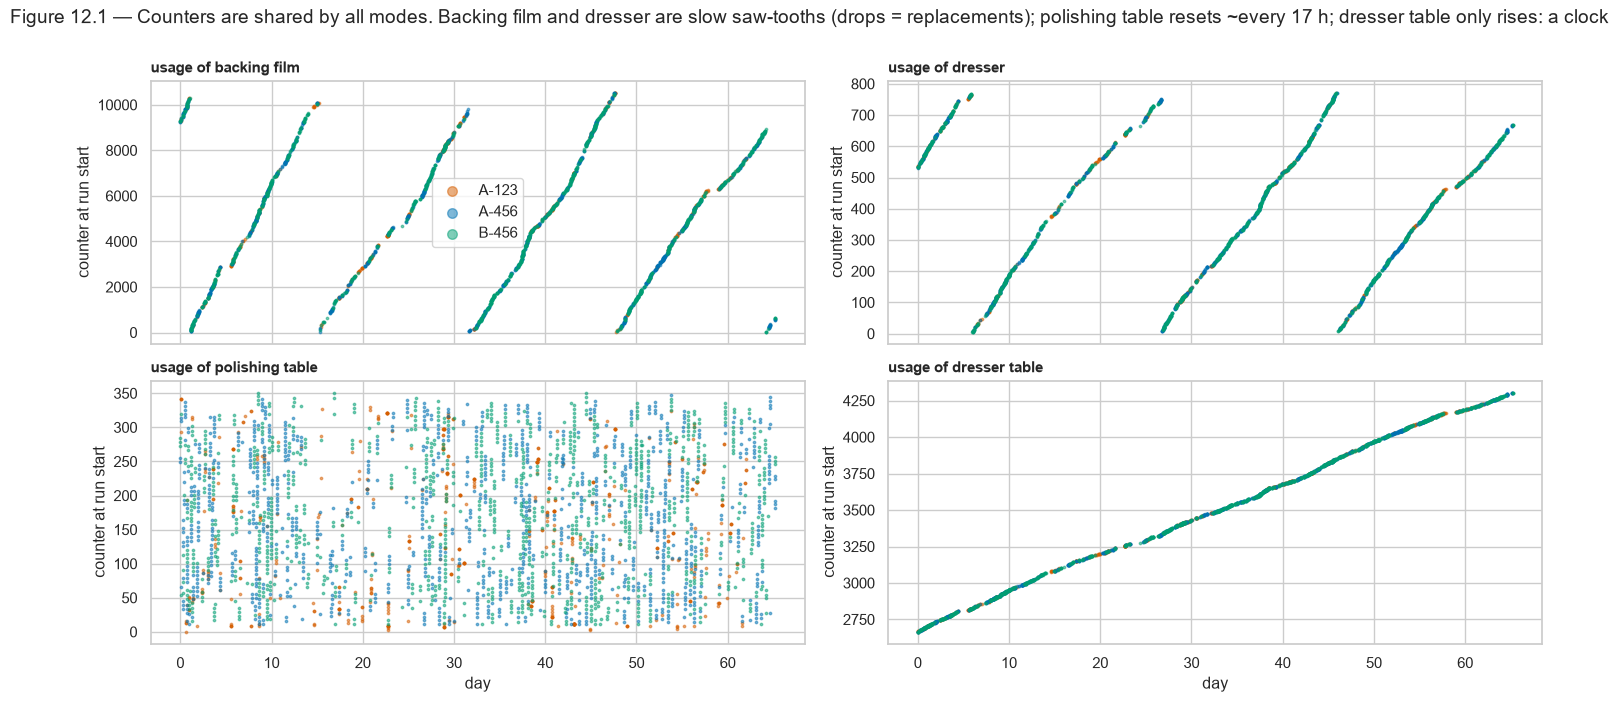

replacements detected             Spearman with time             
mode                                    A-123 A-456 B-456              A-123  A-456 B-456
counter                                                                                  
U_BACKING_FILM_START                        4     5     5              0.291  0.013 0.106
U_DRESSER_START                             3     3     3             -0.227  0.027 0.081
U_DRESSER_TABLE_START                       0     0     0                  1      1     1
U_POLISHING_TABLE_START                    51    90    87              0.003 -0.024 0.042

In [33]:
COUNTERS = ['U_BACKING_FILM_START', 'U_DRESSER_START', 'U_POLISHING_TABLE_START', 'U_DRESSER_TABLE_START']
fig, axes = plt.subplots(2, 2, figsize=(15, 7), sharex=True)
for ax, c in zip(axes.ravel(), COUNTERS):
    for m in MODES:
        s_ = F[F.MODE == m]
        ax.scatter(s_.DAY, s_[c], s=3, alpha=.5, color=MODE_COLORS[m], label=m)
    ax.set_title(c.replace('_START', '').replace('U_', 'usage of ').replace('_', ' ').lower(), loc='left'); ax.set_ylabel('counter at run start')
axes[0, 0].legend(markerscale=4)
for ax in axes[1]: ax.set_xlabel('day')
fig.suptitle('Figure 12.1 — Counters are shared by all modes. Backing film and dresser are slow saw-tooths (drops = replacements); polishing table resets ~every 17 h; dresser table only rises: a clock', y=1.0)
fig.tight_layout(); savefig(fig, '12_01_counters_over_time')

repl = []
for c in COUNTERS:
    for m in MODES:
        s_ = F[F.MODE == m].sort_values('T_START')[c].values
        rng_c = np.nanmax(s_) - np.nanmin(s_)
        drops = int((np.diff(s_) < -0.2 * rng_c).sum())
        repl.append({'counter': c, 'mode': m, 'replacements detected': drops,
                     'Spearman with time': stats.spearmanr(F.loc[F.MODE == m, 'T_START'], F.loc[F.MODE == m, c]).statistic})
repl = pd.DataFrame(repl).pivot(index='counter', columns='mode')
display(repl.round(3))

rho raw  rho controlling for time  rho with (rate - drift level)
mode  counter                                                                            
A-123 U_BACKING_FILM       0.354                     0.263                          0.017
      U_DRESSER           -0.219                    -0.114                          0.011
      U_POLISHING_TABLE    0.056                     0.046                          0.032
      U_DRESSER_TABLE      0.466                    -0.007                         -0.015
A-456 U_BACKING_FILM      -0.013                    -0.027                         -0.006
      U_DRESSER            -0.39                    -0.456                          -0.06
      U_POLISHING_TABLE   -0.019                    -0.001                         -0.119
      U_DRESSER_TABLE      0.467                     0.028                          0.003
B-456 U_BACKING_FILM      -0.087                    -0.179                          0.004
      U_DRESSER           -0.285                    -0.413                          0.006
      U_POLISHING_TABLE   -0.117                    -0.158                         -0.094
      U_DRESSER_TABLE      0.615                     0.007                         -0.028

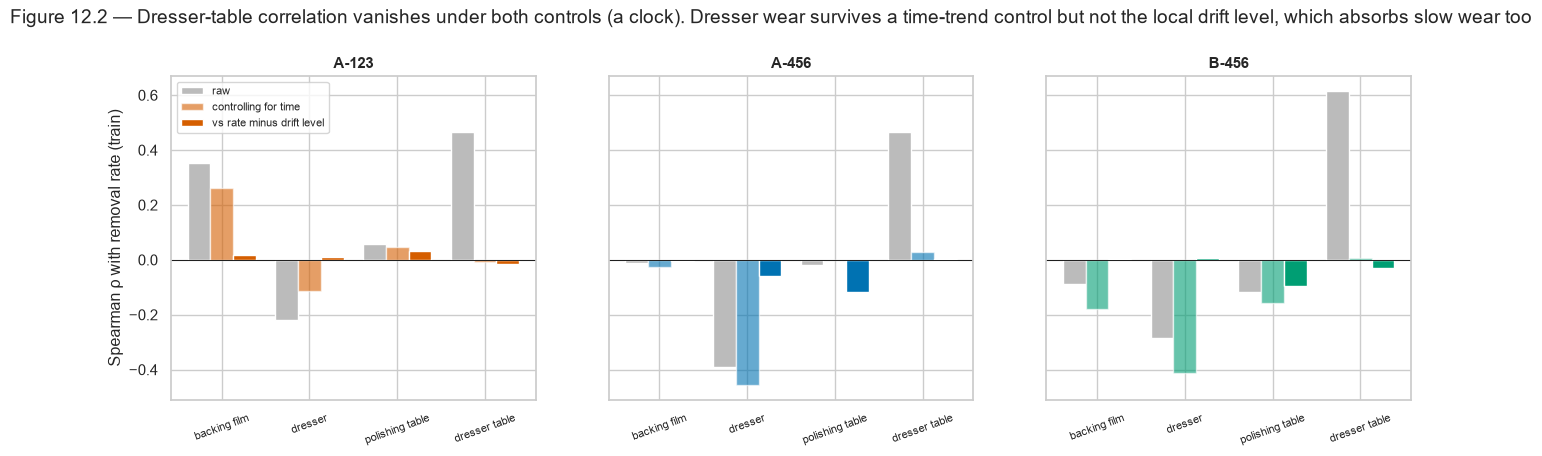

In [34]:
def partial_spearman(x, y, z):
    """Spearman correlation of x and y after linearly removing z from the ranks of both."""
    rx, ry, rz = (stats.rankdata(v) for v in (x, y, z))
    Z = np.c_[np.ones_like(rz), rz]
    ex = rx - Z @ np.linalg.lstsq(Z, rx, rcond=None)[0]
    ey = ry - Z @ np.linalg.lstsq(Z, ry, rcond=None)[0]
    return np.corrcoef(ex, ey)[0, 1]

wear = []
for m in MODES:
    for split, d in [('train', tr), ('validation', va)]:
        s_ = d[d.MODE == m]
        for c in COUNTERS:
            wear.append({'mode': m, 'split': split, 'counter': c.replace('_START', ''),
                         'rho raw': stats.spearmanr(s_[c], s_[TARGET]).statistic,
                         'rho controlling for time': partial_spearman(s_[c].values, s_[TARGET].values, s_['T_START'].values),
                         'rho with (rate - drift level)': stats.spearmanr(s_[c], s_[TARGET] - s_.DRIFT_LEVEL).statistic})
wear = pd.DataFrame(wear)
display(wear[wear.split == 'train'].drop(columns='split').set_index(['mode', 'counter']).round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, m in zip(axes, MODES):
    w = wear[(wear['mode'] == m) & (wear.split == 'train')].set_index('counter')
    x = np.arange(len(w)); wd = .26
    ax.bar(x - wd, w['rho raw'], wd, color='#bbbbbb', label='raw')
    ax.bar(x, w['rho controlling for time'], wd, color=MODE_COLORS[m], alpha=.6, label='controlling for time')
    ax.bar(x + wd, w['rho with (rate - drift level)'], wd, color=MODE_COLORS[m], label='vs rate minus drift level')
    ax.axhline(0, color='k', lw=.7); ax.set_xticks(x); ax.set_xticklabels([i.replace('U_', '').replace('_', ' ').lower() for i in w.index], rotation=20, fontsize=8)
    ax.set_title(m)
axes[0].set_ylabel('Spearman ρ with removal rate (train)'); axes[0].legend(fontsize=8)
fig.suptitle('Figure 12.2 — Dresser-table correlation vanishes under both controls (a clock). Dresser wear survives a time-trend control but not the local drift level, which absorbs slow wear too', y=1.04)
savefig(fig, '12_02_wear_partial')

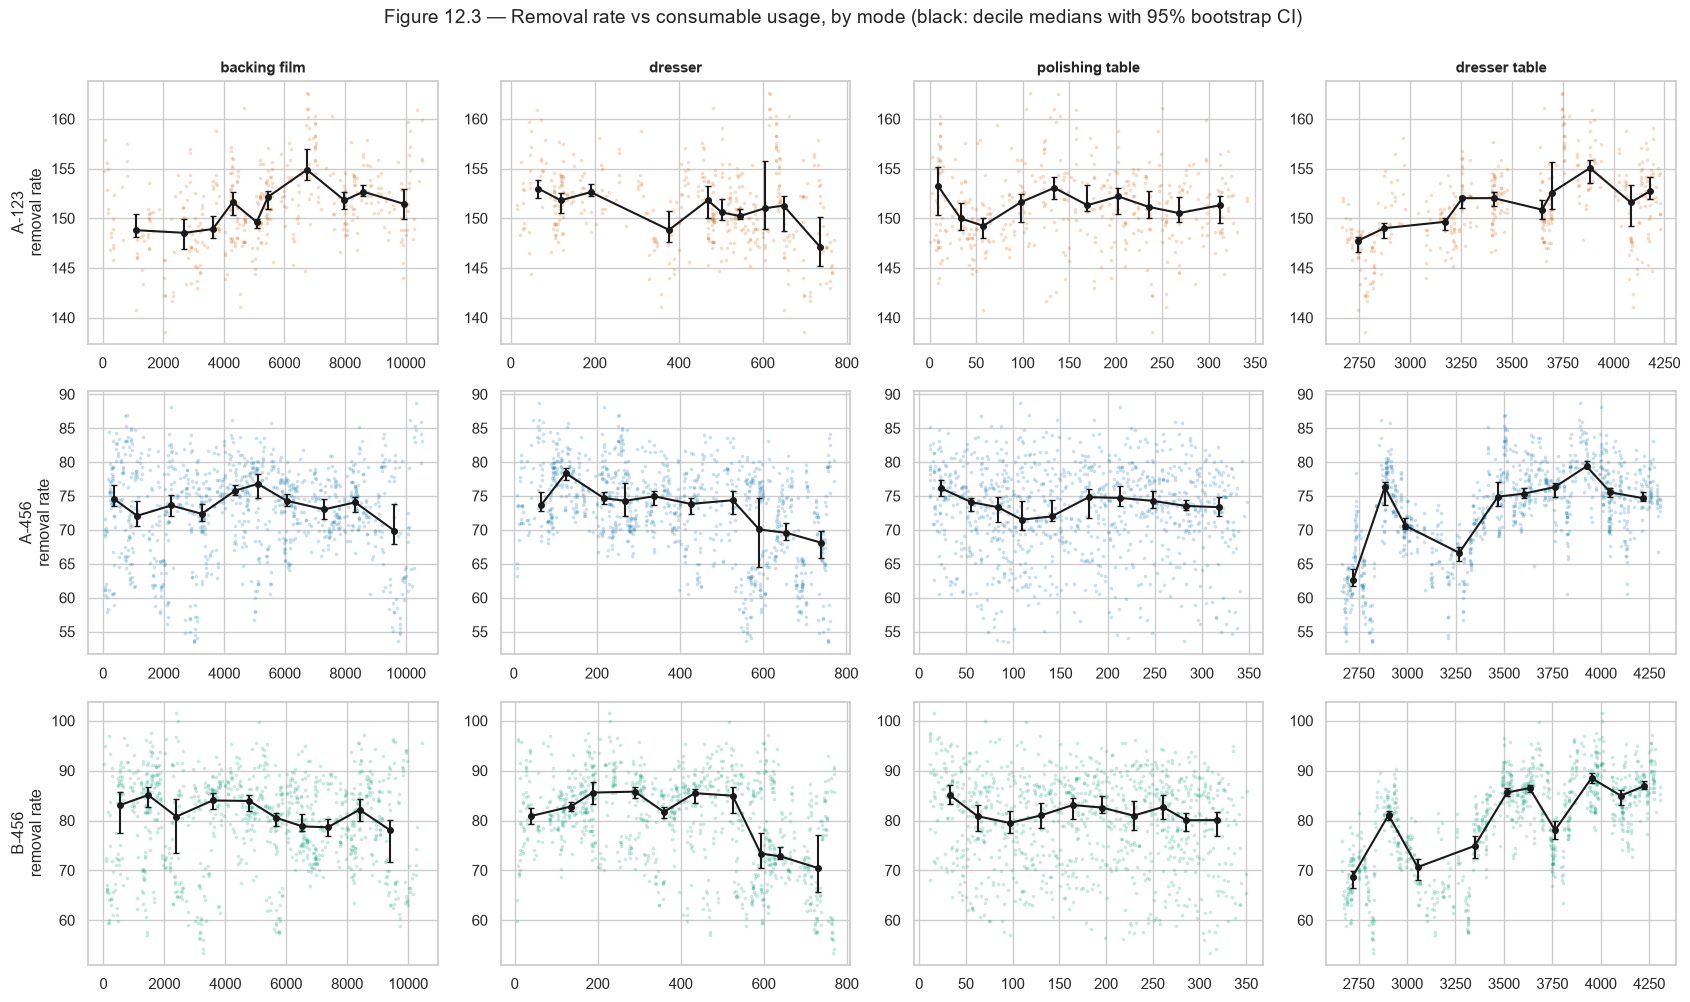

In [35]:
fig, axes = plt.subplots(3, 4, figsize=(17, 10))
for i, m in enumerate(MODES):
    s_ = dev[dev.MODE == m]
    for j, c in enumerate(COUNTERS):
        ax = axes[i, j]
        q = pd.qcut(s_[c], 10, duplicates='drop')
        grp = s_.groupby(q, observed=True)
        mids = grp[c].median(); meds = grp[TARGET].median()
        cis = np.array([boot_ci(v.values, draws=500) for _, v in grp[TARGET]])
        ax.scatter(s_[c], s_[TARGET], s=3, alpha=.15, color=MODE_COLORS[m])
        ax.errorbar(mids, meds, yerr=[meds - cis[:, 0], cis[:, 1] - meds], fmt='o-', color='k', capsize=2, ms=4)
        if i == 0: ax.set_title(c.replace('_START', '').replace('U_', '').replace('_', ' ').lower())
        if j == 0: ax.set_ylabel(f'{m}\nremoval rate')
fig.suptitle('Figure 12.3 — Removal rate vs consumable usage, by mode (black: decile medians with 95% bootstrap CI)', y=1.0)
fig.tight_layout(); savefig(fig, '12_03_rate_vs_wear')

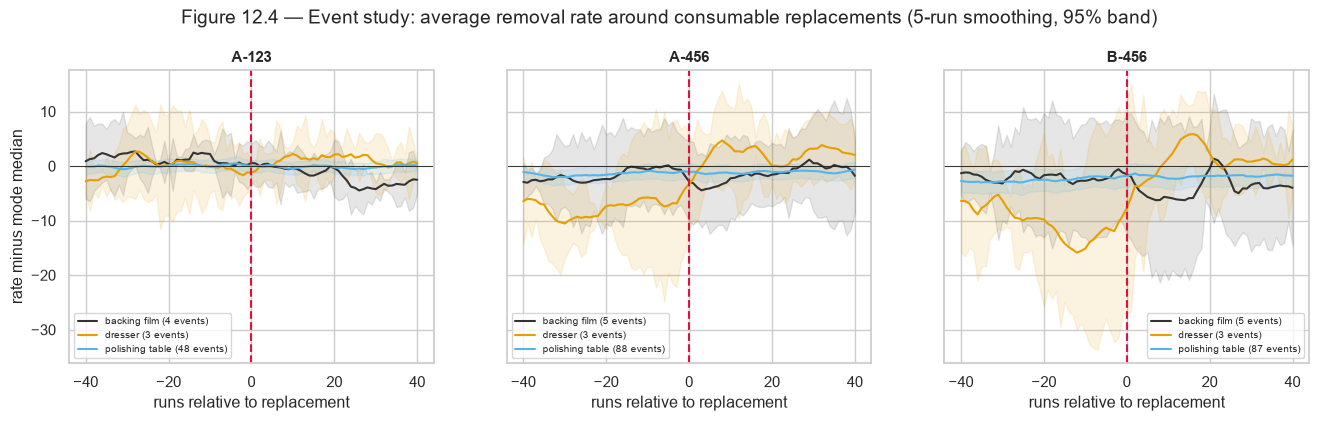

In [36]:
def event_study(counter, m, window=40):
    s_ = F[(F.MODE == m) & ~F.LABEL_OUTLIER & F.SPLIT.isin(['train', 'validation'])].sort_values('T_START').reset_index(drop=True)
    v = s_[counter].values; rng_c = np.nanmax(v) - np.nanmin(v)
    events = np.flatnonzero(np.diff(v) < -0.2 * rng_c) + 1
    base = s_[TARGET].median(); rows = []
    for e in events:
        for off in range(-window, window + 1):
            if 0 <= e + off < len(s_): rows.append({'offset': off, 'dev': s_.loc[e + off, TARGET] - base, 'event': e})
    return pd.DataFrame(rows), len(events)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, m in zip(axes, MODES):
    for c, col in [('U_BACKING_FILM_START', '#333'), ('U_DRESSER_START', '#E69F00'), ('U_POLISHING_TABLE_START', '#56B4E9')]:
        es, n_ev = event_study(c, m)
        if n_ev == 0: continue
        prof = es.groupby('offset')['dev'].agg(['mean', 'sem'])
        sm = prof['mean'].rolling(5, center=True, min_periods=1).mean()
        ax.plot(prof.index, sm, color=col, label=f"{c.replace('U_', '').replace('_START', '').replace('_', ' ').lower()} ({n_ev} events)")
        ax.fill_between(prof.index, sm - 1.96 * prof['sem'], sm + 1.96 * prof['sem'], color=col, alpha=.12)
    ax.axvline(0, color='crimson', ls='--'); ax.axhline(0, color='k', lw=.6)
    ax.set_title(m); ax.set_xlabel('runs relative to replacement'); ax.legend(fontsize=7)
axes[0].set_ylabel('rate minus mode median')
fig.suptitle('Figure 12.4 — Event study: average removal rate around consumable replacements (5-run smoothing, 95% band)', y=1.04)
savefig(fig, '12_04_replacement_events')

**How much of the drift does wear explain?** A smooth (spline) model of removal rate is fitted on training runs using only wear counters, then scored on validation runs. It is compared with the drift level, which uses nearby training labels.

mode,A-123,A-456,B-456
model,,,
dresser only,0.114,0.175,0.207
dresser + backing film,0.286,0.231,0.249
dresser + backing film + polishing table,0.332,0.26,0.239
drift level (time neighbours),0.479,0.778,0.844


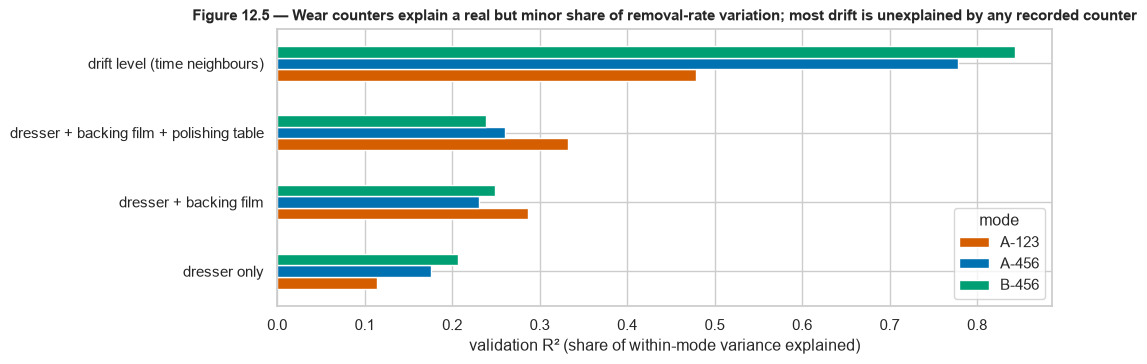

In [37]:
from sklearn.preprocessing import SplineTransformer
wear_models = {'dresser only': ['U_DRESSER_START'], 'dresser + backing film': ['U_DRESSER_START', 'U_BACKING_FILM_START'],
               'dresser + backing film + polishing table': ['U_DRESSER_START', 'U_BACKING_FILM_START', 'U_POLISHING_TABLE_START'],
               'drift level (time neighbours)': ['DRIFT_LEVEL']}
rows = []
for m in MODES:
    a, b = tr[tr.MODE == m], va[va.MODE == m]
    for name, cols in wear_models.items():
        mdl = make_pipeline(SplineTransformer(n_knots=6, degree=3), RidgeCV(alphas=np.logspace(-3, 3, 13))).fit(a[cols], a[TARGET])
        p_ = mdl.predict(b[cols])
        rows.append({'mode': m, 'model': name, 'validation R²': r2_score(b[TARGET], p_), 'validation MAE': mean_absolute_error(b[TARGET], p_)})
wear_expl = pd.DataFrame(rows).pivot(index='model', columns='mode', values='validation R²').reindex(list(wear_models))
display(wear_expl.round(3))
fig, ax = plt.subplots(figsize=(10, 3.6))
wear_expl.plot.barh(ax=ax, color=[MODE_COLORS[m] for m in wear_expl.columns])
ax.set_xlabel('validation R² (share of within-mode variance explained)'); ax.set_ylabel('')
ax.set_title('Figure 12.5 — Wear counters explain a real but minor share of removal-rate variation; most drift is unexplained by any recorded counter')
savefig(fig, '12_05_wear_explained')

**Interpretation (Q3).**
* **Dresser-table usage is a clock, not a cause.** It rises steadily, never resets, and correlates with time at ρ = 1. Its raw correlation with removal rate (ρ ≈ 0.5–0.6) disappears completely once time is controlled for. A naive correlation table would rank it as a top predictor; acting on it would be a mistake.
* **Dresser wear shows the strongest evidence of a real effect.** Higher dresser usage goes with lower removal rate, and the association *strengthens* when a linear time trend is removed (ρ ≈ −0.4 in A-456 and B-456). Around the three dresser replacements, the event study shows rate sagging beforehand and recovering afterwards, and the largest level shifts in Figure 11.1 sit on replacement days. That is physically sensible: a worn dresser conditions the pad less aggressively, the pad glazes, and removal slows. The association does vanish against the local drift level, but that control absorbs any slow change, wear included, so it cannot distinguish the two. With only three replacements, the evidence is suggestive, not conclusive.
* **Backing film** shows no consistent effect. The **polishing-table** counter resets about every 17 hours, so it is not a pad-life counter in the usual sense, and it adds little on its own.
* **How much does wear explain?** Wear counters account for a real but **minor** share of the variation (Figure 12.5). The drift level, built from neighbouring runs' labels, explains far more. Most of the drift comes from something no counter records, such as slurry lots, pad state or incoming wafers.

**Caveat.** Replacement timing is not random. Parts are replaced when engineers judge it necessary, often after performance has already changed, so event studies can show recovery without proving the replacement caused it.

## 13. Q4 — Which process settings matter within a mode?

**Method.** For every feature, compute the Spearman correlation with removal rate **within each mode**, on training runs. Then correct for testing about 50 features × 3 modes with Benjamini–Hochberg (FDR 5%). A correlation counts as *meaningful* only if it is both statistically significant (q < 0.05) and practically sizeable (|ρ| ≥ 0.3). Correlations are computed twice: against the raw rate, and against the rate **after removing drift**.

In [38]:
DROP_REDUNDANT = [c for c in FEATURES if c.startswith(('U_MEMBRANE', 'U_PRESSURIZED_SHEET'))]
ANALYSIS_FEATURES = [c for c in FEATURES if c not in DROP_REDUNDANT]
corr_rows = []
for m in MODES:
    s_ = tr[tr.MODE == m]
    resid = s_[TARGET] - s_.DRIFT_LEVEL
    for c in ANALYSIS_FEATURES:
        ok = s_[c].notna()
        if ok.sum() < 30 or s_.loc[ok, c].nunique() < 3: continue
        r1 = stats.spearmanr(s_.loc[ok, c], s_.loc[ok, TARGET]); r2 = stats.spearmanr(s_.loc[ok, c], resid[ok])
        rp = stats.pearsonr(s_.loc[ok, c], s_.loc[ok, TARGET])
        corr_rows.append({'mode': m, 'feature': c, 'n': int(ok.sum()), 'rho': r1.statistic, 'p': r1.pvalue, 'pearson': rp.statistic,
                          'rho_detrended': r2.statistic, 'p_detrended': r2.pvalue})
corr = pd.DataFrame(corr_rows)
corr['q'] = bh(corr['p']); corr['q_detrended'] = bh(corr['p_detrended'])
corr['meaningful'] = (corr.q < CONFIG['fdr_alpha']) & (corr.rho.abs() >= CONFIG['min_abs_rho'])
corr['meaningful_detrended'] = (corr.q_detrended < CONFIG['fdr_alpha']) & (corr.rho_detrended.abs() >= CONFIG['min_abs_rho'])
corr.to_csv(OUT / 'feature_target_correlations.csv', index=False)
print(f"Tests: {len(corr)} | meaningful (raw rate): {corr.meaningful.sum()} | meaningful after removing drift: {corr.meaningful_detrended.sum()}")
display(corr.sort_values('rho', key=abs, ascending=False).groupby('mode').head(6)[['mode', 'feature', 'n', 'rho', 'q', 'rho_detrended', 'q_detrended']].round(4))

Tests: 150 | meaningful (raw rate): 11 | meaningful after removing drift: 0


,mode,feature,n,rho,q,rho_detrended,q_detrended
102,B-456,N_SAMPLES,815,-0.698,0,-0.0897,0.1366
101,B-456,DURATION,815,-0.6875,0,-0.102,0.107
144,B-456,U_DRESSER_TABLE_START,815,0.6152,0,-0.028,0.8207
53,A-456,N_SAMPLES,798,-0.4898,0,0.0208,0.9168
52,A-456,DURATION,798,-0.4776,0,0.0269,0.8281
95,A-456,U_DRESSER_TABLE_START,798,0.4674,0,0.0029,0.9627
46,A-123,U_DRESSER_TABLE_START,364,0.4655,0,-0.0152,0.9387
104,B-456,ACTIVE_FRACTION,815,0.4204,0,0.0181,0.9168
91,A-456,U_DRESSER_START,798,-0.39,0,-0.0596,0.5357
40,A-123,U_BACKING_FILM_START,364,0.3538,0,0.0172,0.9387


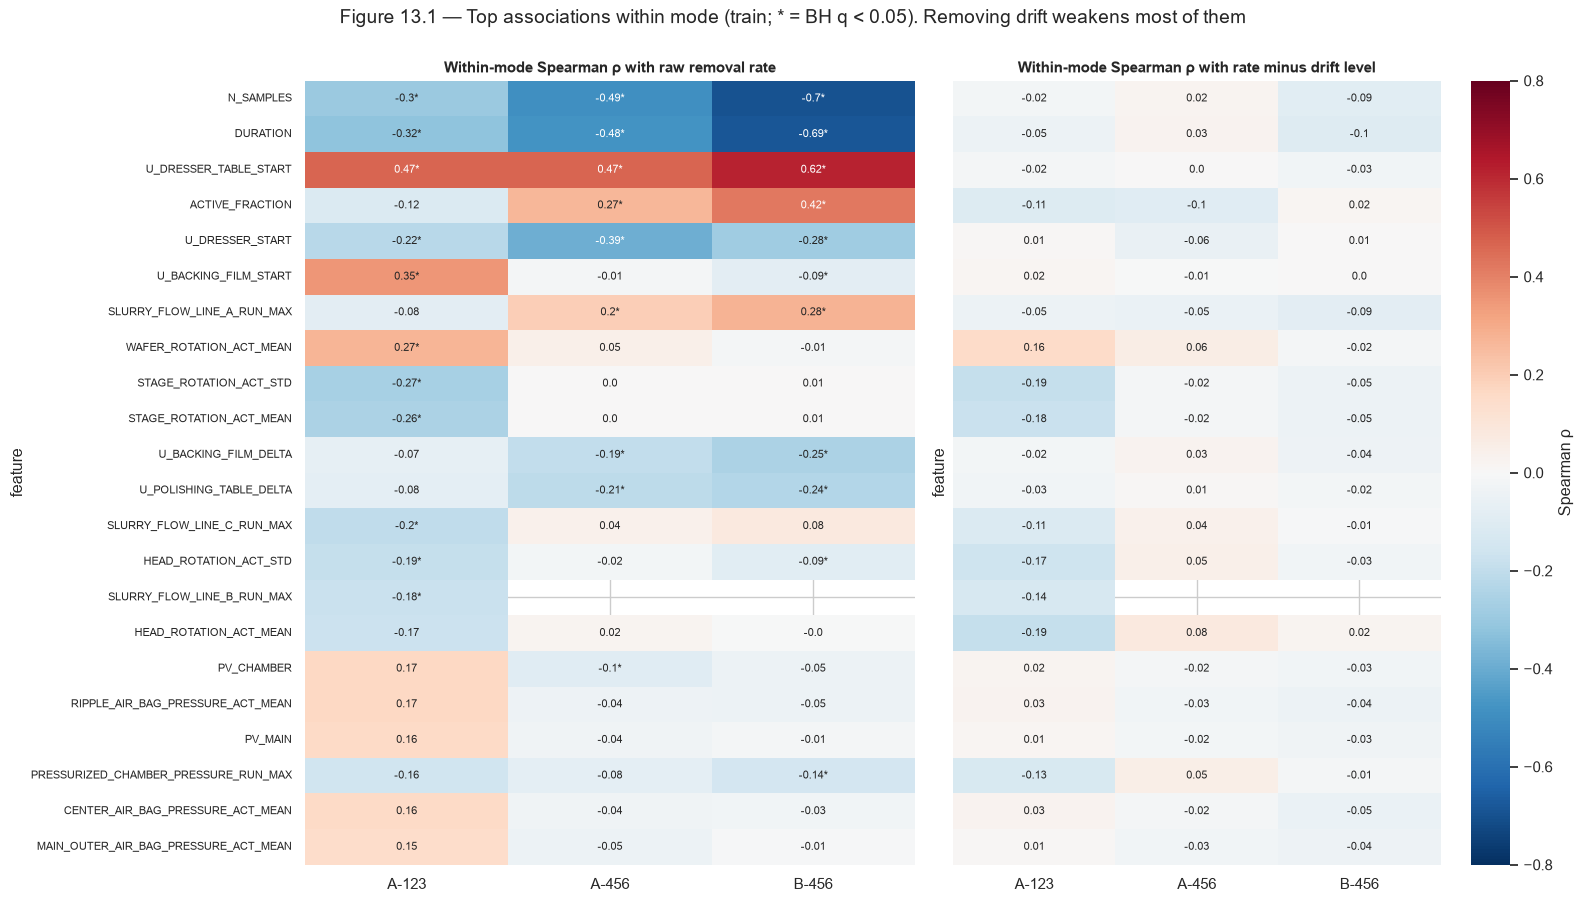

In [39]:
top = (corr.assign(a=corr.rho.abs()).groupby('feature')['a'].max().sort_values(ascending=False).head(22).index)
fig, axes = plt.subplots(1, 2, figsize=(16, 9), sharey=True)
for ax, col, qcol, title in [(axes[0], 'rho', 'q', 'raw removal rate'), (axes[1], 'rho_detrended', 'q_detrended', 'rate minus drift level')]:
    mat = corr.pivot(index='feature', columns='mode', values=col).reindex(top)
    qm = corr.pivot(index='feature', columns='mode', values=qcol).reindex(top)
    ann = mat.round(2).astype(str) + np.where(qm < 0.05, '*', '')
    sns.heatmap(mat, ax=ax, cmap='RdBu_r', vmin=-.8, vmax=.8, annot=ann, fmt='', annot_kws={'size': 8}, cbar=ax is axes[1],
                cbar_kws={'label': 'Spearman ρ'})
    ax.set_title(f'Within-mode Spearman ρ with {title}'); ax.set_xlabel('')
axes[0].tick_params(axis='y', labelsize=8)
fig.suptitle('Figure 13.1 — Top associations within mode (train; * = BH q < 0.05). Removing drift weakens most of them', y=1.0)
fig.tight_layout(); savefig(fig, '13_01_correlation_heatmap')

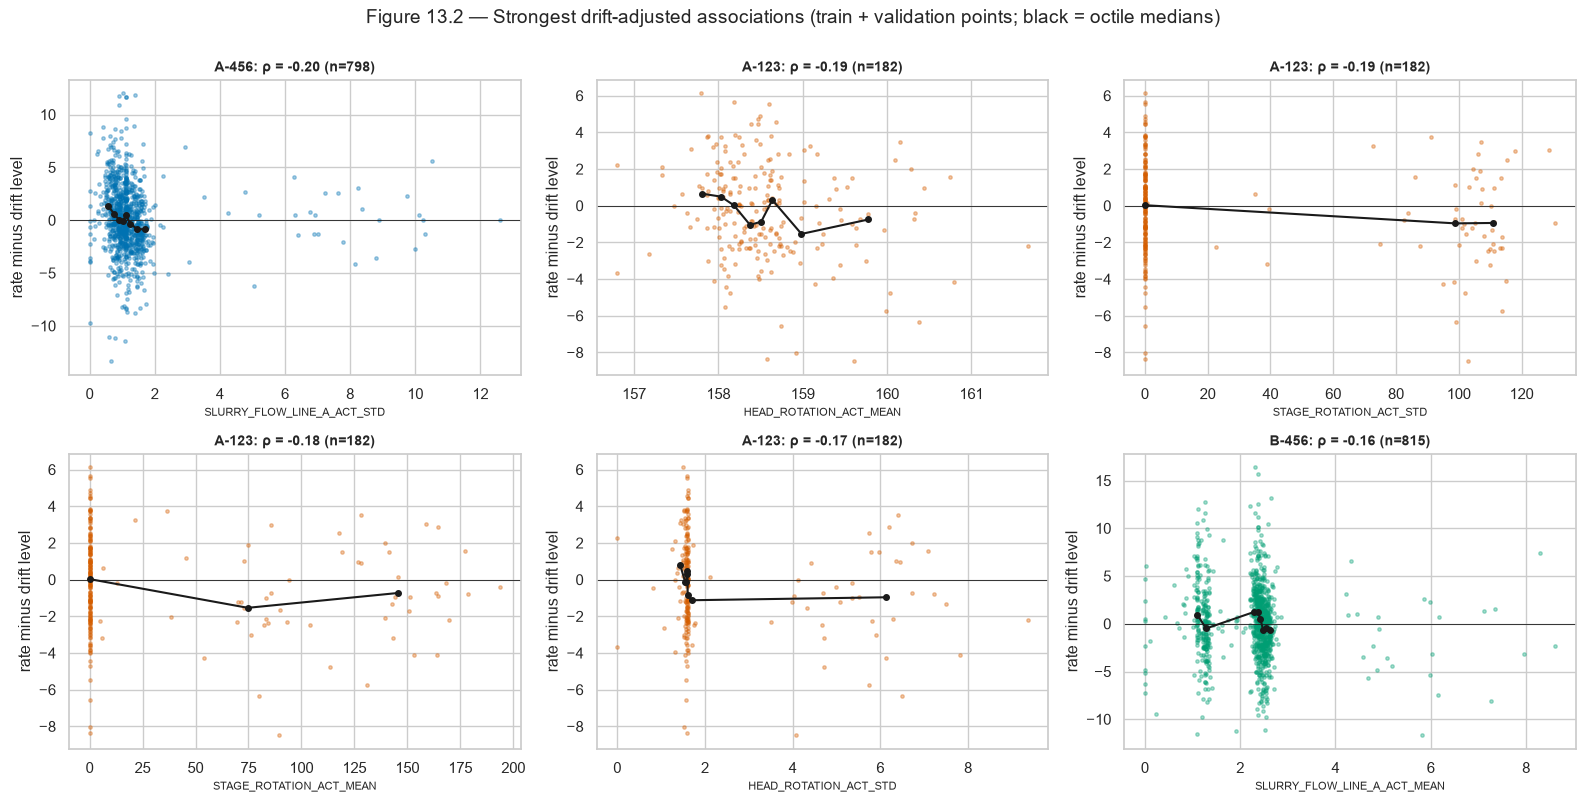

In [40]:
best = corr[corr.meaningful_detrended].sort_values('rho_detrended', key=abs, ascending=False).drop_duplicates('feature').head(6)
if len(best) < 6:
    best = pd.concat([best, corr.sort_values('rho_detrended', key=abs, ascending=False)]).drop_duplicates('feature').head(6)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (_, row) in zip(axes.ravel(), best.iterrows()):
    s_ = dev[(dev.MODE == row['mode'])]
    ok = s_[row.feature].notna()
    x, y = s_.loc[ok, row.feature], (s_[TARGET] - s_.DRIFT_LEVEL)[ok]
    ax.scatter(x, y, s=6, alpha=.35, color=MODE_COLORS[row['mode']])
    q = pd.qcut(x, 8, duplicates='drop'); g_ = y.groupby(q, observed=True)
    ax.plot(x.groupby(q, observed=True).median(), g_.median(), 'k-o', ms=4)
    ax.axhline(0, color='k', lw=.6)
    ax.set_xlabel(row.feature, fontsize=8); ax.set_ylabel('rate minus drift level')
    ax.set_title(f"{row['mode']}: ρ = {row.rho_detrended:.2f} (n={row.n})", fontsize=10)
fig.suptitle('Figure 13.2 — Strongest drift-adjusted associations (train + validation points; black = octile medians)', y=1.0)
fig.tight_layout(); savefig(fig, '13_02_top_scatter')

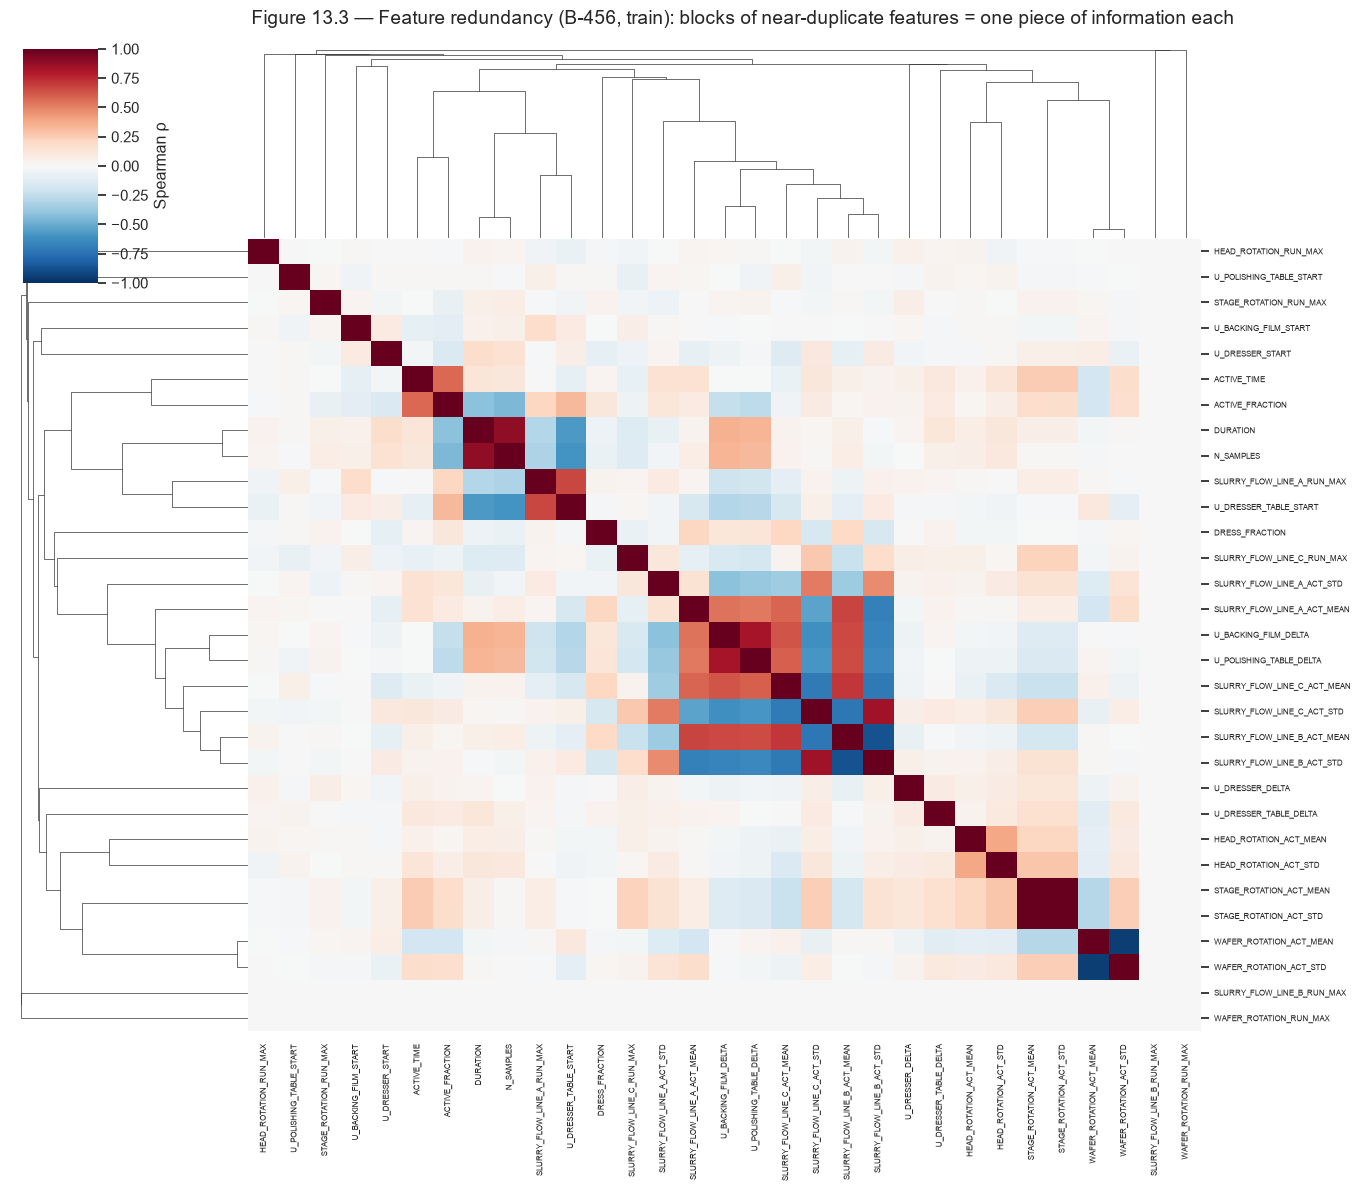

31 features fall into 26 clusters at |ρ| ≥ 0.8 -> the effective number of distinct signals is much smaller than the feature count.


In [41]:
sub = tr[tr.MODE == 'B-456'][[c for c in ANALYSIS_FEATURES if tr[c].notna().mean() > .9 and tr.loc[tr.MODE == 'B-456', c].std() > 0]]
cm_ = sub.corr(method='spearman').fillna(0)
dist = 1 - np.abs(cm_.values); np.fill_diagonal(dist, 0); dist = np.clip((dist + dist.T) / 2, 0, None)
link = hierarchy.linkage(dist[np.triu_indices_from(dist, 1)], method='average')
clusters = hierarchy.fcluster(link, t=0.2, criterion='distance')
cg = sns.clustermap(cm_, cmap='RdBu_r', vmin=-1, vmax=1, figsize=(15, 13), xticklabels=True, yticklabels=True,
                    row_linkage=link, col_linkage=link, cbar_kws={'label': 'Spearman ρ'})
cg.ax_heatmap.tick_params(labelsize=6)
cg.fig.suptitle('Figure 13.3 — Feature redundancy (B-456, train): blocks of near-duplicate features = one piece of information each', y=1.01)
savefig(cg.fig, '13_03_feature_clustermap')
print(f'{sub.shape[1]} features fall into {clusters.max()} clusters at |ρ| ≥ 0.8 -> the effective number of distinct signals is much smaller than the feature count.')

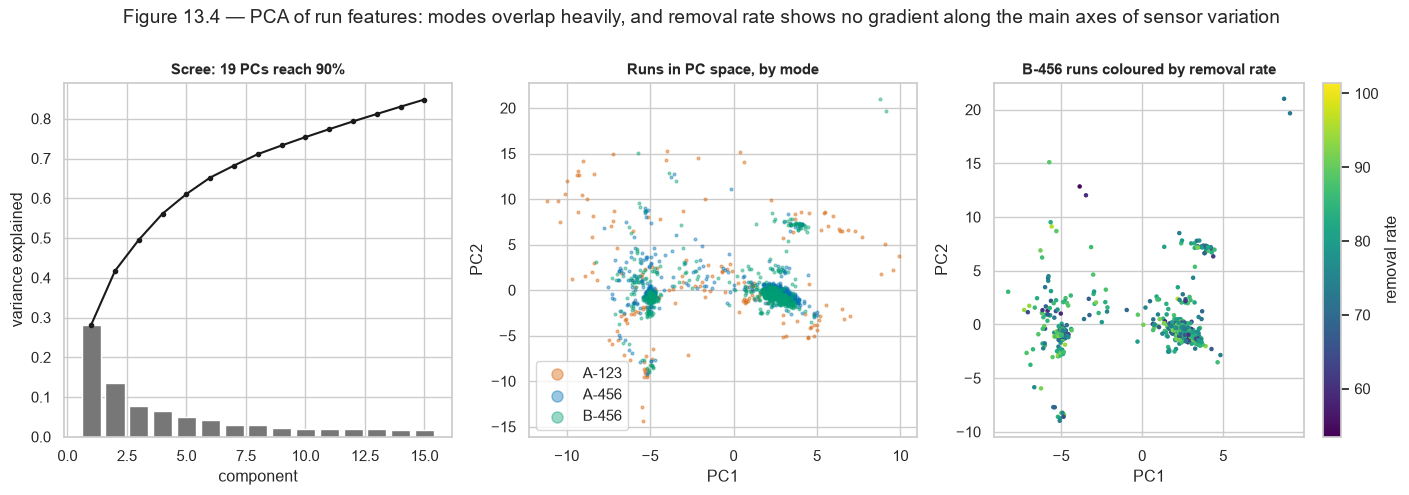

In [42]:
pca_cols = [c for c in ANALYSIS_FEATURES if dev.loc[dev.SIGNALS_RECORDED, c].notna().all()]
Xp = dev.loc[dev.SIGNALS_RECORDED, pca_cols]
Z = StandardScaler().fit(Xp[dev.loc[dev.SIGNALS_RECORDED, 'SPLIT'] == 'train']).transform(Xp)
pca = PCA(random_state=CONFIG['seed']).fit(Z)
pcs = pca.transform(Z)[:, :2]
lab = dev.loc[dev.SIGNALS_RECORDED]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ev = pca.explained_variance_ratio_
axes[0].bar(range(1, 16), ev[:15], color='#777'); axes[0].plot(range(1, 16), np.cumsum(ev[:15]), 'k-o', ms=3)
axes[0].set_xlabel('component'); axes[0].set_ylabel('variance explained'); axes[0].set_title(f'Scree: {np.argmax(np.cumsum(ev) > .9) + 1} PCs reach 90%')
for m in MODES:
    k_ = (lab.MODE == m).values
    axes[1].scatter(pcs[k_, 0], pcs[k_, 1], s=4, alpha=.4, color=MODE_COLORS[m], label=m)
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2'); axes[1].legend(markerscale=4); axes[1].set_title('Runs in PC space, by mode')
k_ = (lab.MODE == 'B-456').values
sc = axes[2].scatter(pcs[k_, 0], pcs[k_, 1], s=5, c=lab.loc[k_, TARGET], cmap='viridis')
plt.colorbar(sc, ax=axes[2], label='removal rate'); axes[2].set_xlabel('PC1'); axes[2].set_ylabel('PC2'); axes[2].set_title('B-456 runs coloured by removal rate')
fig.suptitle('Figure 13.4 — PCA of run features: modes overlap heavily, and removal rate shows no gradient along the main axes of sensor variation', y=1.04)
savefig(fig, '13_04_pca')

**Interpretation (Q4).**
* Against the raw rate, a handful of features pass both the significance and the effect-size bar. The strongest are run duration / sample count and the dresser-table counter, and **all of them are time-trend proxies**.
* **After removing drift, no feature passes the bar in any mode** (Figure 13.1, right; the printout above). Run-level summaries of the recorded pressures, flows and speeds carry essentially no information about why one run is faster than its neighbours. A few are statistically detectable but small: the largest is |ρ| ≈ 0.2, so the feature explains about 4% of the residual variation. Figure 13.2 shows these: nearly flat clouds.
* This is the central result of the notebook. The recorded settings do vary, mostly between a few discrete set-points (§14), but removal rate does not follow them. Its variation comes from slow, mostly unrecorded state changes plus dresser wear.
* The features are highly redundant (Figure 13.3): about 50 features collapse into far fewer clusters of near-duplicates. Correlation tables therefore overstate how many independent findings there are, and a model should use one representative per cluster.
* In PCA (Figure 13.4), the largest directions of sensor variation are mostly *not* directions of removal-rate variation. Most sensor variation is recipe structure and logging noise, not the drivers of removal.
* **Consequence for Notebook 2:** an equation built only from process settings cannot do much better than a per-mode constant. Useful equations will need mode, wear state and the drift level, and Notebook 2 tests exactly that.

**Caveat.** These are associations in observational data. Settings are not randomised, and an engineer may have adjusted them in response to the drift itself, so cause and effect can run either way.

## 14. Q5 — Does Preston's law hold?

**Background.** Preston's equation is the classic CMP model: removal rate = k_p · P · V, where P is down-force pressure, V the relative velocity between wafer and pad, and k_p a constant that bundles consumables and chemistry. On log scales it predicts a slope of +1 for rate against P·V.

**Method.** (a) Check whether P and V vary enough within a mode to test the law. (b) Fit log(rate) against log(P·V) within each mode, with a bootstrap 95% CI for the slope.

,runs,CV % pressure (chamber),CV % wafer rotation,CV % P·V,CV % removal rate,log-log slope,slope 95% CI,"Spearman(P·V, rate)"
mode,,,,,,,,
A-123,165,55.15,9.743,54.57,2.571,0.006,"[0.002, 0.012]",0.227
A-456,975,30.73,2.234,30.71,9.144,-0.003,"[-0.018, 0.015]",-0.068
B-456,976,30.25,1.867,30.14,11.52,-0.009,"[-0.029, 0.013]",-0.072


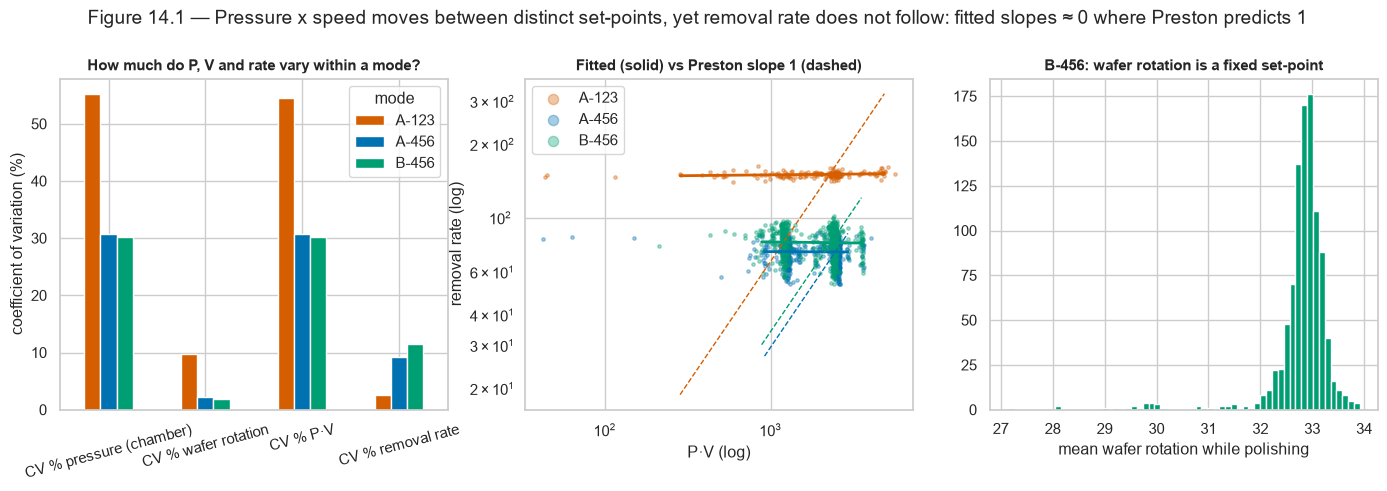

In [43]:
pres = []
for m in MODES:
    s_ = dev[(dev.MODE == m) & dev.SIGNALS_RECORDED & (dev.PV_CHAMBER > 0)]
    x, y = np.log(s_.PV_CHAMBER.values), np.log(s_[TARGET].values)
    slope = np.polyfit(x, y, 1)[0]
    idx = np.random.default_rng(CONFIG['seed']).integers(0, len(x), (CONFIG['bootstrap_draws'], len(x)))
    bs = np.array([np.polyfit(x[i], y[i], 1)[0] for i in idx])
    cv = lambda v: 100 * np.nanstd(v) / np.nanmean(v)
    pres.append({'mode': m, 'runs': len(s_), 'CV % pressure (chamber)': cv(s_.PRESSURIZED_CHAMBER_PRESSURE_ACT_MEAN),
                 'CV % wafer rotation': cv(s_.WAFER_ROTATION_ACT_MEAN), 'CV % P·V': cv(s_.PV_CHAMBER), 'CV % removal rate': cv(s_[TARGET]),
                 'log-log slope': slope, 'slope 95% CI': f'[{np.quantile(bs, .025):.3f}, {np.quantile(bs, .975):.3f}]',
                 'Spearman(P·V, rate)': stats.spearmanr(s_.PV_CHAMBER, s_[TARGET]).statistic})
preston = pd.DataFrame(pres).set_index('mode')
display(preston.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
cvs = preston[['CV % pressure (chamber)', 'CV % wafer rotation', 'CV % P·V', 'CV % removal rate']]
cvs.T.plot.bar(ax=axes[0], color=[MODE_COLORS[m] for m in MODES], rot=15)
axes[0].set_ylabel('coefficient of variation (%)'); axes[0].set_title('How much do P, V and rate vary within a mode?')
for m in MODES:
    s_ = dev[(dev.MODE == m) & dev.SIGNALS_RECORDED & (dev.PV_CHAMBER > 0)]
    axes[1].scatter(s_.PV_CHAMBER, s_[TARGET], s=6, alpha=.35, color=MODE_COLORS[m], label=m)
    xs = np.linspace(s_.PV_CHAMBER.quantile(.02), s_.PV_CHAMBER.quantile(.98), 50)
    c1 = np.polyfit(np.log(s_.PV_CHAMBER), np.log(s_[TARGET]), 1)
    axes[1].plot(xs, np.exp(np.polyval(c1, np.log(xs))), color=MODE_COLORS[m], lw=2)
    ref = s_[TARGET].median() * xs / s_.PV_CHAMBER.median()
    axes[1].plot(xs, ref, color=MODE_COLORS[m], lw=1, ls='--')
axes[1].set_xscale('log'); axes[1].set_yscale('log'); axes[1].set_xlabel('P·V (log)'); axes[1].set_ylabel('removal rate (log)')
axes[1].set_title('Fitted (solid) vs Preston slope 1 (dashed)'); axes[1].legend(markerscale=3)
s_ = dev[(dev.MODE == 'B-456')]
axes[2].hist(s_.WAFER_ROTATION_ACT_MEAN, bins=60, color=MODE_COLORS['B-456'])
axes[2].set_xlabel('mean wafer rotation while polishing'); axes[2].set_title('B-456: wafer rotation is a fixed set-point')
fig.suptitle('Figure 14.1 — Pressure x speed moves between distinct set-points, yet removal rate does not follow: fitted slopes ≈ 0 where Preston predicts 1', y=1.04)
savefig(fig, '14_01_preston')

**Interpretation (Q5).**
* **Wafer rotation is essentially fixed** (CV ≈ 2%), so the velocity half of Preston cannot be tested.
* **Pressure is not fixed.** Within a mode it moves between a few distinct set-point levels, the vertical clusters in Figure 14.1 (middle), with a CV of about 30%. Yet removal rate does not respond: the fitted log-log slopes are about 0, with 95% CIs that exclude Preston's 1 by a wide margin.
* **Possible reasons** (not distinguishable with this data): the recorded "chamber pressure" may not be the effective down-force on the wafer during the phase that determines the measured removal; the set-point levels may belong to phases that contribute little removal; or removal is limited by chemistry or pad state rather than mechanics. In every case, the variation in removal rate sits in Preston's k_p term (consumable state, slurry, pad condition), consistent with §11–§13.
* Across modes the law fails outright: A-123 runs faster at a lower P·V (§10), so k_p differs between routes.

**Implication for Notebook 2.** Equation search should let the "Preston constant" vary with mode and wear, as in rate ≈ k(mode, wear, drift) · f(P, V), rather than expecting P·V to carry the signal.

## 15. Q6 — Associations after controlling for mode and drift (regression)

**Method.** Ordinary least squares on training runs with recorded signals, in two versions:
* **Model A:** mode fixed effects + standardised process settings + wear counters.
* **Model B:** Model A plus the drift level, entered as its deviation from the mode median.

Predictors are standardised on the training data, so each coefficient is the change in removal rate per one standard deviation of that feature. Uncertainty uses HC3 heteroskedasticity-robust standard errors. Errors are autocorrelated in time (§11), so even these intervals are somewhat too narrow, and the coefficients are read as *descriptive*. One representative per redundant feature cluster is used (§13).

Model A: settings + wear: n_train = 1767, train R² = 0.936, validation MAE = 4.64, validation within-mode R² = 0.492
Model B: + drift level: n_train = 1767, train R² = 0.978, validation MAE = 2.50, validation within-mode R² = 0.814


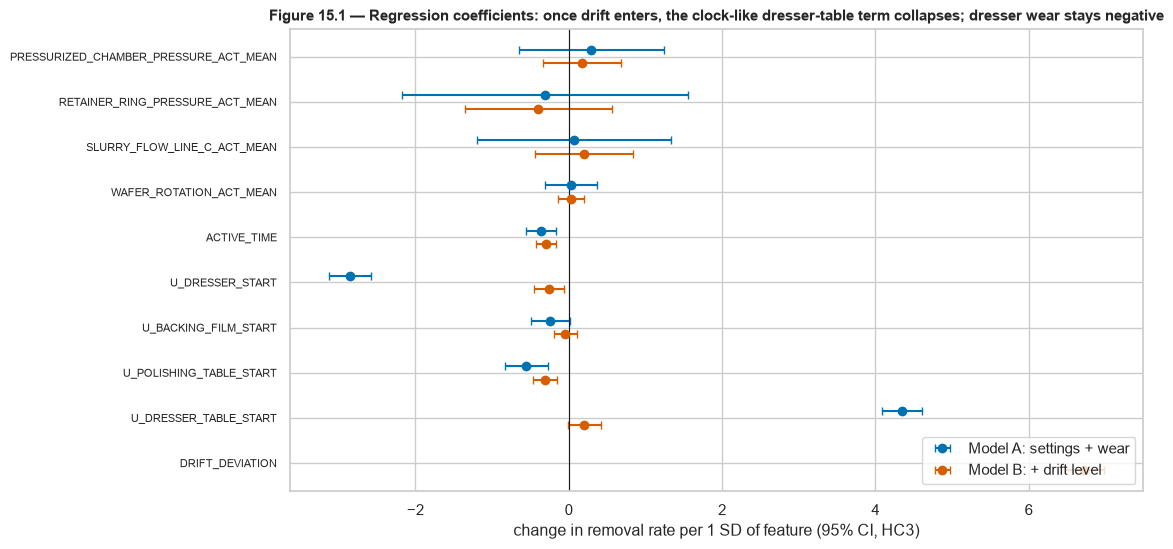

Model A: settings + wear                     Model B: + drift level                    
                                                          coef  ci_lo  ci_hi     p                   coef  ci_lo  ci_hi     p
intercept                                                151.7  150.8  152.6     0                  149.3  148.9  149.8     0
PRESSURIZED_CHAMBER_PRESSURE_ACT_MEAN                    0.296 -0.651  1.244  0.54                  0.172 -0.335  0.678 0.507
RETAINER_RING_PRESSURE_ACT_MEAN                          -0.31 -2.173  1.552 0.744                 -0.395 -1.351  0.561 0.418
SLURRY_FLOW_LINE_C_ACT_MEAN                              0.069 -1.199  1.338 0.915                  0.202 -0.439  0.844 0.536
WAFER_ROTATION_ACT_MEAN                                  0.029 -0.314  0.372 0.868                  0.035 -0.134  0.203 0.688
ACTIVE_TIME                                              -0.36 -0.551 -0.168     0                 -0.301  -0.43 -0.173     0
U_DRESSER_START                                         -2.853 -3.128 -2.577     0                  -0.26 -0.455 -0.065 0.009
U_BACKING_FILM_START                                     -0.24 -0.493  0.014 0.064                 -0.043 -0.197  0.111 0.583
U_POLISHING_TABLE_START                                 -0.552 -0.832 -0.272     0                 -0.309 -0.471 -0.148     0
U_DRESSER_TABLE_START                                    4.345  4.082  4.608     0                  0.202 -0.012  0.415 0.064
MODE=A-456                                              -78.64 -79.64 -77.63     0                 -76.45    -77 -75.91     0
MODE=B-456                                              -71.88 -72.96 -70.79     0                 -68.92 -69.51 -68.33     0
DRIFT_DEVIATION                                            NaN    NaN    NaN   NaN                  6.727  6.472  6.981     0

In [44]:
REG_X = ['PRESSURIZED_CHAMBER_PRESSURE_ACT_MEAN', 'RETAINER_RING_PRESSURE_ACT_MEAN', 'SLURRY_FLOW_LINE_C_ACT_MEAN',
         'WAFER_ROTATION_ACT_MEAN', 'ACTIVE_TIME', 'U_DRESSER_START', 'U_BACKING_FILM_START', 'U_POLISHING_TABLE_START', 'U_DRESSER_TABLE_START']

def ols_hc3(X, y, names):
    X = np.column_stack([np.ones(len(X)), X]); beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    e = y - X @ beta; XtXi = np.linalg.pinv(X.T @ X)
    h = np.einsum('ij,jk,ik->i', X, XtXi, X)
    meat = X.T @ (X * (e ** 2 / (1 - h) ** 2)[:, None])
    se = np.sqrt(np.diag(XtXi @ meat @ XtXi))
    out = pd.DataFrame({'coef': beta, 'se': se}, index=['intercept'] + names)
    out['ci_lo'], out['ci_hi'] = out.coef - 1.96 * out.se, out.coef + 1.96 * out.se
    out['p'] = 2 * stats.norm.sf(np.abs(out.coef / out.se))
    return out, 1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum()

def design(d, with_drift, scaler=None):
    Xn = d[REG_X].copy()
    if with_drift: Xn['DRIFT_DEVIATION'] = d.DRIFT_LEVEL - d.MODE.map(tr.groupby('MODE')[TARGET].median())
    scaler = scaler or StandardScaler().fit(Xn)
    Z = pd.DataFrame(scaler.transform(Xn), columns=Xn.columns, index=d.index)
    for m in MODES[1:]: Z[f'MODE={m}'] = (d.MODE == m).astype(float)
    return Z, scaler

reg_tr = tr[tr.SIGNALS_RECORDED].dropna(subset=REG_X)
reg_va = va[va.SIGNALS_RECORDED].dropna(subset=REG_X)
results = {}
for name, wd in [('Model A: settings + wear', False), ('Model B: + drift level', True)]:
    Z, sc = design(reg_tr, wd)
    coef, r2 = ols_hc3(Z.values, reg_tr[TARGET].values, list(Z.columns))
    Zv, _ = design(reg_va, wd, sc)
    pred = np.column_stack([np.ones(len(Zv)), Zv.values]) @ coef.coef.values
    resid_r2 = lambda d, p: 1 - ((d[TARGET] - p) ** 2).sum() / ((d[TARGET] - d.groupby('MODE')[TARGET].transform('mean')) ** 2).sum()
    results[name] = {'coef': coef, 'train R² (total)': r2, 'validation within-mode R²': resid_r2(reg_va, pred),
                     'validation MAE': mean_absolute_error(reg_va[TARGET], pred)}
    print(f"{name}: n_train = {len(reg_tr)}, train R² = {r2:.3f}, validation MAE = {results[name]['validation MAE']:.2f}, "
          f"validation within-mode R² = {results[name]['validation within-mode R²']:.3f}")

fig, ax = plt.subplots(figsize=(11, 6))
names = REG_X + ['DRIFT_DEVIATION']
for k, (name, col, off) in enumerate([('Model A: settings + wear', '#0072B2', -.15), ('Model B: + drift level', '#D55E00', .15)]):
    c = results[name]['coef'].reindex(names)
    y_ = np.arange(len(names)) + off
    ax.errorbar(c.coef, y_, xerr=[c.coef - c.ci_lo, c.ci_hi - c.coef], fmt='o', color=col, capsize=3, label=name)
ax.axvline(0, color='k', lw=.8); ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8); ax.invert_yaxis()
ax.set_xlabel('change in removal rate per 1 SD of feature (95% CI, HC3)'); ax.legend(loc='lower right')
ax.set_title('Figure 15.1 — Regression coefficients: once drift enters, the clock-like dresser-table term collapses; dresser wear stays negative')
savefig(fig, '15_01_regression_coefficients')
display(pd.concat({k: v['coef'][['coef', 'ci_lo', 'ci_hi', 'p']] for k, v in results.items()}, axis=1).round(3))

**Interpretation (Q6).**
* In Model A, the dresser-table counter carries the largest coefficient (+4.3 per SD): it stands in for time. When the drift level enters (Model B), it collapses to about +0.2 with a CI spanning zero, and the drift term takes over. This is the regression version of the §12 finding.
* Dresser usage is strongly negative in Model A (−2.9 per SD) and remains negative in Model B (−0.26, CI excluding zero). Polishing-table usage and active time are also small negatives. The pressure, flow and speed coefficients are all near zero, with CIs spanning zero.
* Within-mode validation R² rises from about 0.49 (Model A) to about 0.81 (Model B). The extra accuracy comes from information in neighbouring runs, not from the run's own sensors.

**Caveat.** Associations, not effects. Residuals are autocorrelated, so the intervals are optimistic, and the drift term is itself an estimate.

## 16. Robustness checks and alternative explanations

The headline results are recomputed under reasonable alternative choices. A finding that changes sign or vanishes under one of them is reported, not hidden.

| Key quantity | Definition |
|---|---|
| K1 | Rate ratio A-123 / A-456 (median, or mean in the "means" variant) |
| K2 | Lag-1 autocorrelation of removal rate, B-456 |
| K3 | Spearman(dresser-table usage, rate), B-456 |
| K4 | K3 controlling for time (partial) |
| K5 | Spearman(dresser usage, rate) controlling for time, B-456 |
| K6 | Number of meaningful process associations after removing drift (all modes) |

,K1 rate ratio A-123/A-456,K2 lag-1 autocorr B-456,"K3 rho(dresser table, rate)",K4 K3 controlling time,"K5 rho(dresser, rate) | time",K6 meaningful detrended associations
baseline (train),2.04,0.894,0.615,0.007,-0.413,0
include extreme labels,2.041,0.894,0.615,0.007,-0.413,0
exclude long runs,2.038,0.893,0.617,0.006,-0.412,0
recorded-signal runs only,2.037,0.894,0.615,0.007,-0.413,0
validation split (replication),2.062,0.791,0.638,0.033,-0.474,4
first half of period,2.126,0.894,0.467,0.034,-0.542,0
second half of period,2.008,0.77,0.197,-0.009,-0.301,0
Pearson instead of Spearman,2.04,0.894,0.619,-0.044,-0.475,0
means instead of medians,2.069,0.894,0.615,0.007,-0.413,0


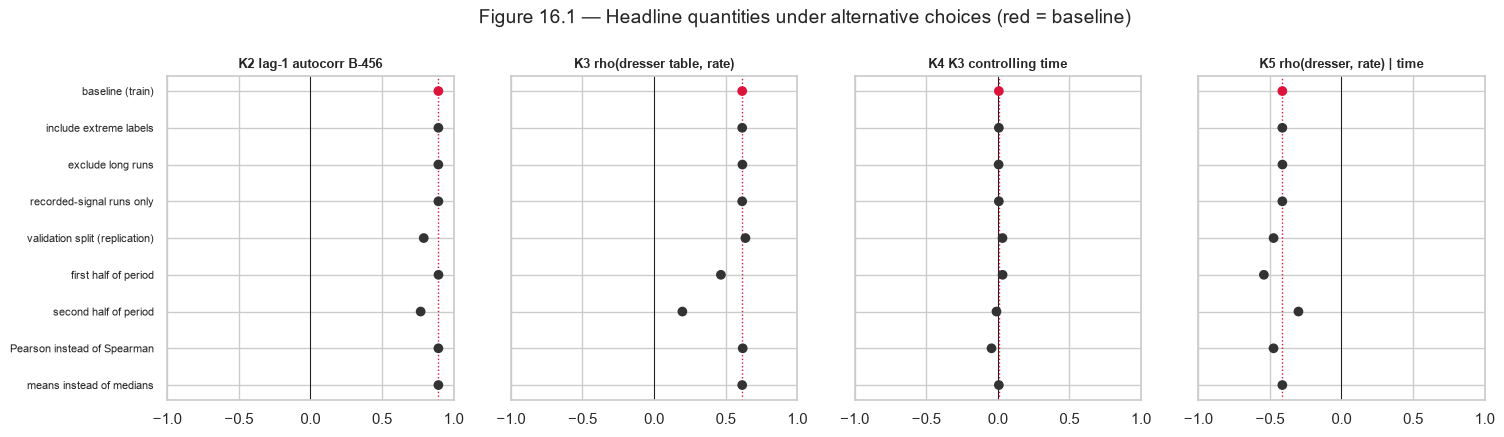

A-123 representativeness: median rate recorded 150.87 (n=185) vs unrecorded 151.59 (n=246), Mann-Whitney p = 0.030
Extreme labels by mode: {'A-123': 4}


In [45]:
def key_quantities(d, method='spearman', centre=np.median):
    corr_f = (lambda a, b: stats.spearmanr(a, b).statistic) if method == 'spearman' else (lambda a, b: stats.pearsonr(a, b).statistic)
    def part(x, y, z):
        if method == 'spearman': return partial_spearman(x, y, z)
        Z_ = np.c_[np.ones(len(z)), z]; ex = x - Z_ @ np.linalg.lstsq(Z_, x, rcond=None)[0]; ey = y - Z_ @ np.linalg.lstsq(Z_, y, rcond=None)[0]
        return np.corrcoef(ex, ey)[0, 1]
    b = d[d.MODE == 'B-456'].sort_values('T_START')
    yb = b[TARGET].values
    k6 = 0; ps = []; rs = []
    for m in MODES:
        s_ = d[d.MODE == m]; res = s_[TARGET] - s_.DRIFT_LEVEL
        for c in ANALYSIS_FEATURES:
            ok = s_[c].notna()
            if ok.sum() < 30 or s_.loc[ok, c].nunique() < 3: continue
            r_ = stats.spearmanr(s_.loc[ok, c], res[ok]) if method == 'spearman' else stats.pearsonr(s_.loc[ok, c], res[ok])
            ps.append(r_.pvalue); rs.append(r_.statistic)
    k6 = int(((bh(ps) < CONFIG['fdr_alpha']) & (np.abs(rs) >= CONFIG['min_abs_rho'])).sum())
    a1, a4 = d.loc[d.MODE == 'A-123', TARGET], d.loc[d.MODE == 'A-456', TARGET]
    return {'K1 rate ratio A-123/A-456': centre(a1) / centre(a4),
            'K2 lag-1 autocorr B-456': np.corrcoef(yb[:-1], yb[1:])[0, 1],
            'K3 rho(dresser table, rate)': corr_f(b.U_DRESSER_TABLE_START, b[TARGET]),
            'K4 K3 controlling time': part(b.U_DRESSER_TABLE_START.values, b[TARGET].values, b.T_START.values),
            'K5 rho(dresser, rate) | time': part(b.U_DRESSER_START.values, b[TARGET].values, b.T_START.values),
            'K6 meaningful detrended associations': k6}

all_dev = F[F.SPLIT.isin(['train', 'validation'])]
mid = tr.DAY.median()
variants = {
    'baseline (train)': (tr, {}),
    'include extreme labels': (all_dev[all_dev.SPLIT == 'train'], {}),
    'exclude long runs': (tr[~tr.LONG_RUN], {}),
    'recorded-signal runs only': (tr[tr.SIGNALS_RECORDED], {}),
    'validation split (replication)': (va, {}),
    'first half of period': (tr[tr.DAY <= mid], {}),
    'second half of period': (tr[tr.DAY > mid], {}),
    'Pearson instead of Spearman': (tr, {'method': 'pearson'}),
    'means instead of medians': (tr, {'centre': np.mean}),
}
robust = pd.DataFrame({k: key_quantities(d, **kw) for k, (d, kw) in variants.items()}).T
display(robust.round(3))

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, col in zip(axes, ['K2 lag-1 autocorr B-456', 'K3 rho(dresser table, rate)', 'K4 K3 controlling time', 'K5 rho(dresser, rate) | time']):
    v = robust[col]
    ax.scatter(v.values, range(len(v)), color=['crimson' if i == 0 else '#333' for i in range(len(v))], zorder=3)
    ax.axvline(0, color='k', lw=.7); ax.axvline(v.iloc[0], color='crimson', ls=':', lw=1)
    ax.set_title(col, fontsize=9); ax.set_xlim(-1, 1)
axes[0].set_yticks(range(len(robust))); axes[0].set_yticklabels(robust.index, fontsize=8); axes[0].invert_yaxis()
fig.suptitle('Figure 16.1 — Headline quantities under alternative choices (red = baseline)', y=1.04)
savefig(fig, '16_01_robustness')

a123 = dev[dev.MODE == 'A-123']
mw = stats.mannwhitneyu(a123.loc[a123.SIGNALS_RECORDED, TARGET], a123.loc[~a123.SIGNALS_RECORDED, TARGET])
print(f"A-123 representativeness: median rate recorded {a123.loc[a123.SIGNALS_RECORDED, TARGET].median():.2f} (n={a123.SIGNALS_RECORDED.sum()}) "
      f"vs unrecorded {a123.loc[~a123.SIGNALS_RECORDED, TARGET].median():.2f} (n={(~a123.SIGNALS_RECORDED).sum()}), Mann-Whitney p = {mw.pvalue:.3f}")
ext = F[F.LABEL_OUTLIER]
print('Extreme labels by mode:', ext.MODE.value_counts().to_dict())

**What held and what didn't.**
* **K1 (the 2× regime)** is stable under every variant. It is the most robust result in the notebook. Including the four extreme labels moves the *mean*-based ratio but not the median-based one, which is why medians are the default.
* **K2 (drift)** stays high in both halves of the period and in the validation replicate.
* **K3 → K4 (dresser table is a clock)**: in every variant, the raw correlation is large and the time-controlled one is near zero.
* **K5 (dresser wear)** stays negative in most variants, but its size varies between the two halves of the period. That is expected with only three replacement cycles, and it is why the dresser finding is labelled *suggestive* rather than established.
* **K6** is 0 in every training-based variant. The validation replicate flags 4 associations (§16 printout): two A-123 features based on only 34 runs, and two usage-counter increments in A-456 with |ρ| ≈ 0.31–0.34. None appear in the training data. With about 150 tests on smaller samples, isolated hits like these are expected, so the conclusion stands: no *robust* process-setting association survives drift removal.
* A-123 runs with recorded signals have a median rate less than 1 unit (0.5%) below the unrecorded runs. The difference is statistically detectable (p ≈ 0.03) but practically negligible, so analysing the recorded runs is unlikely to bias the A-123 comparisons.
* The four extreme labels all belong to A-123. Including them leaves every median-based quantity unchanged.

## 17. How predictable is removal rate? (validation-only modelling check)

Machine learning is not the goal of this notebook. A small, leakage-safe comparison shows how much each kind of information is worth, which sets expectations for Notebook 2. All models **fit on training runs** and are **scored on validation runs**. Test labels stay untouched.

| Model | Inputs |
|---|---|
| Mode median | mode only |
| Drift level | median of the 10 time-nearest training runs (same mode) |
| Ridge | mode + process settings + wear counters (median-imputed, standardised) |
| Gradient boosting (sensors) | same inputs as Ridge, plus missing-value handling |
| Gradient boosting (sensors, no clock) | without the dresser-table counter, duration and sample count |
| Gradient boosting (sensors + drift) | sensors + drift level |

The gradient-boosting settings are fixed sensible defaults. Five-fold cross-validation on training runs, grouped by wafer, gives a tuning-free estimate. Validation is used once per model.

In [46]:
MODEL_X = [c for c in ANALYSIS_FEATURES if c not in ('DURATION', 'N_SAMPLES')]
NO_CLOCK = [c for c in MODEL_X if not c.startswith('U_DRESSER_TABLE')]
def mode_dummies(d): return pd.get_dummies(d.MODE).reindex(columns=MODES, fill_value=0).astype(float)
def Xmat(d, cols): return pd.concat([d[cols], mode_dummies(d)], axis=1)
hgb = lambda: HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=20,
                                            l2_regularization=1.0, random_state=CONFIG['seed'])
specs = {
    'Mode median': None,
    'Drift level': None,
    'Ridge (sensors)': (lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25))), MODEL_X + ['DURATION', 'N_SAMPLES']),
    'GBM (sensors)': (hgb, MODEL_X + ['DURATION', 'N_SAMPLES']),
    'GBM (sensors, no clock)': (hgb, NO_CLOCK),
    'GBM (sensors + drift)': (hgb, MODEL_X + ['DURATION', 'N_SAMPLES', 'DRIFT_LEVEL']),
}
preds, cv_mae = {}, {}
gkf = GroupKFold(n_splits=5)
for name, spec in specs.items():
    if name == 'Mode median':
        preds[name] = va.MODE.map(tr.groupby('MODE')[TARGET].median()).values; cv_mae[name] = np.nan; continue
    if name == 'Drift level':
        preds[name] = va.DRIFT_LEVEL.values; cv_mae[name] = mean_absolute_error(tr[TARGET], tr.DRIFT_LEVEL); continue
    make, cols = spec
    Xt, Xv = Xmat(tr, cols), Xmat(va, cols)
    fold = []
    for a, b in gkf.split(Xt, groups=tr.WAFER_ID):
        fold.append(mean_absolute_error(tr[TARGET].iloc[b], make().fit(Xt.iloc[a], tr[TARGET].iloc[a]).predict(Xt.iloc[b])))
    cv_mae[name] = np.mean(fold)
    preds[name] = make().fit(Xt, tr[TARGET]).predict(Xv)

rng = np.random.default_rng(CONFIG['seed'])
bidx = rng.integers(0, len(va), (CONFIG['bootstrap_draws'], len(va)))
yv = va[TARGET].values
rows = []
for name, p_ in preds.items():
    err = np.abs(yv - p_); bmae = err[bidx].mean(axis=1)
    row = {'model': name, 'CV MAE (train, grouped)': cv_mae[name], 'validation MAE': err.mean(),
           'MAE 95% CI': f'[{np.quantile(bmae, .025):.2f}, {np.quantile(bmae, .975):.2f}]',
           'validation RMSE': np.sqrt(mean_squared_error(yv, p_)), 'validation R² (overall)': r2_score(yv, p_)}
    for m in MODES:
        k_ = (va.MODE == m).values; row[f'MAE {m}'] = mean_absolute_error(yv[k_], p_[k_])
    rows.append(row)
model_table = pd.DataFrame(rows).set_index('model')
model_table.to_csv(OUT / 'validation_model_check.csv')
display(model_table.round(3))

,"CV MAE (train, grouped)",validation MAE,MAE 95% CI,validation RMSE,validation R² (overall),MAE A-123,MAE A-456,MAE B-456
model,,,,,,,,
Mode median,NaN,6.048,"[5.58, 6.52]",7.872,0.925,3.191,5.548,7.7
Drift level,2.526,2.502,"[2.29, 2.73]",3.428,0.986,2.257,2.407,2.7
Ridge (sensors),4.483,4.761,"[4.46, 5.07]",5.772,0.96,4.347,4.359,5.354
GBM (sensors),2.544,2.467,"[2.27, 2.69]",3.256,0.987,2.275,2.353,2.663
"GBM (sensors, no clock)",2.842,2.7,"[2.47, 2.95]",3.656,0.984,2.52,2.498,2.988
GBM (sensors + drift),2.316,2.413,"[2.21, 2.62]",3.237,0.987,2.317,2.173,2.707


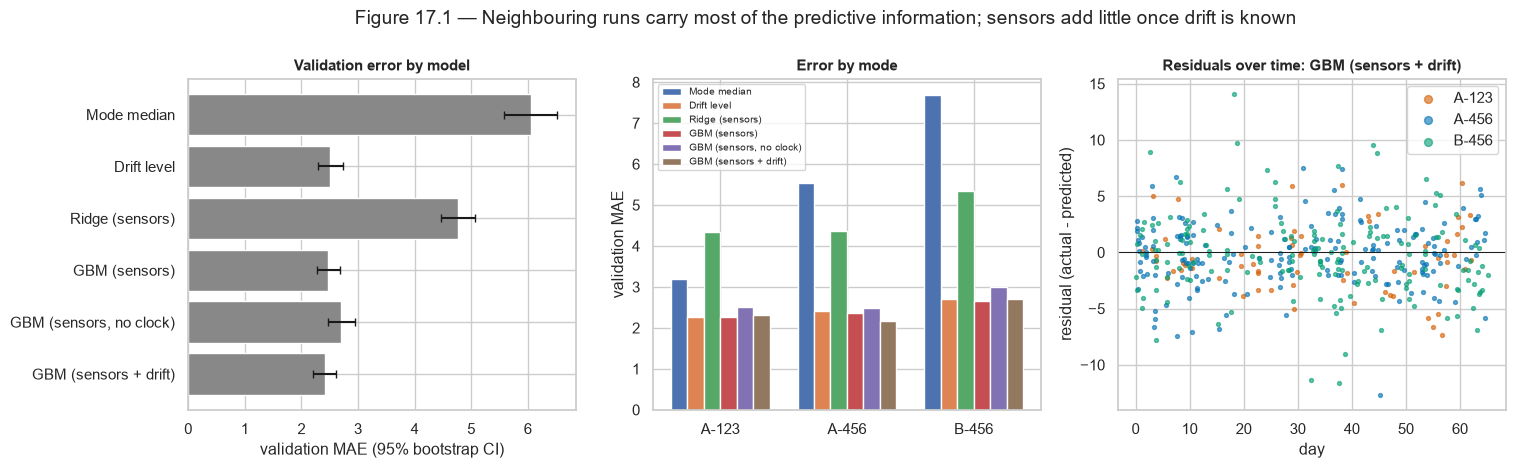

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
mt = model_table
lo = [float(s_.strip('[]').split(',')[0]) for s_ in mt['MAE 95% CI']]; hi = [float(s_.strip('[]').split(',')[1]) for s_ in mt['MAE 95% CI']]
axes[0].barh(mt.index, mt['validation MAE'], xerr=[mt['validation MAE'] - lo, np.array(hi) - mt['validation MAE']], color='#888', capsize=3)
axes[0].invert_yaxis(); axes[0].set_xlabel('validation MAE (95% bootstrap CI)'); axes[0].set_title('Validation error by model')
x = np.arange(len(MODES)); w = .13
for i, name in enumerate(mt.index):
    axes[1].bar(x + (i - 2.5) * w, [mt.loc[name, f'MAE {m}'] for m in MODES], w, label=name)
axes[1].set_xticks(x); axes[1].set_xticklabels(MODES); axes[1].set_ylabel('validation MAE'); axes[1].set_title('Error by mode'); axes[1].legend(fontsize=7)
best_name = mt['validation MAE'].idxmin()
res = yv - preds[best_name]
for m in MODES:
    k_ = (va.MODE == m).values
    axes[2].scatter(va.DAY.values[k_], res[k_], s=8, alpha=.6, color=MODE_COLORS[m], label=m)
axes[2].axhline(0, color='k', lw=.7); axes[2].set_xlabel('day'); axes[2].set_ylabel('residual (actual - predicted)')
axes[2].set_title(f'Residuals over time: {best_name}'); axes[2].legend(markerscale=2)
fig.suptitle('Figure 17.1 — Neighbouring runs carry most of the predictive information; sensors add little once drift is known', y=1.04)
savefig(fig, '17_01_model_check')

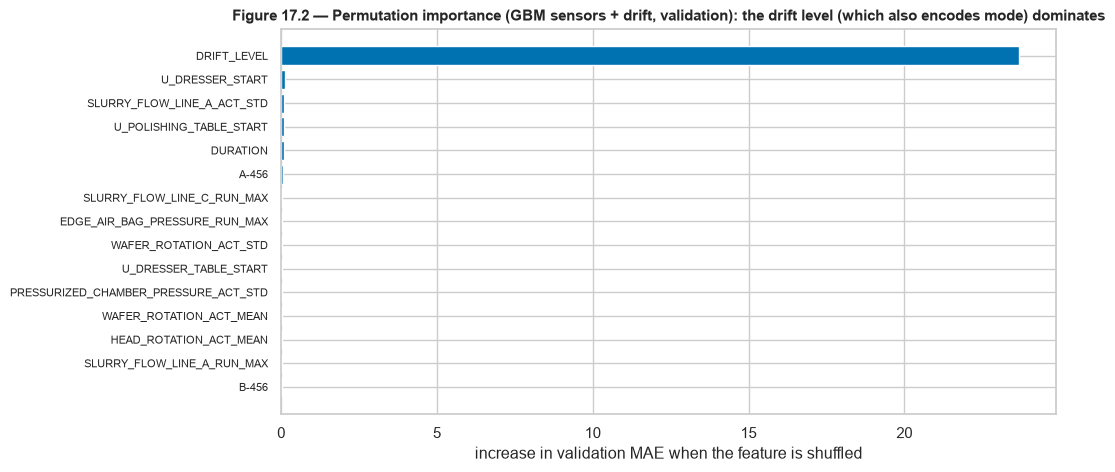

In [48]:
cols = specs['GBM (sensors + drift)'][1]
mdl = specs['GBM (sensors + drift)'][0]().fit(Xmat(tr, cols), tr[TARGET])
pi = permutation_importance(mdl, Xmat(va, cols), va[TARGET], n_repeats=10, random_state=CONFIG['seed'], scoring='neg_mean_absolute_error')
imp = pd.Series(pi.importances_mean, index=Xmat(va, cols).columns).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(imp.index[::-1], imp.values[::-1], color='#0072B2'); ax.set_xlabel('increase in validation MAE when the feature is shuffled')
ax.set_title('Figure 17.2 — Permutation importance (GBM sensors + drift, validation): the drift level (which also encodes mode) dominates')
ax.tick_params(axis='y', labelsize=8)
savefig(fig, '17_02_permutation_importance')

**Interpretation.**
* **Mode alone** is a weak baseline (MAE ≈ 6). The **drift level alone**, with no sensors at all, cuts the error by more than half (MAE ≈ 2.5).
* **Gradient boosting on sensors** matches the drift level (MAE ≈ 2.5), largely by exploiting clock-like features and the dresser counter to rebuild the time trend. Removing the dresser-table counter, duration and sample count raises its error to about 2.7.
* **Sensors + drift** is only marginally better than either alone (MAE ≈ 2.4, overlapping CIs). Permutation importance (Figure 17.2) is dominated by the drift level, which also encodes the mode level, so the mode dummies add nothing on top. Dresser usage is the most useful sensor feature, at a distant second.
* Residuals of the best model cluster in time (Figure 17.1, right): the remaining errors are concentrated in periods of rapid change, where the drift estimate lags.

**What this means for virtual metrology on this tool.** Prediction quality depends on having recent measured rates. Without them, the recorded sensors can only explain the regime (mode) and some wear-related trend. These numbers are optimistic for real deployment, because validation runs are interleaved in time with training runs. A *forward-in-time* evaluation would be the honest next test.

## 18. Findings → recommendations

| # | Evidence | Proposed action | Who | Success metric | Risks / constraints | How to validate |
|---|---|---|---|---|---|---|
| 1 | A-123 runs are 2× faster; no recorded setting explains it (§10, §16 K1) | Treat the 1-2-3 route as a separate regime in all monitoring and models; find out what differs (pad, slurry, layer) and add it to the log | Process engineering | Every model and SPC chart is mode-specific; the difference is documented | The difference may be intentional (different product) | Confirm with the recipe owner; check whether the 2× gap persists after logging the new field |
| 2 | Rate drifts with lag-1 autocorrelation ≈ 0.87–0.90 (§11) | Monitor a rolling removal-rate level per mode (control chart on the drift level), not just per-run limits | Process control / metrology | Earlier detection of level shifts; fewer out-of-spec wafers | Requires timely metrology feedback | Back-test alarm timing against the shifts in Figure 11.1 |
| 3 | Dresser wear is associated with lower rate; shifts at dresser replacements (§12) | Study the dresser replacement interval: compare rate decline per dresser-usage unit across cycles, then pilot a shorter interval on one route | Equipment engineering | Smaller rate sag late in the dresser cycle; lower within-mode variance | Only 3 cycles observed; replacement cost | Prospective comparison over several cycles; check other explanations such as slurry lot changes |
| 4 | Dresser-table usage looks predictive but is a clock (§12, §15) | Exclude monotone counters from predictive models, or include time explicitly | Data science | Models keep their accuracy when time-proxy features are removed | — | Forward-in-time validation |
| 5 | ~Half of A-123 runs have no pressure/rotation logged (§5.9) | Fix logging for chambers 1–3 | Equipment / IT | 100% of runs with recorded signals | — | Audit the next month of logs |
| 6 | Process settings carry little run-level signal once drift is known (§13, §17) | Use virtual metrology with drift tracking (recent measured rates), and treat sensor-only predictions as unreliable within a mode | Data science / metrology | Validated MAE on a forward-in-time split | Needs metrology data flow | Notebook 2 + a forward-in-time split |

## 19. Limitations and next steps

**What could change these conclusions**
* **Observational data.** Settings were chosen by recipes and engineers, never randomised, so no association here is a causal effect.
* **No units, anonymised signals.** The physical meaning of several channels is inferred (§7). A mislabelled channel would change the Preston analysis.
* **One machine, 65 days, three dresser cycles.** The dresser finding rests on three replacement events, and seasonality or longer cycles cannot be seen.
* **Benchmark splits are interleaved in time**, so validation results overstate future performance.
* **About half of A-123 runs lack process signals**, so A-123 process analysis rests on fewer runs.
* **Label meaning.** The label is a run-average removal rate. Within-wafer uniformity and the measurement method are unknown.

**What would resolve the uncertainty**
1. Add the missing context to the log: pad/slurry lot, recipe ID, the layer polished, and A-123 sensor logging.
2. A forward-in-time evaluation (train on days 0–45, test on 45–65), done in Notebook 2 as an additional protocol.
3. More dresser cycles, or a planned replacement-interval experiment, to confirm the wear effect.
4. Metrology timestamps, to model how quickly measured rates become available for drift tracking.

## 20. Deliverables

The run-level table is written **without the target**; labels go to a separate file, so Notebook 2 can keep test labels sealed until its final evaluation.

In [49]:
keep = ['RUN_ID', 'SPLIT', 'WAFER_ID', 'STAGE', 'MODE', 'STEP_SEQUENCE', 'T_START', 'DAY', 'SIGNALS_RECORDED', 'LONG_RUN', 'LABEL_OUTLIER', 'DRIFT_LEVEL'] + FEATURES
F[keep].to_csv(OUT / 'run_features.csv', index=False)
F[['RUN_ID', 'SPLIT', 'WAFER_ID', 'STAGE', 'MODE', TARGET, 'LABEL_OUTLIER']].to_csv(OUT / 'labels.csv', index=False)
cleaning_log.to_csv(OUT / 'cleaning_log.csv', index=False)
pd.DataFrame(ratios).to_csv(OUT / 'mode_comparison.csv', index=False)
robust.to_csv(OUT / 'robustness.csv')
json.dump({'config': CONFIG, 'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
           'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__, 'rows_raw': int(len(raw)), 'rows_clean': int(len(clean)),
           'runs': int(len(F))}, open(OUT / 'run_metadata.json', 'w'), indent=2)
files = sorted(p for p in OUT.rglob('*') if p.is_file())
print(f'{len(files)} files in outputs/ ({sum(p.stat().st_size for p in files) / 1e6:.1f} MB), including {len(list(FIG.glob("*.png")))} figures:')
for p in files:
    if p.parent == OUT: print(f'  {p.name:38s} {p.stat().st_size / 1024:8.0f} KB')

42 files in outputs/ (8.2 MB), including 31 figures:
  cleaning_log.csv                              0 KB
  feature_dictionary.csv                        5 KB
  feature_target_correlations.csv              28 KB
  file_manifest.csv                            63 KB
  issue_register.csv                            1 KB
  labels.csv                                  127 KB
  mode_comparison.csv                           2 KB
  robustness.csv                                1 KB
  run_features.csv                           2273 KB
  run_metadata.json                             1 KB
  validation_model_check.csv                    1 KB


### Numbers behind the executive summary
This cell recomputes every number quoted in the executive summary from this run.

In [50]:
summary_numbers = {
    'runs (all splits)': len(F), 'runs in analysis set (train+val)': len(dev),
    'median rate A-123 / A-456 / B-456': [round(dev.loc[dev.MODE == m, TARGET].median(), 1) for m in MODES],
    'rate ratio A-123/A-456': round(ratios.loc[0, 'ratio A-123 / A-456'], 2),
    'active-time ratio A-123/A-456': round(ratios.set_index('quantity').loc['ACTIVE_TIME', 'ratio A-123 / A-456'], 2),
    'lag-1 autocorrelation by mode': drift_table['lag-1 autocorrelation'].round(2).to_dict(),
    'validation R² of drift level by mode': drift_table['validation R² of drift level'].round(2).to_dict(),
    'meaningful associations raw / after drift removal': (int(corr.meaningful.sum()), int(corr.meaningful_detrended.sum()), len(corr)),
    'max |rho| after drift removal': round(corr.rho_detrended.abs().max(), 3),
    'dresser-table rho raw -> controlling time (B-456)': (round(robust.loc['baseline (train)', 'K3 rho(dresser table, rate)'], 2), round(robust.loc['baseline (train)', 'K4 K3 controlling time'], 2)),
    'dresser rho controlling time (B-456)': round(robust.loc['baseline (train)', 'K5 rho(dresser, rate) | time'], 2),
    'wear-only validation R² by mode': wear_expl.loc['dresser + backing film + polishing table'].round(2).to_dict(),
    'validation MAE: mode median / drift / GBM sensors / GBM sensors+drift': [round(model_table.loc[k, 'validation MAE'], 2) for k in ['Mode median', 'Drift level', 'GBM (sensors)', 'GBM (sensors + drift)']],
    'A-123 runs without recorded signals': int((~F[F.MODE == 'A-123'].SIGNALS_RECORDED).sum()),
}
for k, v in summary_numbers.items(): print(f'{k:68s} {v}')
json.dump({k: (v if not isinstance(v, (np.integer, np.floating)) else v.item()) for k, v in summary_numbers.items()},
          open(OUT / 'summary_numbers.json', 'w'), indent=2, default=float)

runs (all splits)                                                    2829
runs in analysis set (train+val)                                     2401
median rate A-123 / A-456 / B-456                                    [np.float64(151.2), np.float64(74.0), np.float64(81.6)]
rate ratio A-123/A-456                                               2.04
active-time ratio A-123/A-456                                        0.55
lag-1 autocorrelation by mode                                        {'A-123': 0.67, 'A-456': 0.87, 'B-456': 0.9}
validation R² of drift level by mode                                 {'A-123': 0.47, 'A-456': 0.78, 'B-456': 0.84}
meaningful associations raw / after drift removal                    (11, 0, 150)
max |rho| after drift removal                                        0.205
dresser-table rho raw -> controlling time (B-456)                    (np.float64(0.62), np.float64(0.01))
dresser rho controlling time (B-456)                                 -0.41
wear-only va

## Appendix A — Every process signal during polishing, by mode

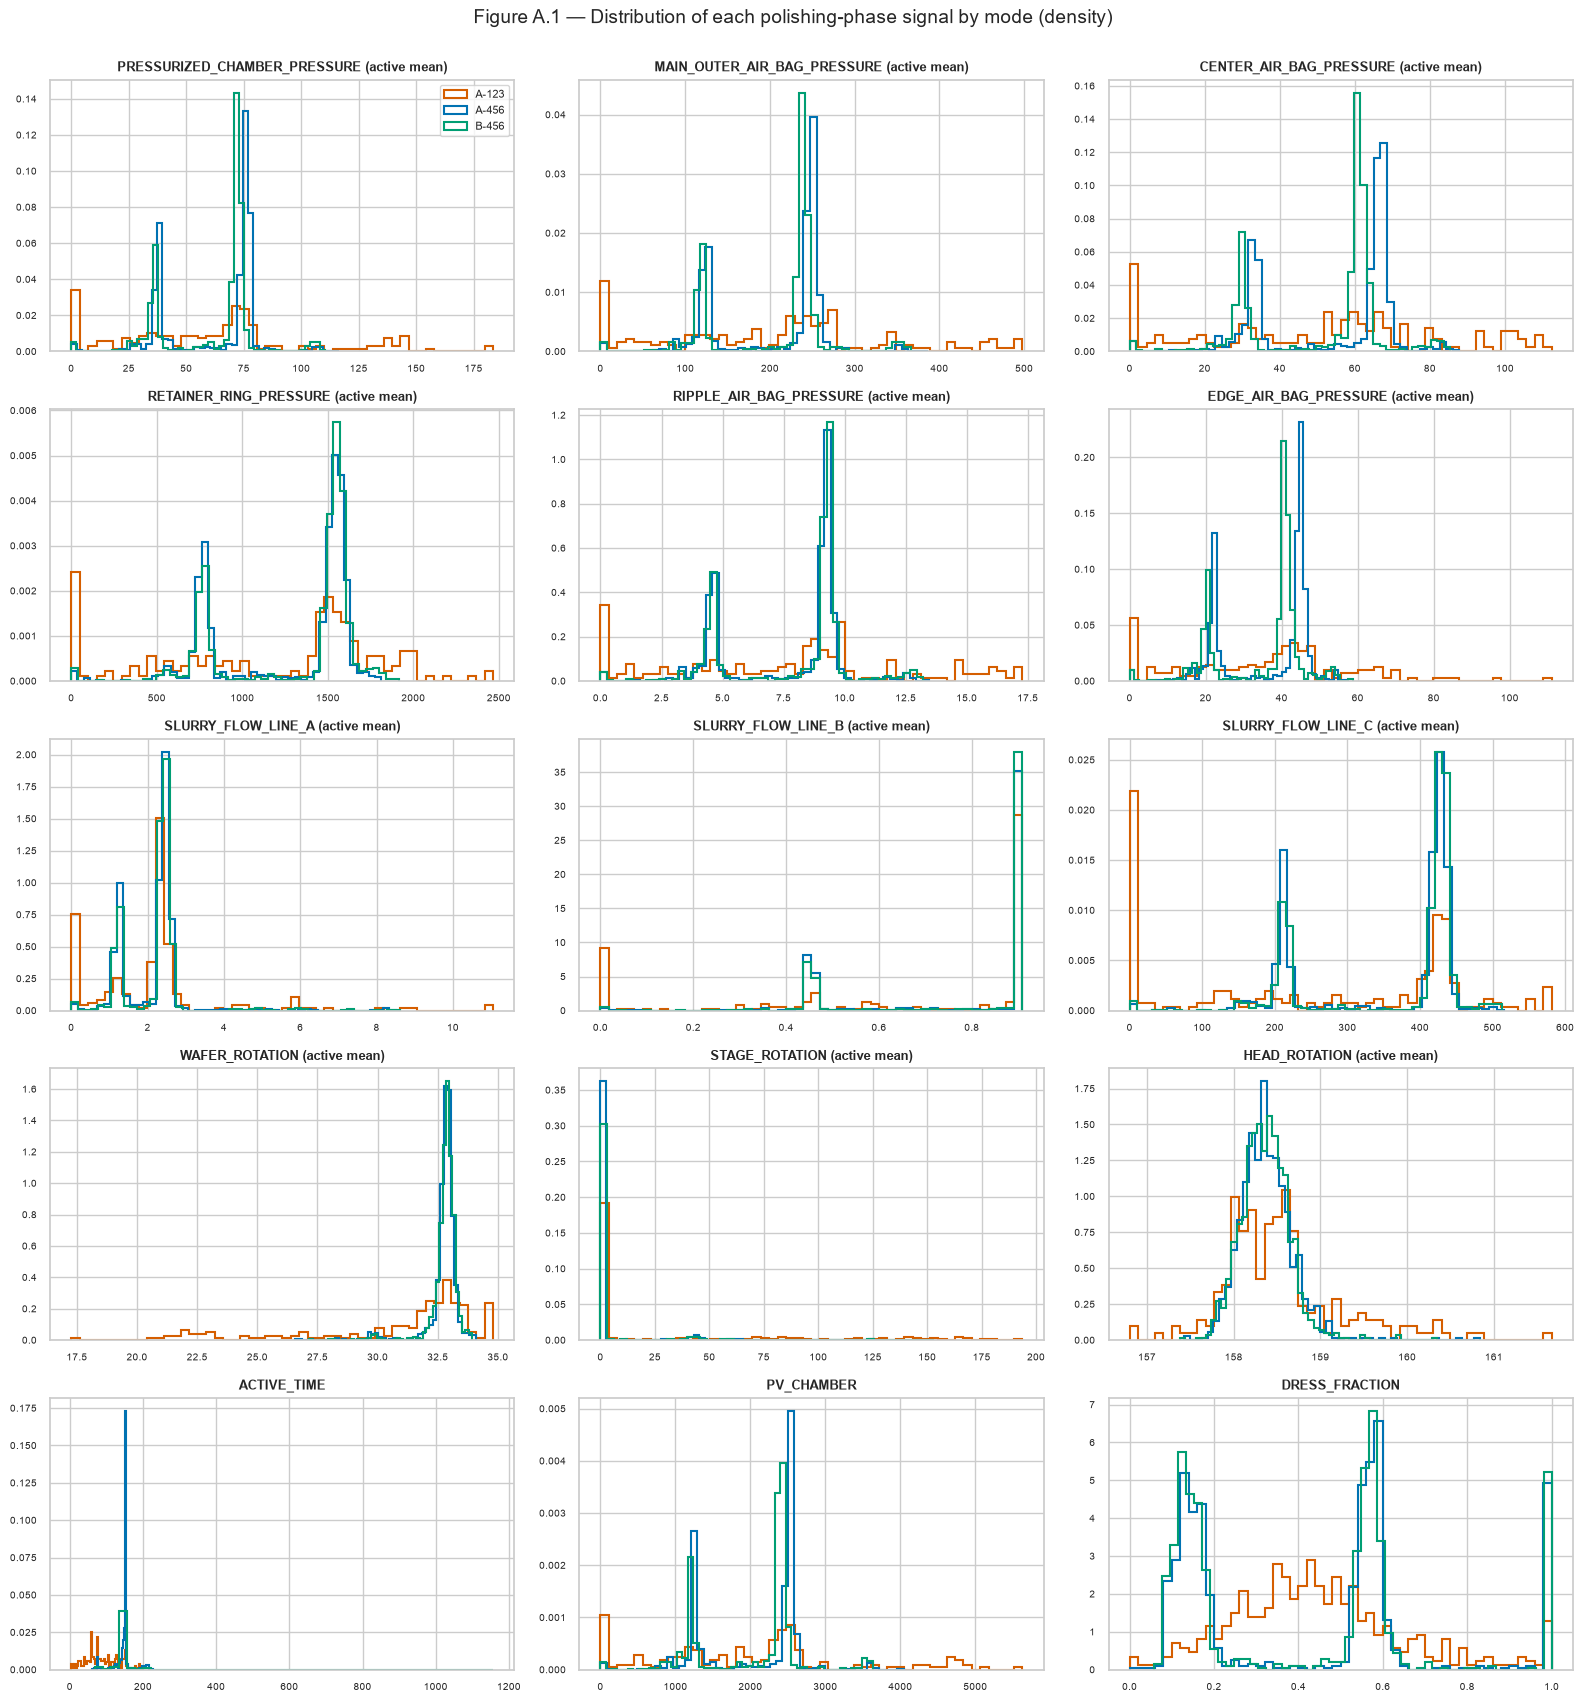

In [51]:
sig = [f'{c}_ACT_MEAN' for c in PROCESS] + ['ACTIVE_TIME', 'PV_CHAMBER', 'DRESS_FRACTION']
fig, axes = plt.subplots(5, 3, figsize=(16, 17))
for ax, c in zip(axes.ravel(), sig):
    for m in MODES:
        v = dev.loc[dev.MODE == m, c].dropna()
        if len(v) and v.std() > 0: ax.hist(v, bins=50, histtype='step', lw=1.5, color=MODE_COLORS[m], label=m, density=True)
    ax.set_title(c.replace('_ACT_MEAN', ' (active mean)'), fontsize=9); ax.tick_params(labelsize=7)
axes[0, 0].legend(fontsize=8)
fig.suptitle('Figure A.1 — Distribution of each polishing-phase signal by mode (density)', y=1.0)
fig.tight_layout(); savefig(fig, 'A_01_signals_by_mode')

Most signals sit in narrow peaks, the fixed set-points discussed in §14. A-123 is shifted lower on several pressures and on active time, consistent with §10.

## Appendix B — Full within-mode correlation table
The complete table, with raw and drift-adjusted Spearman ρ and BH q-values for every feature × mode, is saved as `outputs/feature_target_correlations.csv`. The 15 largest drift-adjusted associations:

In [52]:
display(corr.sort_values('rho_detrended', key=abs, ascending=False).head(15)[['mode', 'feature', 'n', 'rho', 'q', 'rho_detrended', 'q_detrended']].round(4))

,mode,feature,n,rho,q,rho_detrended,q_detrended
75,A-456,SLURRY_FLOW_LINE_A_ACT_STD,798,-0.0636,0.1872,-0.2048,0
124,B-456,SLURRY_FLOW_LINE_A_ACT_STD,815,-0.1124,0.0066,-0.1935,0
37,A-123,HEAD_ROTATION_ACT_MEAN,182,-0.1741,0.0639,-0.1908,0.1366
35,A-123,STAGE_ROTATION_ACT_STD,182,-0.2664,0.0017,-0.1883,0.1366
34,A-123,STAGE_ROTATION_ACT_MEAN,182,-0.256,0.0028,-0.1771,0.1795
38,A-123,HEAD_ROTATION_ACT_STD,182,-0.1889,0.0408,-0.1681,0.2332
123,B-456,SLURRY_FLOW_LINE_A_ACT_MEAN,815,-0.118,0.0039,-0.1622,0.0002
22,A-123,SLURRY_FLOW_LINE_A_ACT_MEAN,182,-0.109,0.3065,-0.1615,0.2447
31,A-123,WAFER_ROTATION_ACT_MEAN,182,0.2689,0.0015,0.1558,0.2816
27,A-123,SLURRY_FLOW_LINE_B_RUN_MAX,364,-0.18,0.0031,-0.1363,0.1366
